# Polymarket 15-minute crypto Up/Down: a momentum trigger, lifted at 250 ms, held to expiry

## S0 · Summary

**Research question.** On Polymarket's 15-minute Up/Down markets of BTC, ETH, SOL and XRP, can a simple momentum signal read from Binance trades find a direction with a high win rate that stays above the break-even win rate of what it pays, after the taker fee, when it lifts the ask 250 ms after the signal and holds to expiry?

| Trade set-up | |
|---|---|
| What is the trade | When the move since the window start, in units of its own volatility, is large and the last few seconds agree with it, buy that side's token at the ask and hold it until the market pays 1 or 0 |
| Venue | Polymarket (CLOB), the 15-minute crypto Up/Down markets; Binance spot trades are the input only |
| Type of risk | The move reverses before the end, the ask moves away in the 250 ms between signal and book, and the fee: heaviest near 50 cents |
| Rules | Paper only. USD 20 a trade, USD 1,000 book, no leverage, no compounding, no stops, one entry per window, no entry in the last minute |
| Base test | On the two test days, the day-1 rule chosen on the validation days: is the win rate above the break-even win rate of its own fills, and is the net PnL per entry above zero? (S3) |
| Test 1 | Is it real: the baseline with no momentum gate, a favourite-by-mid rule, random entry times, and the planted look-ahead tests? (S4) |
| Test 2 | What does 250 ms cost: the latency table, the ask's move after the signal, partial fills? (S4, S5) |

The result and its gates are rendered by the last cells (S7, then the Research summary). The pre-registration is `um-003` on the predmkts desk (committed before any run of this design); what changed from the earlier registrations is written in the ledger.

In [1]:
# ---- pre-registered refusals, fixed BEFORE this design ran (ledger um-003), printed here and read by the decision rule in S6 ----
from IPython.display import Markdown, display
FALSIFIER = [
    {"id": "F1", "ends_if": "on the test days the win rate is not above the break-even win rate of its own fills with a Wilson interval that excludes it", "read_in": "S3"},
    {"id": "F2", "ends_if": "the net PnL per entry on the test days is zero or below, or its slot-cluster interval includes zero", "read_in": "S3, S4"},
    {"id": "F3", "ends_if": "the momentum probability loses to the Polymarket mid on Brier at the triggered instants of the test days", "read_in": "S3"},
    {"id": "F4", "ends_if": "a planted leak is not flagged, or shuffled outcomes keep an edge, or the features are not time-aligned (the gain from showing them the future does not grow with the shift, reaching 2 standard errors by 15 s)", "read_in": "S4"},
]
display(Markdown("**Falsifier, written before the run.** With two test days, one regime and a grid chosen on two validation days, a pass here is one result, not an expectation; any line below ends the study with NO SIZE.\n\n"
                 "| Id | The study ends if | Read in |\n|---|---|---|\n" + "\n".join(f"| {f['id']} | {f['ends_if']} | {f['read_in']} |" for f in FALSIFIER)))
display(Markdown("F4 first read 'features one second from the future must help'. On the gate day (2026-10-03, a validation day) that one-second test turned out to have no power for a signal that reads the move since the start (+0.18 USD per entry against a standard error of 0.71), while 5, 15 and 60 seconds gain steadily. The clause was replaced by the dose-response BEFORE any configuration was chosen or any test day read; the one-second test is still run and reported in S4.3 as registered, and G6 is a FLAG, not a PASS, when it is the only check that fails."))

**Falsifier, written before the run.** With two test days, one regime and a grid chosen on two validation days, a pass here is one result, not an expectation; any line below ends the study with NO SIZE.

| Id | The study ends if | Read in |
|---|---|---|
| F1 | on the test days the win rate is not above the break-even win rate of its own fills with a Wilson interval that excludes it | S3 |
| F2 | the net PnL per entry on the test days is zero or below, or its slot-cluster interval includes zero | S3, S4 |
| F3 | the momentum probability loses to the Polymarket mid on Brier at the triggered instants of the test days | S3 |
| F4 | a planted leak is not flagged, or shuffled outcomes keep an edge, or the features are not time-aligned (the gain from showing them the future does not grow with the shift, reaching 2 standard errors by 15 s) | S4 |

F4 first read 'features one second from the future must help'. On the gate day (2026-10-03, a validation day) that one-second test turned out to have no power for a signal that reads the move since the start (+0.18 USD per entry against a standard error of 0.71), while 5, 15 and 60 seconds gain steadily. The clause was replaced by the dose-response BEFORE any configuration was chosen or any test day read; the one-second test is still run and reported in S4.3 as registered, and G6 is a FLAG, not a PASS, when it is the only check that fails.

## S1 · Setup

### S1.1 · Parameters

Every knob that is ours is in the one cell below; nothing else is edited to change a run. Venue numbers (fee, minimum order, tick) are read from each market's own row in S1.3, never typed here.

In [2]:
# ---- parameters: ours, never a venue number ----
STUDY_ID = "2026-10-07-predmkts-binance-polymarket-crypto-15m-latency"      # the notebook's file stem
RUN_ID = "um-003"                                           # the pre-registration on lab/predmkts (committed before the run)
KIND, DESK = "strategy", "lab/predmkts"
TITLE = "Polymarket 15-minute crypto Up/Down: a momentum trigger lifted at 250 ms"
QUESTION = ("On Polymarket's 15-minute Up/Down markets, does a Binance momentum trigger with a calibrated probability win more often than the break-even "
            "win rate of its fills, after the taker fee, when it lifts the ask 250 ms after the signal and holds to expiry?")
ASSETS = ("btc", "eth", "sol", "xrp")                       # custom: the four assets the owner named
FIT_DAYS = ("2026-09-30", "2026-10-01", "2026-10-02")       # custom: the probability maps and nothing else are fitted here (Binance only)
VAL_DAYS = ("2026-10-03", "2026-10-04")                     # custom: the configuration is chosen here
TEST_DAYS = ("2026-10-05", "2026-10-06")                    # custom: read once, for the one chosen configuration
SMOKE_HOUR = ("2026-10-05T12:00:00Z", "2026-10-05T13:00:00Z")   # custom: the 16 windows an engine smoke test looked at before registration, excluded from the test read
BOOK_USD, CLIP_USD = 1000.0, 20.0                           # owner: the book and the USD a trade, no leverage, no compounding, no stops
LATENCY_MS = 250                                            # owner: signal to the book we hit (the venue's own taker delay is inside it, S1.4)
T_MIN_S, OPEN_S = 60, 10                                    # custom [U]: no entry in the last minute, none in the first 10 s
Z_MINS = (0.5, 1.0, 1.5, 2.0, 3.0)                          # custom [U]: the signal threshold grid
LOOKBACKS = (10, 30, 60)                                    # custom [U]: the lookback (s) that must agree with the move
THETAS = (0.0, 0.03, 0.06)                                 # custom [U]: edge after fee the probability must clear
MAPS = ("brownian", "logit", "table")                       # custom: the probability maps
MIN_ENTRIES = 100                                           # custom: a validation configuration needs this many entries to be chosen
LATENCIES = (0, 150, 250, 400, 1000)                        # custom: the latency sensitivity (ms)
SEED = 7

In [3]:
import datetime as dt, json, math, time
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from IPython import get_ipython
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, report as REPORT, summary_card
from fundplat.data import handle as HANDLE
from fundplat.data.predmkts import updown15
import updown15_day as D
import updown15_figs as FG
import updown15_run as R
import updown15_runner as RUN
import updown15_stats as ST
import updown15_verify as VF
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
globals().update(figstyle.NAMES)
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "font.size": 9.5, "axes.axisbelow": True,
                     "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
# the run IS the defaults it claims (a config cell asserts it)
assert (R.LATENCY_MS, R.CLIP_USD, R.TMIN_S, R.OPEN_S) == (LATENCY_MS, CLIP_USD, T_MIN_S, OPEN_S), "the engine's defaults are not this study's parameters"
assert (R.Z_MINS, R.LB, R.THETAS, R.MAPS, R.LATENCIES) == (Z_MINS, LOOKBACKS, THETAS, MAPS, LATENCIES), "the engine's grid is not this study's grid"
CFGS = R.configs()
N_TRIALS = len(CFGS)
DAYS_ALL = FIT_DAYS + VAL_DAYS + TEST_DAYS
assert len(set(DAYS_ALL)) == 7 and max(FIT_DAYS) < min(VAL_DAYS) and max(VAL_DAYS) < min(TEST_DAYS), "the split is not walk-forward by day"
FIGURES = []
GATES = []
VERIFY = {"suite": "updown15 planted tests", "passed": 0, "total": 0, "books": 0}
CAVEATS = []
usd = lambda v, d=0: f"USD {v:,.{d}f}"
sgn = lambda v, d=0: f"{v:+,.{d}f}"
pct = lambda v, d=1: f"{v * 100:.{d}f}%"
ms_ = lambda s: int(dt.datetime.fromisoformat(s.replace("Z", "+00:00")).replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
iso_ = lambda ms: dt.datetime.fromtimestamp(ms / 1000, dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
print(f"{N_TRIALS} configurations in the grid ({len([c for c in CFGS if c['family'] == 'baseline'])} baseline, {len([c for c in CFGS if c['family'] == 'momentum'])} momentum)")

138 configurations in the grid (3 baseline, 135 momentum)


### S1.2 · The data, and what it can support

Every input is requested through `fundplat.data`; the notebook reads only DERIVED DAYS, one pinned bundle per UTC day built by `updown15_runner` from the Binance trades and the exact Polymarket ladders (the raw files are temporary and removed by the pipeline itself). A re-run of this notebook pulls nothing.

In [4]:
print("reading the derived days through the data layer:", ", ".join(DAYS_ALL))
BLOB = {d: RUN.seated(d) for d in DAYS_ALL}
INV = []
for d in DAYS_ALL:
    b = BLOB[d]
    if b is None:
        INV.append(dict(day=d, role="MISSING", markets=None, bytes=None))
        continue
    a_, m_ = D.unpack(b)
    INV.append(dict(day=d, role=m_["role"], markets=int(len(a_["w_start"])), ok=int((a_["w_status"] == 0).sum()) if m_["role"] == "book" else None,
                    no_book=int((a_["w_status"] == 1).sum()) if m_["role"] == "book" else None, binance_gap=int((a_["w_status"] == 2).sum()) if m_["role"] == "book" else None,
                    config_rows=int(len(a_["c_w"])) if m_["role"] == "book" else None, bytes=len(b), code=m_.get("code"), seconds=m_["audit"].get("seconds")))
INV = pd.DataFrame(INV)
display(HTML(INV.to_html(index=False, border=0, na_rep="")))
MISSING = [d for d in DAYS_ALL if BLOB[d] is None]
for d in MISSING:
    print(f"!!! DAY MISSING OR FAILED: {d} has no derived bundle; run `python updown15_runner.py run {d}` first")
FIRST_CUT = bool(MISSING)                        # a book day is not derived yet: this run is the first cut, the cells that need the ladders wait
assert not [d for d in MISSING if d in FIT_DAYS], "a fit day is missing: the maps cannot be fitted"
if FIRST_CUT:
    print(f"FIRST CUT: {len(MISSING)} book day(s) not derived yet ({', '.join(MISSING)}); every cell that needs the pinned ladders waits for them")
ROLE_OK = {d: INV.set_index("day").loc[d, "role"] for d in DAYS_ALL}
assert all(ROLE_OK[d] == "fit" for d in FIT_DAYS) and all(ROLE_OK[d] in ("book", "MISSING") for d in VAL_DAYS + TEST_DAYS), ROLE_OK
DAYS_HAVE = [d for d in DAYS_ALL if BLOB[d] is not None]
DAY = {d: D.unpack(BLOB[d]) for d in DAYS_HAVE}
VAL = [DAY[d] for d in VAL_DAYS if d in DAY]
TEST = [DAY[d] for d in TEST_DAYS if d in DAY]
DER_BYTES = int(INV["bytes"].sum())

reading the derived days through the data layer: 2026-09-30, 2026-10-01, 2026-10-02, 2026-10-03, 2026-10-04, 2026-10-05, 2026-10-06


day,role,markets,ok,no_book,binance_gap,config_rows,bytes,code,seconds
2026-09-30,fit,384,,,,,2334937,run-2026-10-07f,10.6
2026-10-01,fit,384,,,,,2292417,run-2026-10-07f,8.0
2026-10-02,fit,384,,,,,2352914,run-2026-10-07f,8.9
2026-10-03,book,384,361.0,21.0,2.0,49818.0,12931466,run-2026-10-07f,123.0
2026-10-04,book,384,360.0,22.0,2.0,49680.0,14809269,run-2026-10-07f,94.1
2026-10-05,book,384,365.0,19.0,0.0,50370.0,20743699,run-2026-10-07f,143.2
2026-10-06,book,384,356.0,28.0,0.0,49128.0,18939900,run-2026-10-07f,138.7


### S1.3 · The model and the signals

*Read this first. It is the whole model in plain words.*

**What the market asks.** A 15-minute market names one asset and one quarter hour. It pays 1 on "Up" if the Chainlink 60-second time-weighted price (TWAP) at the end of the quarter hour is at or above the same TWAP at its start, and 1 on "Down" otherwise. The price to beat is therefore the average of the last 60 seconds before the start, known the moment the window opens; the final price is the average of the last 60 seconds before the end. We do not have Chainlink's stream, so S2 measures how well the same two averages built from Binance trades reproduce the recorded outcome.

**The momentum signal.** Four steps, all from Binance trades up to the decision instant `t` and nothing later:

1. *Where is the price against the price to beat.* `S(t)` is the trade-implied mid (the last aggressive buy and sell prices, averaged while both are under 2 s old, else the last trade: a proxy, never a quote). `A0` is the 60-second average at the start. The move is `ln(S(t) / A0)`.
2. *How big is that move for this asset right now.* `sigma` is the per-second volatility from an exponentially weighted average (half-life 300 s) of squared 10-second log returns, read at `t`. A random walk with that volatility moves about `sigma x sqrt(t_elapsed)` in `t_elapsed` seconds, so the **z-score** is `z = ln(S(t) / A0) / (sigma x sqrt(t_elapsed))`. A z of 2 means the price is two typical moves away from where it started.
3. *Is the last stretch going the same way.* The lookback return `r_L = ln(S(t) / S(t - L))` for `L` of 10, 30 or 60 seconds must have the same sign as `z`. This filters a big move that is already turning.
4. *Trigger.* The signal is ON when `|z|` is at least `z_min`, the lookback agrees, at least `T_min` = 60 seconds remain, and at least 10 seconds have passed. The direction is the sign of `z`: positive buys Up, negative buys Down.

**When the signal is evaluated.** At every Binance trade (each distinct trade millisecond), from 10 seconds after the window opens to 5 seconds before it closes; an ORDER may go out only until 60 seconds before the close. It is event-driven, not on a clock grid. The 5-second grid that appears in the scoring tables (S3) is used only to FIT the probability maps and to SCORE them with Brier and log loss; no decision is ever taken on it. The signal is generated only INSIDE the window, never before it: the price to beat `A0` is the 60-second average ending at the window start, so before the window opens there is nothing to compare the price with. A signal made before the window (predicting the next quarter hour from earlier momentum) is a different strategy, and this study does not test it. S4.2c measures what a coarser decision clock (5 s, 1 s, 250 ms) does, on the validation days only.

**The probability once it triggers.** Three maps give `P`, the chance that the momentum side wins; the logistic and table maps are fitted on the three fit days only, from Binance trades and the recorded outcomes:

- *Brownian (the baseline).* Driftless random-walk fair value `Phi( |z| x sqrt(t_elapsed) / sqrt(t_left - 40) )`: the chance the move since the start is not undone by the time left, with the variance of a 60-second average at the end (the 40 is `T - 60 + 60/3`). Nothing is fitted; it is the fair-value line in the charts, and the benchmark the momentum maps must beat.
- *Logistic.* Five numbers fitted on the fit days: `|z|`, time left, and whether the 10, 30 and 60 second lookbacks agree.
- *Table.* The share of times the side won on the fit days, by `|z|` bucket and time-left bucket, given the chosen lookback agrees, pulled toward the Brownian value by 50 pseudo-observations so a thin cell does not fire.

**From a probability to an order.** The *edge* is `P - ask - fee`, where `ask` is the best ask of that side's token at the decision instant and `fee = 0.07 x ask x (1 - ask)` per share (the market's own schedule). When the edge is above `theta` the order goes out. It reaches the book 250 ms later and **walks the exact ladder as it stood then**: the best level first, then the next, never above the signal ask, for USD 20, at least 5 shares. If the ask has moved above the signal ask the order does not fill (the trigger counts as "ask gone") and a later trigger may try again. One entry per window; it is held to expiry and pays 1 or 0 per share.

**What the model cannot know.** It sees Binance trades only: no Binance quotes (none are published for these days), no Polymarket flow, no news. The market resolves on a Chainlink TWAP, not on Binance; S2 measures the gap. It cannot tell a move that will continue from one that the Polymarket book has already priced, which is why the win rate is read **against the break-even win rate of what each fill cost**.

In [5]:
MP, FIT_REP = D.fit_maps([BLOB[d] for d in FIT_DAYS])
print(f"maps fitted on {FIT_REP['days']}: {FIT_REP['rows']:,} instants with |z| >= {R.Z_FIT_MIN}, the momentum side won {pct(FIT_REP['side_win_rate'])} of them")
_names = ["intercept"] + list(R.LOGIT_COLS)
display(Markdown("**Logistic map, fitted on the fit days** (features are standardised with the fit rows' own mean and sd)\n\n| Term | Weight |\n|---|---|\n" + "\n".join(f"| {n} | {w:+.3f} |" for n, w in zip(_names, FIT_REP["logit_beta"]))))
_tab = np.array(FIT_REP["table"]["30"])
_ze = ["0.25-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3+"]
_te = ["60-240 s", "240-480 s", "480-900 s"]
display(Markdown("**Table map, 30-second lookback agreeing: P(side wins) by |z| bucket (rows) and time left (columns); in brackets the fit instants behind the cell**\n\n| |z| | " + " | ".join(_te) + " |\n|---|" + "---|" * 3 + "\n"
                 + "\n".join(f"| {z} | " + " | ".join(f"{_tab[i, j, 0]:.3f} ({int(_tab[i, j, 1]):,})" for j in range(3)) + " |" for i, z in enumerate(_ze))))

maps fitted on ['2026-09-30', '2026-10-01', '2026-10-02']: 156,964 instants with |z| >= 0.25, the momentum side won 80.0% of them


**Logistic map, fitted on the fit days** (features are standardised with the fit rows' own mean and sd)

| Term | Weight |
|---|---|
| intercept | +1.678 |
| |z| | +0.656 |
| time left / 900 | -0.911 |
| 10 s agrees | +0.009 |
| 30 s agrees | -0.012 |
| 60 s agrees | +0.013 |

**Table map, 30-second lookback agreeing: P(side wins) by |z| bucket (rows) and time left (columns); in brackets the fit instants behind the cell**

| |z| | 60-240 s | 240-480 s | 480-900 s |
|---|---|---|---|
| 0.25-0.5 | 0.877 (3,744) | 0.714 (5,131) | 0.568 (8,345) |
| 0.5-1 | 0.968 (6,372) | 0.850 (8,659) | 0.644 (15,871) |
| 1-1.5 | 0.994 (4,162) | 0.941 (6,134) | 0.731 (12,262) |
| 1.5-2 | 0.997 (1,946) | 0.983 (3,026) | 0.791 (7,820) |
| 2-3 | 1.000 (1,075) | 1.000 (1,700) | 0.839 (6,399) |
| 3+ | 1.000 (57) | 1.000 (103) | 0.840 (1,483) |

In [6]:
# ---- a worked example on one real validation window: the first BTC window of the first validation day that the illustration configuration entered. The configuration
# ---- is an ILLUSTRATION chosen before any result (z_min 1, 30 s lookback, logistic, theta 0.03), not the one the study will choose.
ILL = "logit|z1|L30|th0.03"
_arrs, _meta = DAY[VAL_DAYS[0]]
_e = D.entries_frame([(_arrs, _meta)], ILL)
_x = _e[(_e["status"] == "entered") & (_e["asset"] == "btc")].sort_values("win_start_ms").iloc[0]
_w = int(_x["widx"])
_lo, _hi = int(_arrs["e_off"][_w]), int(_arrs["e_off"][_w + 1])
_t = _arrs["e_t"][_lo:_hi].astype(np.int64)
_j = int(np.searchsorted(_t, int(_x["t_signal_off_ms"]), side="left"))
_S, _z, _zl = float(_arrs["e_S"][_lo + _j]), float(_arrs["e_z"][_lo + _j]), _arrs["e_zl"][_lo + _j]
_a0 = float(_arrs["w_a0"][_w])
_te = _t[_j] / 1000.0
_sig = abs(math.log(_S / _a0)) / (abs(_z) * math.sqrt(_te)) if _z else float("nan")
_pm = _arrs["e_pm"][_lo + _j] / 65534.0
_pu = float(_arrs["e_pu"][_lo + _j]) / 65534.0
_side = 1 if _z >= 0 else -1
_ask = float(_x["ask_signal"])
_fee1 = 0.07 * _ask * (1 - _ask)
_f = int(_x["fill"])
_px, _sz = _arrs["f_px"][_f], _arrs["f_sz"][_f]
_n = int(_x["levels"])
display(Markdown(f"**One window, step by step** ({_x['asset'].upper()} window starting {iso_(int(_x['win_start_ms']))}, illustration configuration `{ILL}`)\n\n| Step | Value |\n|---|---|\n"
    f"| Price to beat `A0` (60 s average before the start) | {_a0:,.2f} |\n| Decision instant | {_te:.1f} s after the start; {900 - _te:.0f} s left |\n| `S(t)` (trade-implied mid) | {_S:,.2f}, so the move is {math.log(_S / _a0) * 1e4:+.2f} bp |\n"
    f"| `sigma` (per second, backed out of z) | {_sig * 1e4:.3f} bp |\n| z-score | {_z:+.2f} |\n| Lookback returns in units of their own volatility (10, 30, 60 s) | {_zl[0]:+.2f}, {_zl[1]:+.2f}, {_zl[2]:+.2f}: {'all agree' if all(np.sign(_zl) == np.sign(_z)) else 'not all agree'} with the move |\n"
    f"| Direction | {'Up' if _side > 0 else 'Down'} |\n| Probability the side wins: Brownian / logistic / table (30 s) | {(_pu if _side > 0 else 1 - _pu):.3f} / {_pm[0]:.3f} / {_pm[2]:.3f} |\n"
    f"| Ask of that side at the decision | {_ask:.3f}; fee {_fee1:.4f} per share |\n| Edge, logistic: P - ask - fee | {_pm[0] - _ask - _fee1:+.3f} (theta 0.03: {'fires' if _pm[0] - _ask - _fee1 > 0.03 else 'does not fire'}) |\n"
    f"| Order reaches the book | 250 ms later; consumed {_n} level(s): " + ", ".join(f"{_sz[i]:,.1f} sh at {_px[i]:.3f}" for i in range(_n)) + f" |\n"
    f"| Fill | {_x['shares']:.2f} shares at an average {_x['vwap']:.4f}, fee {_x['fee_usd']:.4f}; break-even win rate {(_x['cost'] + _x['fee_usd']) / _x['shares']:.3f} |\n"
    f"| Outcome | {'Up' if _x['outcome_up'] else 'Down'}: {'won' if _x['won'] else 'lost'}; PnL after the fee {sgn(_x['pnl_net'], 2)} USD |"))

**One window, step by step** (BTC window starting 2026-10-03T00:00Z, illustration configuration `logit|z1|L30|th0.03`)

| Step | Value |
|---|---|
| Price to beat `A0` (60 s average before the start) | 84,518.01 |
| Decision instant | 262.7 s after the start; 637 s left |
| `S(t)` (trade-implied mid) | 84,490.02, so the move is -3.31 bp |
| `sigma` (per second, backed out of z) | 0.147 bp |
| z-score | -1.39 |
| Lookback returns in units of their own volatility (10, 30, 60 s) | -2.53, -1.46, -1.03: all agree with the move |
| Direction | Down |
| Probability the side wins: Brownian / logistic / table (30 s) | 0.821 / 0.807 / 0.731 |
| Ask of that side at the decision | 0.740; fee 0.0135 per share |
| Edge, logistic: P - ask - fee | +0.054 (theta 0.03: fires) |
| Order reaches the book | 250 ms later; consumed 1 level(s): 59.2 sh at 0.740 |
| Fill | 27.02 shares at an average 0.7400, fee 0.3639; break-even win rate 0.753 |
| Outcome | Down: won; PnL after the fee +6.66 USD |

**Prior art** (read 2026-10-07; every row opened and read, the notes are from the page opened; a search of 30 sources)

| Source | What it found | What we take from it |
|---|---|---|
| Young 2026, "OpenMarket", arXiv 2607.26245 | On BTC 15-minute Polymarket markets (Feb to May 2026, 54 days) a walk-forward logistic model on 43 Binance microstructure features did not beat, and slightly underperformed, the probability already in Polymarket's own book; quotes followed large Binance moves by a median 347 ms | The strongest prior against this strategy. It is why the Polymarket mid is a benchmark here and the lag is measured (S2), not assumed. That study predates the 2026-08-07 TWAP rule |
| Pegani Olsen 2026, Aalborg MSc thesis | Granger tests find no predictive content of Polymarket Bitcoin price-target contracts for next-hour returns | The book does not lead spot on a horizon of an hour; it says nothing about a 250 ms lag |
| Cont, Kukanov and Stoikov 2014, J. Financial Econometrics 12(1) | Over short intervals price changes are mainly driven by the order-flow imbalance at the best quotes | Contemporaneous, not a forecast; we have no Binance quotes, so no such feature is used |
| Silantyev 2019, Digital Finance 1(1) | On BitMEX trade-flow imbalance explains contemporaneous price changes better than the aggregate order-flow imbalance | The signed aggressor volume is available from aggTrades; we found no use for it beyond the mid proxy |
| Albers et al. 2021, arXiv 2108.09750 | Models explain 10 to 37% of the variation of 500 ms future returns across Bitcoin venues; a venue's fee structure decides whether it leads or follows | A short lead exists between venues; whether a fee-paying Polymarket order can capture it is the question here |
| Corsi 2009, J. Financial Econometrics 7(2) (HAR-RV) | A cascade of realised variances over a day, a week and a month forecasts volatility with long memory | Considered and dropped for the first run on the owner's word: the volatility here is a plain EWMA of 10 second returns |
| Niculescu-Mizil and Caruana 2005; Guo et al. 2017 | Platt scaling and isotonic regression repair probabilities that a model pushes away from 0 and 1 | The logistic and table maps are calibrated on the fit days; the calibration chart (S3) checks them out of sample |
| Gneiting and Raftery 2007, JASA 102 | Strictly proper scores (Brier, log loss) reward honest probabilities | The scores in S3 |
| Budish, Cramton and Shim 2015, QJE 130(4) | In continuous limit order books symmetric public information still creates arbitrage rents, so speed decides who takes them | The 250 ms table: how much of an edge survives the delay |
| Brown, Cai and DasGupta 2001, Statistical Science 16 | The Wald interval for a proportion has chaotic coverage; use Wilson | Every win rate here carries a Wilson interval |
| Crypto Briefing 2026-08-07; Polymarket's market rules text | From 2026-08-07 these markets resolve on a 60 s Chainlink TWAP at both ends; the rules say not on spot | The reference is two trailing 60 s means (the test in S2) |

No peer-reviewed study of these contracts under the TWAP rule was found. The variance of the end average is our own derivation (a trailing 60 s mean of a Brownian path adds `T - 60 + 60/3` to the variance of the remaining move), not a cited result; S2 tests the reading it rests on.

**Every signal and parameter, its unit and its value.** The grid values were fixed before any run; the chosen value is filled in S3 once the validation days have spoken.

In [7]:
PARAM_ROWS = [
    ("`z` (signal)", "number of volatility units", "ln(S / A0) / (sigma x sqrt(t elapsed)); computed at every Binance trade", "-"),
    ("`z_min`", "volatility units", "the signal is ON at or above this |z|", f"grid {', '.join(f'{z:g}' for z in Z_MINS)}"),
    ("`L` (lookback)", "seconds", "the last L seconds must move the same way as z", f"grid {', '.join(str(l) for l in LOOKBACKS)}"),
    ("decision clock", "event", "the signal is evaluated at every Binance trade inside the window (10 s after the open to 5 s before the close); the 5 s grid only scores the probabilities", "fixed: event-driven"),
    ("`T_min`", "seconds left", "no entry in the last minute, where the end average is already half known", f"fixed {T_MIN_S}"),
    ("open guard", "seconds elapsed", "no decision before this", f"fixed {OPEN_S}"),
    ("`sigma`", "log-return per second", "EWMA of squared 10 s returns, half-life 300 s, read at t", "fixed"),
    ("map", "-", "how P is made: Brownian, logistic or table", f"grid {', '.join(MAPS)}"),
    ("`theta`", "probability points", "edge after fee P - ask - fee must exceed this to order", f"grid {', '.join(f'{t:g}' for t in THETAS)}"),
    ("latency", "ms", "signal to the book we hit; the exact ladder as of t + latency is walked", f"fixed {LATENCY_MS}; table over {', '.join(str(l) for l in LATENCIES)}"),
    ("clip", "USD", "spent per entry, whole USD 20 walked across the levels, at least 5 shares", f"fixed {CLIP_USD:g}"),
    ("book", "USD", "the book the entries are sized against; no leverage, no compounding, no stops", f"fixed {BOOK_USD:,.0f}"),
    ("fit days", "-", "the probability maps are fitted on these only", ", ".join(FIT_DAYS)),
    ("validation days", "-", "configuration chosen here: best net PnL per entry with at least 100 entries", ", ".join(VAL_DAYS)),
    ("test days", "-", "read once, for the one chosen configuration", ", ".join(TEST_DAYS)),
]
display(Markdown("| Parameter | Unit | What it does | Value or grid |\n|---|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} | {d} |" for a, b, c, d in PARAM_ROWS)))

| Parameter | Unit | What it does | Value or grid |
|---|---|---|---|
| `z` (signal) | number of volatility units | ln(S / A0) / (sigma x sqrt(t elapsed)); computed at every Binance trade | - |
| `z_min` | volatility units | the signal is ON at or above this |z| | grid 0.5, 1, 1.5, 2, 3 |
| `L` (lookback) | seconds | the last L seconds must move the same way as z | grid 10, 30, 60 |
| decision clock | event | the signal is evaluated at every Binance trade inside the window (10 s after the open to 5 s before the close); the 5 s grid only scores the probabilities | fixed: event-driven |
| `T_min` | seconds left | no entry in the last minute, where the end average is already half known | fixed 60 |
| open guard | seconds elapsed | no decision before this | fixed 10 |
| `sigma` | log-return per second | EWMA of squared 10 s returns, half-life 300 s, read at t | fixed |
| map | - | how P is made: Brownian, logistic or table | grid brownian, logit, table |
| `theta` | probability points | edge after fee P - ask - fee must exceed this to order | grid 0, 0.03, 0.06 |
| latency | ms | signal to the book we hit; the exact ladder as of t + latency is walked | fixed 250; table over 0, 150, 250, 400, 1000 |
| clip | USD | spent per entry, whole USD 20 walked across the levels, at least 5 shares | fixed 20 |
| book | USD | the book the entries are sized against; no leverage, no compounding, no stops | fixed 1,000 |
| fit days | - | the probability maps are fitted on these only | 2026-09-30, 2026-10-01, 2026-10-02 |
| validation days | - | configuration chosen here: best net PnL per entry with at least 100 entries | 2026-10-03, 2026-10-04 |
| test days | - | read once, for the one chosen configuration | 2026-10-05, 2026-10-06 |

### S1.4 · Assumptions

One table. The venue numbers are read from each market's own row (Gamma, the market's `feeSchedule` and `cryptoMarketConfig`), never typed; ours are in S1.1.

In [8]:
LO_MS, HI_MS = D.day_start_ms(DAYS_ALL[0]), D.day_start_ms(DAYS_ALL[-1]) + D.DAY_MS
MROWS = [r for r in updown15.markets(LO_MS, HI_MS, ASSETS)]
MK = pd.DataFrame([{k: r[k] for k in ("asset", "slug", "start_ms", "end_ms", "outcome", "fee_rate", "fee_exponent", "fee_taker_only", "min_size", "tick", "twap_enabled",
                                     "twap_lookback_s", "resolution_source", "uma_status", "rules")} for r in MROWS])
assert len(MK) == 4 * 96 * 7 and MK["slug"].is_unique, (len(MK), "the market list is not 4 assets x 96 windows x 7 days")
assert (MK["end_ms"] - MK["start_ms"] == 900_000).all() and MK["outcome"].isin(["Up", "Down"]).all()
FEE_RATE, FEE_EXP = float(MK["fee_rate"].iloc[0]), float(MK["fee_exponent"].iloc[0])
assert (MK["fee_rate"] == FEE_RATE).all() and (MK["fee_exponent"] == FEE_EXP).all() and MK["fee_taker_only"].all(), "a market with another fee schedule"
MIN_SIZE = float(MK["min_size"].iloc[0])
assert (MK["min_size"] == MIN_SIZE).all()
TWAP_S = int(MK["twap_lookback_s"].iloc[0])
assert MK["twap_enabled"].all() and (MK["twap_lookback_s"] == TWAP_S).all() and R.TWAP_S == TWAP_S
RULE_FORMS = MK.assign(r=MK.apply(lambda x: x["rules"].replace(x["asset"].upper(), "ASSET") if x["rules"] else "", axis=1))
_txt = MK["rules"].dropna()
_rule = _txt.iloc[0]
_ticks = MK["tick"].value_counts().to_dict()
_ft = HANDLE and None
display(Markdown("| Item | Value | From |\n|---|---|---|\n"
    f"| Taker fee | `shares x {FEE_RATE:g} x p x (1 - p)`, exponent {FEE_EXP:g}, taker only, rounded to 5 decimals; no rebate to a taker | each of the {len(MK):,} markets' own `feeSchedule` [API 2026-10-07]; formula card `fee.formula` [1] |\n"
    f"| Minimum order | {MIN_SIZE:g} shares | the market row `orderMinSize` [API] |\n| Tick | {', '.join(f'{k:g} on {v:,}' for k, v in sorted(_ticks.items()))} markets as published AFTER resolution; the live tick changes inside a window and the book rows carry it | the market row; book `tick` events [API] |\n"
    f"| Resolution | Up when the Chainlink {TWAP_S} s TWAP at the end is at or above the {TWAP_S} s TWAP at the start; both from the same stream; \"not according to any other sources or spot markets\" | the market's own rules text, identical on all {RULE_FORMS['r'].nunique()} form(s) after the asset name is masked [API] |\n"
    f"| Venue taker delay on crypto markets | 150 ms since 2026-09-04 14:00 UTC (50 ms from 2026-08-17, 250 ms before): the whole window sits under 150 ms. The owner's 250 ms is the TOTAL from signal to the book we hit and is not added to | Polymarket changelog snapshot 4c839ba5 [1] |\n"
    f"| Signal to book | {LATENCY_MS} ms (table over {', '.join(str(l) for l in LATENCIES)}) | owner |\n| Book, clip | {usd(BOOK_USD)} book, {usd(CLIP_USD)} an entry, no leverage, no compounding, no stops, one entry per window | owner |\n"
    f"| Entries | Binance trades up to the decision instant; at least {OPEN_S} s elapsed and {T_MIN_S} s left | study [U] |"))
display(Markdown("**Not modelled:** queue position (we only lift, so none), a rebate, an order that is partly filled and then repriced, the exchange's own re-validation after the taker delay beyond the ladder as of t + 250 ms, and any Binance quote (none are published for these days). "
                 "The ladder we hit is the archive's reconstruction of the venue's stream, a vendor series (S2)."))
PROSE = {f"taker rate {FEE_RATE:g}": (FEE_RATE, 0.07), "fee exponent 1": (FEE_EXP, 1.0), "minimum 5 shares": (MIN_SIZE, 5.0), "TWAP 60 s": (TWAP_S, 60), "latency 250 ms": (LATENCY_MS, 250)}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the S1 tables no longer describe this run: {BAD}"
print(f"S1 tables: {len(PROSE)} stated numbers equal the code")

| Item | Value | From |
|---|---|---|
| Taker fee | `shares x 0.07 x p x (1 - p)`, exponent 1, taker only, rounded to 5 decimals; no rebate to a taker | each of the 2,688 markets' own `feeSchedule` [API 2026-10-07]; formula card `fee.formula` [1] |
| Minimum order | 5 shares | the market row `orderMinSize` [API] |
| Tick | 0.001 on 2,681, 0.01 on 7 markets as published AFTER resolution; the live tick changes inside a window and the book rows carry it | the market row; book `tick` events [API] |
| Resolution | Up when the Chainlink 60 s TWAP at the end is at or above the 60 s TWAP at the start; both from the same stream; "not according to any other sources or spot markets" | the market's own rules text, identical on all 4 form(s) after the asset name is masked [API] |
| Venue taker delay on crypto markets | 150 ms since 2026-09-04 14:00 UTC (50 ms from 2026-08-17, 250 ms before): the whole window sits under 150 ms. The owner's 250 ms is the TOTAL from signal to the book we hit and is not added to | Polymarket changelog snapshot 4c839ba5 [1] |
| Signal to book | 250 ms (table over 0, 150, 250, 400, 1000) | owner |
| Book, clip | USD 1,000 book, USD 20 an entry, no leverage, no compounding, no stops, one entry per window | owner |
| Entries | Binance trades up to the decision instant; at least 10 s elapsed and 60 s left | study [U] |

**Not modelled:** queue position (we only lift, so none), a rebate, an order that is partly filled and then repriced, the exchange's own re-validation after the taker delay beyond the ladder as of t + 250 ms, and any Binance quote (none are published for these days). The ladder we hit is the archive's reconstruction of the venue's stream, a vendor series (S2).

S1 tables: 5 stated numbers equal the code


**The timing of one order, defined once.** Every time is UTC epoch milliseconds.

| Symbol | Meaning | Source and what it does not say |
|---|---|---|
| `t_d` | the decision instant: the `transact_time` of the Binance trade that completes the trigger (the first trade at which `|z|` is at least `z_min`, the lookback agrees and the edge after the fee is above theta) | the aggTrades file carries one time only, the matching engine's; there is no receive time, so the trade time IS the time we are taken to see it |
| model time | the time to compute the signal and the order | inside the 250 ms below; it is not added |
| `t_d + 250 ms` | the order reaches the Polymarket book (the owner's total from signal to book, which already includes the venue's own taker delay of 150 ms and our model time) | an assumption of the study, swept below (0, 50, 150, 250, 400, 1000 ms) |
| book row used at `t_d` | the last Polymarket ladder state with venue time at or before `t_d`; its ask is the SIGNAL ask | the venue's own `timestamp`; its age at `t_d` is logged per entry |
| book row used for the fill | the last ladder state with venue time at or before `t_d + 250 ms`, never the next one; the order hits its ask levels in price order up to the signal ask, USD 20, at least 5 shares | the Down token is bought at its own ask, which is one minus the Up bid (the two books are the same book, checked by the platform on every market) |
| ask gone | at `t_d + 250 ms` the ask is above the signal ask (or under 5 shares sit at or under it): no fill, counted, and the rule is applied again from the next trade; one entry per window | |

### S1.5 · Runs

Every day's derivation passed its own checks when it was built (the look-ahead probe: for random windows the features rebuilt from the trades up to a random cut equal the full run's, and a planted read one second from the future is caught); they are read back here, with the detectors' own self-tests, before anything is drawn.

In [9]:
CAUS = {d: DAY[d][1]["audit"].get("causality") for d in DAYS_HAVE}
for d, c_ in CAUS.items():
    assert c_ is not None and c_["equal"] == c_["n"] and c_["planted_caught"] == c_["n"], (d, c_)
CAUS_N = sum(c_["n"] for c_ in CAUS.values())
VERIFY["passed"] += 2 * CAUS_N; VERIFY["total"] += 2 * CAUS_N
display(Markdown("**Look-ahead probe, read from each derived day**\n\n| Day | Windows probed | Features equal to the full run's | Planted future read caught |\n|---|---|---|---|\n" +
                 "\n".join(f"| {d} | {c_['n']} | {c_['equal']} | {c_['planted_caught']} |" for d, c_ in CAUS.items())))
_st = VF.selftest()
assert _st, "a planted-test detector stayed green on a planted fault"
VERIFY["passed"] += 8; VERIFY["total"] += 8
print("planted-test detectors: each broke once on purpose and turned red (8 checks)")

**Look-ahead probe, read from each derived day**

| Day | Windows probed | Features equal to the full run's | Planted future read caught |
|---|---|---|---|
| 2026-09-30 | 8 | 8 | 8 |
| 2026-10-01 | 8 | 8 | 8 |
| 2026-10-02 | 8 | 8 | 8 |
| 2026-10-03 | 8 | 8 | 8 |
| 2026-10-04 | 8 | 8 | 8 |
| 2026-10-05 | 8 | 8 | 8 |
| 2026-10-06 | 8 | 8 | 8 |

  a leaking set (98% wins) is flagged                           RED (right)
  an honest set (50% wins) is not flagged                       RED (right)
  a leak on 30 entries reads nothing                            RED (right)
  a future feature set with no gain fails b2                    RED (right)
  a stale feature set that collapses fails b1                   RED (right)
  a future set that gains passes b2                             RED (right)


  a shuffle of fair entries sits on its analytic value          RED (right)


  a shuffle removes the edge of a rigged set (PnL falls by >= 5 USD)RED (right)
planted-test detectors: each broke once on purpose and turned red (8 checks)


## S2 · Data checks

| question | gate to S3 |
|---|---|
| Is the Binance reference a fair stand-in for the market's Chainlink TWAP, is the trade-implied mid close to the index, which clocks do the two venues keep, and which windows can be used? | the proxy reproduces the recorded outcome on at least 95% of windows on the fit days, the exclusions are counted by day, and the lead of Binance over the book is measured, not assumed |

In [10]:
def ask(ax, q, sub):
    ax.set_title(q, pad=24)
    ax.text(0.0, 1.012, sub, transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")


def mkfig(h, bul, nrows=1, ncols=1, ratios=None, wspace=0.25, hspace=0.35, axis_pad=0.55):
    """A figure of height h inches of chart plus room for its axis labels and its point-form findings; returns the figure, its grid and the top margin."""
    H = h + figstyle.nlines(bul) * 0.205 + 0.45 + axis_pad
    fig = plt.figure(figsize=(13, H))
    bm = figstyle.bullet_margin(fig, figstyle.nlines(bul)) + 0.02 + axis_pad / H
    top = 1 - 0.95 / H
    gs = fig.add_gridspec(nrows, ncols, left=0.07, right=0.97, top=top, bottom=bm, wspace=wspace, hspace=hspace, **({"height_ratios": ratios} if ratios else {}))
    return fig, gs, top


ID = figstyle.IDENTITY
ACOL = {a: ID[a.upper()] for a in ASSETS}
HOURS_ALL = len(DAYS_ALL) * 24
WIN_TXT = f"{DAYS_ALL[0][5:]} to {DAYS_ALL[-1][5:]} · {HOURS_ALL:,}h · 4 assets"
WIN_VAL = f"{VAL_DAYS[0][5:]} to {VAL_DAYS[-1][5:]} · {len(VAL_DAYS) * 24}h · validation days"
WIN_TEST = f"{TEST_DAYS[0][5:]} to {TEST_DAYS[-1][5:]} · {len(TEST_DAYS) * 24}h · test days"

# ---- 1. the reference: how well does each reading of the rule's price reproduce the recorded outcome (fit days: Binance only)
CONV = {}
for d in FIT_DAYS:
    for a, v in DAY[d][1]["audit"]["conventions"].items():
        for k, (ag, n) in v.items():
            CONV.setdefault((a, k), [0, 0])
            CONV[(a, k)][0] += ag; CONV[(a, k)][1] += n
VARS = ["snapshot", "trailing", "forward", "snap_start_trail_end", "trail_start_snap_end"]
VLAB = {"snapshot": "price at the start and the end (a snapshot)", "trailing": "trailing 60 s mean at both (the venue's TWAP stream)", "forward": "forward 60 s mean at both",
        "snap_start_trail_end": "snapshot start, trailing mean end", "trail_start_snap_end": "trailing mean start, snapshot end"}
conv_tbl = pd.DataFrame([{"reading": VLAB[v], **{a.upper(): CONV[(a, v)][0] / CONV[(a, v)][1] for a in ASSETS}, "all": sum(CONV[(a, v)][0] for a in ASSETS) / sum(CONV[(a, v)][1] for a in ASSETS)} for v in VARS])
CONV_ALL = float(conv_tbl.loc[conv_tbl["reading"] == VLAB["trailing"], "all"].iloc[0])
CONV_N = sum(CONV[(a, "trailing")][1] for a in ASSETS)
display(Markdown(f"**Which reading of the rule reproduces the recorded outcome** ({len(FIT_DAYS)} fit days, {CONV_N:,} windows; the Binance 1 Hz last-trade grid, share of windows where the reading and the market's recorded outcome agree)\n\n| Reading | BTC | ETH | SOL | XRP | All |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r['reading']} | " + " | ".join(f"{r[a.upper()] * 100:.1f}%" for a in ASSETS) + f" | **{r['all'] * 100:.1f}%** |" for _, r in conv_tbl.iterrows())))
AG = {k: {a: [sum(DAY[d][1]["audit"]["agree"][k][a][0] for d in FIT_DAYS), sum(DAY[d][1]["audit"]["agree"][k][a][1] for d in FIT_DAYS)] for a in ASSETS} for k in ("last", "mid")}
display(Markdown("**The same for the two price series, trailing 60 s means (the reading the study uses)**\n\n| Price series | BTC | ETH | SOL | XRP |\n|---|---|---|---|---|\n" +
                 "\n".join(f"| {nm} | " + " | ".join(f"{AG[k][a][0] / AG[k][a][1] * 100:.1f}% ({AG[k][a][1]})" for a in ASSETS) + " |" for k, nm in (("last", "last trade"), ("mid", "trade-implied mid proxy")))))
GATE_CONV = CONV_ALL >= 0.95
GATES.append({"id": "G1", "section": "S2", "label": "Reference matches", "name": "the Binance trailing 60 s mean reproduces the market's recorded outcome",
              "reading": f"{CONV_ALL * 100:.1f}% of {CONV_N:,} fit-day windows (the snapshot reading: {conv_tbl.loc[0, 'all'] * 100:.1f}%)", "verdict": "PASS" if GATE_CONV else "FAIL",
              "would_change": "the share falling under 95% on a new window"})

# ---- 2. the trade-implied mid against the USD-M index 1 m close
PE = {}
for d in DAYS_HAVE:
    for a, v in DAY[d][1]["audit"].get("proxy_error", {}).items():
        for k, r_ in v.items():
            PE.setdefault((a, k), []).append(r_)
pe_rows = []
for a in ASSETS:
    for k, nm in (("last", "last trade"), ("mid", "mid proxy")):
        rs = PE[(a, k)]
        n = sum(r_["n"] for r_ in rs)
        pe_rows.append(dict(asset=a.upper(), series=nm, minutes=n, mean_bp=sum(r_["mean_bp"] * r_["n"] for r_ in rs) / n, mad_bp=sum(r_["mad_bp"] * r_["n"] for r_ in rs) / n,
                            p95_bp=max(r_["p95_abs_bp"] for r_ in rs), max_bp=max(r_["max_abs_bp"] for r_ in rs)))
PE_DF = pd.DataFrame(pe_rows)
display(Markdown("**The price proxies against the USD-M index price 1-minute close** (the index is a composite of spot quotes, the closest published thing to a mid; basis points of the index, at the end of each minute, every derived day; p95 and max are the worst day's)\n\n| Asset | Series | Minutes | Mean | Mean abs deviation | 95th pct abs (worst day) | Max abs |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.asset} | {r.series} | {r.minutes:,} | {r.mean_bp:+.2f} | {r.mad_bp:.2f} | {r.p95_bp:.1f} | {r.max_bp:.1f} |" for r in PE_DF.itertuples())))
PE_MID_P95 = float(PE_DF[PE_DF["series"] == "mid proxy"]["p95_bp"].max())

**Which reading of the rule reproduces the recorded outcome** (3 fit days, 1,140 windows; the Binance 1 Hz last-trade grid, share of windows where the reading and the market's recorded outcome agree)

| Reading | BTC | ETH | SOL | XRP | All |
|---|---|---|---|---|---|
| price at the start and the end (a snapshot) | 94.7% | 91.6% | 92.3% | 94.4% | **93.2%** |
| trailing 60 s mean at both (the venue's TWAP stream) | 98.2% | 99.3% | 99.3% | 100.0% | **99.2%** |
| forward 60 s mean at both | 91.2% | 87.4% | 87.4% | 89.1% | **88.8%** |
| snapshot start, trailing mean end | 96.1% | 92.6% | 95.1% | 96.8% | **95.2%** |
| trailing mean start, snapshot end | 96.5% | 93.7% | 93.7% | 96.8% | **95.2%** |

**The same for the two price series, trailing 60 s means (the reading the study uses)**

| Price series | BTC | ETH | SOL | XRP |
|---|---|---|---|---|
| last trade | 98.3% (288) | 99.3% (288) | 99.3% (288) | 100.0% (288) |
| trade-implied mid proxy | 98.3% (288) | 99.0% (288) | 99.3% (288) | 100.0% (288) |

**The price proxies against the USD-M index price 1-minute close** (the index is a composite of spot quotes, the closest published thing to a mid; basis points of the index, at the end of each minute, every derived day; p95 and max are the worst day's)

| Asset | Series | Minutes | Mean | Mean abs deviation | 95th pct abs (worst day) | Max abs |
|---|---|---|---|---|---|---|
| BTC | last trade | 10,080 | +0.03 | 0.58 | 2.0 | 8.1 |
| BTC | mid proxy | 10,080 | +0.03 | 0.57 | 2.0 | 8.1 |
| ETH | last trade | 10,080 | -0.02 | 0.77 | 3.3 | 17.1 |
| ETH | mid proxy | 10,080 | -0.02 | 0.75 | 3.3 | 17.1 |
| SOL | last trade | 10,080 | -0.18 | 0.52 | 1.9 | 12.0 |
| SOL | mid proxy | 10,080 | -0.19 | 0.45 | 1.5 | 10.8 |
| XRP | last trade | 10,080 | -0.15 | 0.55 | 2.2 | 34.9 |
| XRP | mid proxy | 10,080 | -0.15 | 0.51 | 2.2 | 35.9 |

In [11]:
# ---- 3. the base rate of Up, per asset and day, and the exclusions by day (rules written before outcomes)
UP = pd.DataFrame([dict(day=d, asset=a, windows=int((DAY[d][0]["w_asset"] == ai).sum()), up=int(DAY[d][0]["w_up"][DAY[d][0]["w_asset"] == ai].sum())) for d in DAYS_HAVE for ai, a in enumerate(ASSETS)])
UP["share"] = UP["up"] / UP["windows"]
_pv = UP.pivot(index="day", columns="asset", values="share")[list(ASSETS)]
_pv["all"] = UP.groupby("day")["up"].sum() / UP.groupby("day")["windows"].sum()
display(Markdown("**Share of windows that resolved Up** (the base rate a model that only learns it would play)\n\n| Day | BTC | ETH | SOL | XRP | All |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {d} | " + " | ".join(f"{_pv.loc[d, c] * 100:.1f}%" for c in list(ASSETS) + ['all']) + " |" for d in DAYS_HAVE) +
                 f"\n| **{len(DAYS_HAVE)} days** | " + " | ".join(f"**{UP[UP['asset'] == a]['up'].sum() / UP[UP['asset'] == a]['windows'].sum() * 100:.1f}%**" for a in ASSETS) + f" | **{UP['up'].sum() / UP['windows'].sum() * 100:.1f}%** |"))
EXC = []
for d in [d for d in VAL_DAYS + TEST_DAYS if d in DAY]:
    a_, m_ = DAY[d]
    late = {}
    for pw in m_["audit"]["per_window"]:
        if pw.get("status") == "late_snapshot":
            late[pw["slug"].split("-")[0]] = late.get(pw["slug"].split("-")[0], 0) + 1
    for ai, a in enumerate(ASSETS):
        m = a_["w_asset"] == ai
        EXC.append(dict(day=d, asset=a, windows=int(m.sum()), usable=int(((a_["w_status"] == 0) & m).sum()), no_book=int(((a_["w_status"] == 1) & m).sum()),
                        binance_gap=int(((a_["w_status"] == 2) & m).sum()), late_snapshot_flagged=late.get(a, 0)))
EXC = pd.DataFrame(EXC, columns=["day", "asset", "windows", "usable", "no_book", "binance_gap", "late_snapshot_flagged"])
if len(EXC): display(Markdown("**Windows that can be used, and why the rest cannot** (validation and test days; the rule was written before outcomes: no book row at or before the first decision instant, 10 s after the window start, or a Binance gap over 30 s inside the window; the registered wording was \"at or before the window start\" and a miss of 1 to 2 ms by the archive's first snapshot excluded most BTC windows, so the rule was moved to the first decision instant before any outcome-based result was read, see the ledger note)\n\n| Day | Asset | Windows | Usable | No book by the first decision | Binance gap | Late first snapshot flagged by the loader (usable or not) |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.day} | {r.asset.upper()} | {r.windows} | {r.usable} | {r.no_book} | {r.binance_gap} | {r.late_snapshot_flagged} |" for r in EXC.itertuples())))
USABLE_SHARE = EXC["usable"].sum() / EXC["windows"].sum() if len(EXC) else float("nan")
if len(EXC): print(f"usable windows: {EXC['usable'].sum():,} of {EXC['windows'].sum():,} ({pct(USABLE_SHARE)}); the book at the start is unknown for the rest, so they are not entered, never guessed")

**Share of windows that resolved Up** (the base rate a model that only learns it would play)

| Day | BTC | ETH | SOL | XRP | All |
|---|---|---|---|---|---|
| 2026-09-30 | 45.8% | 54.2% | 53.1% | 46.9% | 50.0% |
| 2026-10-01 | 53.1% | 56.2% | 55.2% | 53.1% | 54.4% |
| 2026-10-02 | 41.7% | 42.7% | 44.8% | 47.9% | 44.3% |
| 2026-10-03 | 57.3% | 54.2% | 52.1% | 51.0% | 53.6% |
| 2026-10-04 | 59.4% | 52.1% | 53.1% | 50.0% | 53.6% |
| 2026-10-05 | 44.8% | 40.6% | 47.9% | 47.9% | 45.3% |
| 2026-10-06 | 47.9% | 47.9% | 53.1% | 50.0% | 49.7% |
| **7 days** | **50.0%** | **49.7%** | **51.3%** | **49.6%** | **50.1%** |

**Windows that can be used, and why the rest cannot** (validation and test days; the rule was written before outcomes: no book row at or before the first decision instant, 10 s after the window start, or a Binance gap over 30 s inside the window; the registered wording was "at or before the window start" and a miss of 1 to 2 ms by the archive's first snapshot excluded most BTC windows, so the rule was moved to the first decision instant before any outcome-based result was read, see the ledger note)

| Day | Asset | Windows | Usable | No book by the first decision | Binance gap | Late first snapshot flagged by the loader (usable or not) |
|---|---|---|---|---|---|---|
| 2026-10-03 | BTC | 96 | 96 | 0 | 0 | 0 |
| 2026-10-03 | ETH | 96 | 95 | 1 | 0 | 2 |
| 2026-10-03 | SOL | 96 | 85 | 11 | 0 | 20 |
| 2026-10-03 | XRP | 96 | 85 | 9 | 2 | 20 |
| 2026-10-04 | BTC | 96 | 96 | 0 | 0 | 0 |
| 2026-10-04 | ETH | 96 | 95 | 0 | 1 | 2 |
| 2026-10-04 | SOL | 96 | 89 | 7 | 0 | 16 |
| 2026-10-04 | XRP | 96 | 80 | 15 | 1 | 30 |
| 2026-10-05 | BTC | 96 | 96 | 0 | 0 | 0 |
| 2026-10-05 | ETH | 96 | 96 | 0 | 0 | 3 |
| 2026-10-05 | SOL | 96 | 89 | 7 | 0 | 18 |
| 2026-10-05 | XRP | 96 | 84 | 12 | 0 | 26 |
| 2026-10-06 | BTC | 96 | 96 | 0 | 0 | 0 |
| 2026-10-06 | ETH | 96 | 96 | 0 | 0 | 2 |
| 2026-10-06 | SOL | 96 | 83 | 13 | 0 | 19 |
| 2026-10-06 | XRP | 96 | 81 | 15 | 0 | 28 |

usable windows: 1,442 of 1,536 (93.9%); the book at the start is unknown for the rest, so they are not entered, never guessed


**The clocks.** Each source's timestamp, and what is and is not known about it.

| Source | Field used | What it means | Receive time |
|---|---|---|---|
| Binance aggTrades (spot) | `transact_time` | the matching engine's time of the aggregate's first trade, microseconds in the file, floored to milliseconds here | none in the file; none invented |
| Binance 1 s and 1 m klines | open time | start of the bar; a bar is known at its close | none |
| Polymarket book rows (PendulumFlow archive, v3) | venue `timestamp` | the CLOB's own event time, milliseconds | the archive collector's receive time (microseconds, not our clock); not used for the decision, the venue time is |
| Our decision clock | Binance `transact_time` | a decision at t reads Binance rows with time at or before t and the book row with venue time at or before t | the order reaches the book at t + 250 ms and fills against the last row at or before that |

The offset between the two venues' clocks is not given by either file. It is measured below from the data: when the Polymarket mid moves after a large Binance move.

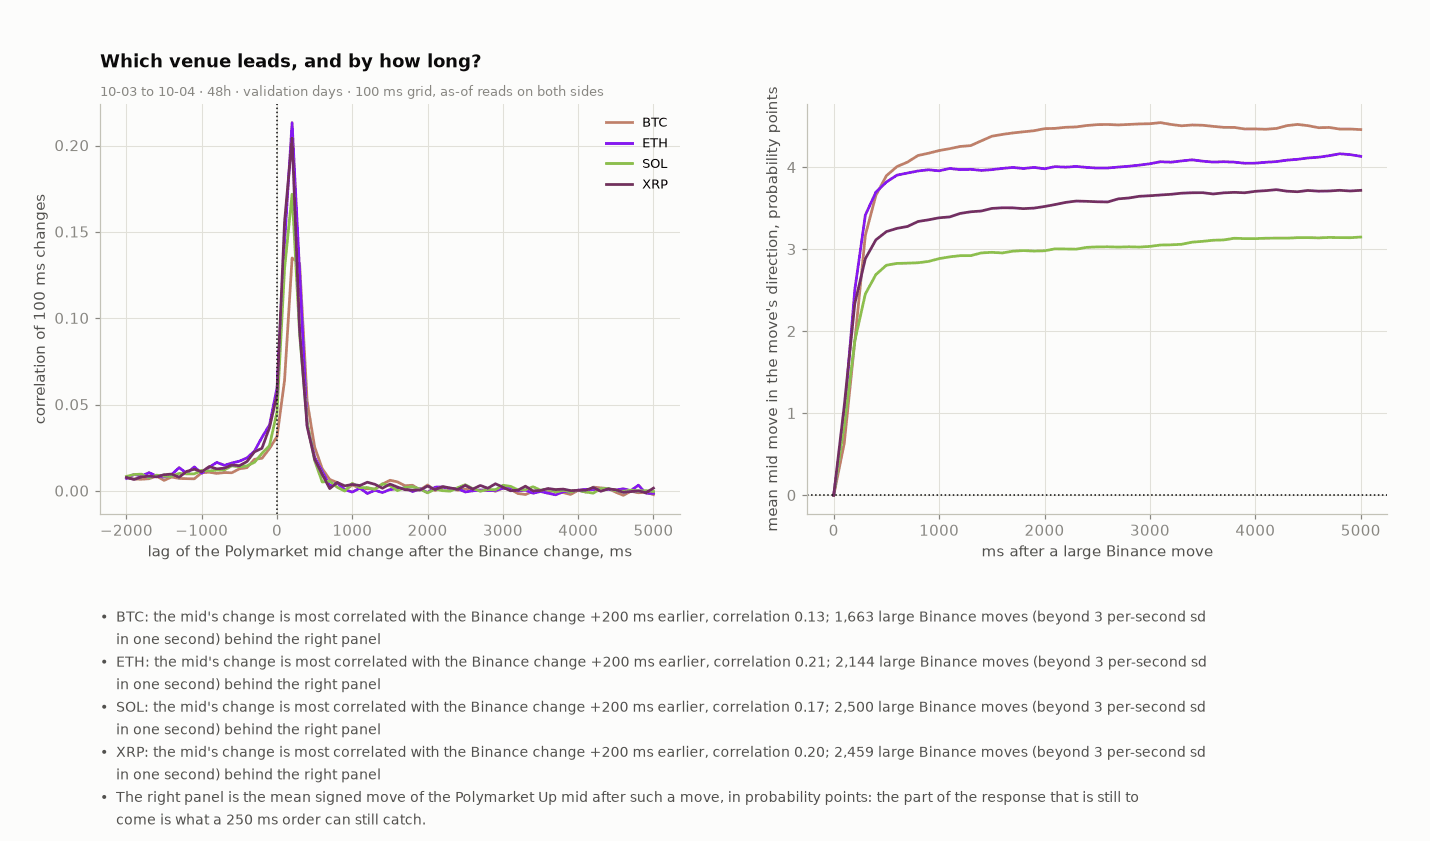

In [12]:
LL = D.lead_lag_curve(VAL)
fig = None
bul = [f"{a.upper()}: the mid's change is most correlated with the Binance change {int(LL[a]['lag_ms'][np.nanargmax(LL[a]['corr'])]):+d} ms earlier, correlation {np.nanmax(LL[a]['corr']):.2f}; {int(LL[a]['n_events'][0]):,} large Binance moves (beyond 3 per-second sd in one second) behind the right panel" for a in ASSETS]
bul.append("The right panel is the mean signed move of the Polymarket Up mid after such a move, in probability points: the part of the response that is still to come is what a 250 ms order can still catch.")
fig, gs, top = mkfig(4.6, bul, 1, 2, wspace=0.22)
a1, a2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
for a in ASSETS:
    a1.plot(LL[a]["lag_ms"], LL[a]["corr"], color=ACOL[a], label=a.upper())
    a2.plot(LL[a]["step_ms"], LL[a]["resp"] * 100, color=ACOL[a], label=a.upper())
a1.axvline(0, color=INK, lw=1.0, ls=":"); a1.set_xlabel("lag of the Polymarket mid change after the Binance change, ms"); a1.set_ylabel("correlation of 100 ms changes")
a2.axhline(0, color=INK, lw=1.0, ls=":"); a2.set_xlabel("ms after a large Binance move"); a2.set_ylabel("mean mid move in the move's direction, probability points")
a1.legend(loc="upper right", fontsize=8.5); ask(a1, "Which venue leads, and by how long?", f"{WIN_VAL} · 100 ms grid, as-of reads on both sides")
figstyle.finish(fig, bul, top)
figstyle.show(fig, "fig:s2-leadlag", FIGURES)
LAG_PEAK = {a: int(LL[a]["lag_ms"][np.nanargmax(LL[a]["corr"])]) for a in ASSETS}
LAG_RESP_250 = {a: float(LL[a]["resp"][2] / max(LL[a]["resp"][-1], 1e-12)) for a in ASSETS}
GATE_LAG = all(v > 0 for v in LAG_PEAK.values())

**Gate to S3.** The reference is a fair stand-in when the trailing-mean reading reproduces the recorded outcome on at least 95% of fit-day windows; the lead of Binance over the book is measured above and used as measured (a 250 ms order meets a book that has typically moved part of the way).

In [13]:
GATES.append({"id": "G2", "section": "S2", "label": "Binance leads the book", "name": "the Polymarket mid follows Binance (the peak lag is after zero on every asset)",
              "reading": ", ".join(f"{a.upper()} {LAG_PEAK[a]:+d} ms" for a in ASSETS), "verdict": "PASS" if GATE_LAG else "FLAG", "would_change": "a peak at or before zero would mean the book leads"})
print({g["id"]: g["verdict"] for g in GATES})

{'G1': 'PASS', 'G2': 'PASS'}


## S3 · Core result

| question | gate to S4 |
|---|---|
| On the validation days which momentum configuration is best, and on the two test days, read once, does its win rate beat the break-even win rate of what it paid, with the net PnL per entry above zero, and does its probability beat the Polymarket mid? | the test win rate's Wilson interval lies above the break-even win rate; the net PnL per entry is above zero with its slot-cluster interval; the Brier of the momentum probability at the triggered instants does not lose to the mid's |

### S3.1 · The probability against the market's, on the validation days

At every 5-second instant where the signal is ON, the momentum side either won or lost. Four probabilities of that win are scored against the outcome on the same instants: the fit-window win rate (a constant), the baseline Brownian fair value, the logistic map and the table map; and the Polymarket mid of that side, the market's own probability. Lower is better.

In [14]:
SF_VAL = ST.sample_frame(VAL)
BASE_FIT = FIT_REP["side_win_rate"]
SC = []
for L in LOOKBACKS:
    for zm in Z_MINS:
        tr = ST.triggered(SF_VAL, zm, L)
        s = ST.prob_scores(tr, L, BASE_FIT).set_index("name")
        SC.append(dict(L=L, zmin=zm, n=int(s["n"].iloc[0]), const=s.loc["constant: fit-window win rate", "brier"], mid=s.loc["Polymarket mid of the side", "brier"],
                       brownian=s.loc["Brownian fair value (baseline)", "brier"], logit=s.loc["logistic map", "brier"], table=s.loc[f"table map ({L} s lookback)", "brier"],
                       win=float(tr[np.isfinite(tr["mid_side"])]["y_side"].mean())))
SC = pd.DataFrame(SC)
display(Markdown("**Brier score at the triggered validation instants** (lower is better; the same instants for every column; `win` is the share of those instants where the momentum side won)\n\n| Lookback (s) | z_min | Instants | Win | Constant | Polymarket mid | Brownian | Logistic | Table |\n|---|---|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.L} | {r.zmin:g} | {r.n:,} | {r.win * 100:.1f}% | {r.const:.4f} | {r.mid:.4f} | {r.brownian:.4f} | {r.logit:.4f} | {r.table:.4f} |" for r in SC.itertuples())))
BEAT = {m_: float((SC[m_] < SC["mid"]).mean()) for m_ in ("brownian", "logit", "table")}
print("share of the 15 (lookback, z_min) rows where the map's Brier is below the mid's:", {k: pct(v) for k, v in BEAT.items()})

**Brier score at the triggered validation instants** (lower is better; the same instants for every column; `win` is the share of those instants where the momentum side won)

| Lookback (s) | z_min | Instants | Win | Constant | Polymarket mid | Brownian | Logistic | Table |
|---|---|---|---|---|---|---|---|---|
| 10 | 0.5 | 30,172 | 80.6% | 0.1562 | 0.1380 | 0.1398 | 0.1414 | 0.1448 |
| 10 | 1 | 17,987 | 83.2% | 0.1408 | 0.1232 | 0.1255 | 0.1273 | 0.1304 |
| 10 | 1.5 | 9,540 | 84.9% | 0.1305 | 0.1149 | 0.1163 | 0.1201 | 0.1217 |
| 10 | 2 | 4,454 | 84.0% | 0.1362 | 0.1209 | 0.1238 | 0.1316 | 0.1319 |
| 10 | 3 | 700 | 88.6% | 0.1085 | 0.0901 | 0.0905 | 0.1031 | 0.1025 |
| 30 | 0.5 | 39,946 | 80.3% | 0.1582 | 0.1403 | 0.1423 | 0.1440 | 0.1470 |
| 30 | 1 | 24,273 | 82.8% | 0.1431 | 0.1261 | 0.1285 | 0.1303 | 0.1330 |
| 30 | 1.5 | 13,249 | 84.6% | 0.1326 | 0.1178 | 0.1194 | 0.1232 | 0.1240 |
| 30 | 2 | 6,184 | 83.6% | 0.1385 | 0.1231 | 0.1263 | 0.1342 | 0.1341 |
| 30 | 3 | 923 | 87.8% | 0.1134 | 0.0943 | 0.0946 | 0.1100 | 0.1075 |
| 60 | 0.5 | 47,149 | 79.9% | 0.1608 | 0.1423 | 0.1446 | 0.1460 | 0.1492 |
| 60 | 1 | 28,886 | 82.5% | 0.1449 | 0.1284 | 0.1309 | 0.1324 | 0.1355 |
| 60 | 1.5 | 15,784 | 84.4% | 0.1337 | 0.1192 | 0.1210 | 0.1244 | 0.1253 |
| 60 | 2 | 7,264 | 83.9% | 0.1366 | 0.1219 | 0.1253 | 0.1322 | 0.1322 |
| 60 | 3 | 1,016 | 88.3% | 0.1102 | 0.0908 | 0.0910 | 0.1053 | 0.1034 |

share of the 15 (lookback, z_min) rows where the map's Brier is below the mid's: {'brownian': '0.0%', 'logit': '0.0%', 'table': '0.0%'}


### S3.2 · The grid on the validation days, and the choice

Every configuration of the grid ran on the two validation days at the 250 ms latency. The choice rule was fixed before the run: the momentum configuration with the best net PnL per entry among those with at least 100 entries. The whole grid is below, not only its best cell: these are 138 trials on one pair of days, so the best one is likely flattered.

In [15]:
GRID = ST.grid_table(VAL)
GRID["win_minus_be_pp"] = GRID["win_minus_be_pp"].astype(float)
_g = GRID[GRID["n"] > 0].sort_values("per_entry", ascending=False)
PICK = ST.pick(GRID, MIN_ENTRIES)
display(Markdown(f"**Validation grid, top 12 by net PnL per entry** (all {len(GRID)} rows in the Appendix; {int((GRID['n'] >= MIN_ENTRIES).sum())} configurations reach {MIN_ENTRIES} entries)\n\n| Configuration | Entries | Win rate | Break-even | Win - break-even | Avg price | Net per entry | Net total |\n|---|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| `{r.cfg}` | {r.n} | {r.win_rate * 100:.1f}% | {r.be * 100:.1f}% | {r.win_minus_be_pp:+.1f} pp | {r.avg_px:.3f} | {sgn(r.per_entry, 2)} | {sgn(r.net, 0)} |" for r in _g.head(12).itertuples())))
BASE_ROWS = GRID[GRID["family"] == "baseline"]
display(Markdown("**The baseline with no momentum gate** (the Brownian fair value on every event, either side, the same fills)\n\n| Configuration | Entries | Win rate | Break-even | Win - break-even | Net per entry | Net total |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| `{r.cfg}` | {r.n} | {r.win_rate * 100:.1f}% | {r.be * 100:.1f}% | {r.win_minus_be_pp:+.1f} pp | {sgn(r.per_entry, 2)} | {sgn(r.net, 0)} |" for r in BASE_ROWS.itertuples())))
assert PICK is not None, "no momentum configuration reaches the minimum entries on the validation days: NO SIZE, the test days are not read"
CHOSEN = PICK["cfg"]
CH = next(c for c in CFGS if c["name"] == CHOSEN)
BASE_CFG = f"baseline|th{CH['theta']:g}"
_lo, _hi = ST.slot_cluster_mean_ci(D.entries_frame(VAL, CHOSEN))
VAL_T = float(PICK["per_entry"]) / ((_hi - _lo) / 3.92)                  # the validation t-statistic: the mean over a slot-cluster standard error
T_BEST_OF_N = math.sqrt(2 * math.log(N_TRIALS))
display(Markdown(f"**Chosen on the validation days:** `{CHOSEN}` (map {CH['map']}, z_min {CH['zmin']:g}, lookback {CH['L']} s, theta {CH['theta']:g}): {int(PICK['n'])} entries, win rate {PICK['win_rate'] * 100:.1f}% against a break-even of {PICK['be'] * 100:.1f}%, net {sgn(PICK['per_entry'], 2)} USD per entry. "
                 f"Its t-statistic on the validation days is about {VAL_T:.1f}; the best of {N_TRIALS} unrelated noise configurations would show about {T_BEST_OF_N:.1f}, so a validation edge of this size is not evidence by itself."))
CHOSEN_ROWS = [("`z_min`", f"{CH['zmin']:g} volatility units"), ("`L`", f"{CH['L']} s"), ("map", CH["map"]), ("`theta`", f"{CH['theta']:g} probability points"), ("`T_min`", f"{T_MIN_S} s"), ("latency", f"{LATENCY_MS} ms")]
display(Markdown("**The values chosen** (the rest of the parameter table in S1.3 is fixed)\n\n| Parameter | Chosen value |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in CHOSEN_ROWS)))
TEST_READS = []

**Validation grid, top 12 by net PnL per entry** (all 138 rows in the Appendix; 131 configurations reach 100 entries)

| Configuration | Entries | Win rate | Break-even | Win - break-even | Avg price | Net per entry | Net total |
|---|---|---|---|---|---|---|---|
| `brownian|z1|L10|th0.06` | 274 | 76.6% | 72.5% | +4.2 pp | 0.711 | +1.20 | +328 |
| `brownian|z0.5|L60|th0.06` | 370 | 72.4% | 69.2% | +3.2 pp | 0.678 | +1.07 | +397 |
| `brownian|z1|L60|th0.06` | 289 | 74.7% | 71.4% | +3.4 pp | 0.700 | +1.05 | +303 |
| `baseline|th0.06` | 624 | 53.5% | 51.0% | +2.5 pp | 0.495 | +0.96 | +596 |
| `brownian|z1|L30|th0.06` | 283 | 75.3% | 71.6% | +3.7 pp | 0.702 | +0.95 | +269 |
| `brownian|z0.5|L30|th0.06` | 356 | 73.0% | 69.5% | +3.6 pp | 0.681 | +0.92 | +326 |
| `brownian|z0.5|L10|th0.06` | 346 | 73.1% | 70.3% | +2.8 pp | 0.689 | +0.79 | +273 |
| `table|z2|L30|th0.06` | 305 | 69.8% | 68.5% | +1.4 pp | 0.670 | +0.68 | +208 |
| `logit|z2|L30|th0.06` | 321 | 70.1% | 69.1% | +1.0 pp | 0.676 | +0.67 | +215 |
| `table|z2|L60|th0.06` | 306 | 69.3% | 68.4% | +0.9 pp | 0.669 | +0.59 | +180 |
| `table|z2|L30|th0.03` | 347 | 71.8% | 70.7% | +1.0 pp | 0.693 | +0.57 | +199 |
| `logit|z2|L60|th0.06` | 322 | 69.6% | 69.0% | +0.6 pp | 0.675 | +0.57 | +183 |

**The baseline with no momentum gate** (the Brownian fair value on every event, either side, the same fills)

| Configuration | Entries | Win rate | Break-even | Win - break-even | Net per entry | Net total |
|---|---|---|---|---|---|---|
| `baseline|th0` | 721 | 45.9% | 49.6% | -3.7 pp | -1.13 | -814 |
| `baseline|th0.03` | 718 | 47.1% | 50.4% | -3.4 pp | -0.96 | -690 |
| `baseline|th0.06` | 624 | 53.5% | 51.0% | +2.5 pp | +0.96 | +596 |

**Chosen on the validation days:** `brownian|z1|L10|th0.06` (map brownian, z_min 1, lookback 10 s, theta 0.06): 274 entries, win rate 76.6% against a break-even of 72.5%, net +1.20 USD per entry. Its t-statistic on the validation days is about 1.6; the best of 138 unrelated noise configurations would show about 3.1, so a validation edge of this size is not evidence by itself.

**The values chosen** (the rest of the parameter table in S1.3 is fixed)

| Parameter | Chosen value |
|---|---|
| `z_min` | 1 volatility units |
| `L` | 10 s |
| map | brownian |
| `theta` | 0.06 probability points |
| `T_min` | 60 s |
| latency | 250 ms |

### S3.3 · The test days, read once

The chosen configuration, fixed on the validation days, now meets the two test days. Nothing below is tuned after this read. The 16 windows an engine smoke test looked at before registration (2026-10-05, 12:00 to 13:00 UTC) are excluded by the rule written in the pre-registration and counted apart.

In [16]:
def read_test(cfg, why):
    """The ONLY door to the test days' configuration rows: every read is logged and checked at the end (S7) against what the pre-registration allows."""
    TEST_READS.append((cfg, why))
    return D.entries_frame(TEST, cfg)


E_TEST_ALL = read_test(CHOSEN, "the chosen configuration")
_lo_s, _hi_s = ms_(SMOKE_HOUR[0]), ms_(SMOKE_HOUR[1])
_smoke = (E_TEST_ALL["win_start_ms"] >= _lo_s) & (E_TEST_ALL["win_start_ms"] < _hi_s)
E_TEST = E_TEST_ALL[~_smoke].reset_index(drop=True)
N_SMOKE = int(_smoke.sum())
TS = ST.entry_summary(E_TEST)
USABLE_T = E_TEST[E_TEST["wstatus"] == "ok"]
N_USABLE_T, N_TRIGW = len(USABLE_T), int((USABLE_T["n_trig"] > 0).sum())
CI_PER = ST.slot_cluster_mean_ci(E_TEST)
CI_TOT = ST.window_cluster_ci(E_TEST)
ADV = ST.adverse(E_TEST)
_t0, _eq0, _dd0 = ST.equity_curve(E_TEST, BOOK_USD)
display(Markdown(f"**Test days, `{CHOSEN}`** ({N_USABLE_T:,} usable windows of {len(E_TEST):,}; {N_SMOKE} smoke-test windows left out; {N_TRIGW:,} windows had a trigger that cleared theta, {TS['n']:,} entered)\n\n"
    "| Measure | Value |\n|---|---|\n"
    f"| Entries | {TS['n']:,}, one per window at most |\n| Win rate | **{pct(TS['win_rate'])}**, Wilson 95% {pct(TS['lo'])} to {pct(TS['hi'])} ({TS['wins']:,} of {TS['n']:,}) |\n"
    f"| Break-even win rate of the fills (cost plus fee per share) | **{pct(TS['be'])}** at an average price of {TS['avg_px']:.3f} |\n| Win rate minus break-even | **{TS['win_minus_be_pp']:+.1f} pp** (interval: {(TS['lo'] - TS['be']) * 100:+.1f} to {(TS['hi'] - TS['be']) * 100:+.1f} pp) |\n"
    f"| PnL before the fee | {usd(TS['gross'])} |\n| Taker fees | {usd(TS['fee'])} |\n| **PnL after the fee** | **{usd(TS['net'])}**, 95% slot-cluster interval {usd(CI_TOT[0])} to {usd(CI_TOT[1])} |\n"
    f"| Net per entry | {sgn(TS['per_entry'], 2)} USD, interval {sgn(CI_PER[0], 2)} to {sgn(CI_PER[1], 2)} |\n| Partial fills (under the USD 20 clip) | {TS['partial']:,} |\n"
    f"| Deepest drawdown of the entry-by-entry equity | {usd(float(_dd0.min()) if len(_dd0) else 0.0)} on the {usd(BOOK_USD)} book |\n"
    f"| Most capital open at once | {usd(ST.max_concurrent_usd(E_TEST))} of the {usd(BOOK_USD)} book (up to four assets of one quarter hour) |"))
PA = ST.by_key(E_TEST, "asset").set_index("key").reindex(list(ASSETS))
display(Markdown("**By asset** (four assets overlap in time, so these are not four independent bets)\n\n| Asset | Entries | Win rate | Break-even | Win - break-even | Net after fee | Net per entry |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {a.upper()} | {int(r.n)} | {pct(r.win_rate)} | {pct(r.be)} | {r.win_minus_be_pp:+.1f} pp | {sgn(r.net, 0)} | {sgn(r.per_entry, 2)} |" for a, r in PA.iterrows() if r.n)))
DY = ST.daily(E_TEST, list(TEST_DAYS))
display(Markdown("**By day**\n\n| Day | Entries | Before fee | Fees | After fee |\n|---|---|---|---|---|\n" + "\n".join(f"| {d} | {int(r.n)} | {sgn(r.gross, 0)} | {usd(r.fee)} | {sgn(r.net, 0)} |" for d, r in DY.iterrows())))
GATE_WIN = bool(TS["n"] and TS["lo"] > TS["be"])
GATE_NET = bool(TS["n"] and TS["per_entry"] > 0 and CI_PER[0] > 0)

**Test days, `brownian|z1|L10|th0.06`** (705 usable windows of 705; 16 smoke-test windows left out; 250 windows had a trigger that cleared theta, 157 entered)

| Measure | Value |
|---|---|
| Entries | 157, one per window at most |
| Win rate | **73.2%**, Wilson 95% 65.8% to 79.6% (115 of 157) |
| Break-even win rate of the fills (cost plus fee per share) | **72.2%** at an average price of 0.708 |
| Win rate minus break-even | **+1.0 pp** (interval: -6.4 to +7.3 pp) |
| PnL before the fee | USD 34 |
| Taker fees | USD 55 |
| **PnL after the fee** | **USD -21**, 95% slot-cluster interval USD -321 to USD 269 |
| Net per entry | -0.14 USD, interval -2.01 to +1.69 |
| Partial fills (under the USD 20 clip) | 43 |
| Deepest drawdown of the entry-by-entry equity | USD -230 on the USD 1,000 book |
| Most capital open at once | USD 63 of the USD 1,000 book (up to four assets of one quarter hour) |

**By asset** (four assets overlap in time, so these are not four independent bets)

| Asset | Entries | Win rate | Break-even | Win - break-even | Net after fee | Net per entry |
|---|---|---|---|---|---|---|
| BTC | 89 | 73.0% | 72.8% | +0.3 pp | +26 | +0.29 |
| ETH | 38 | 73.7% | 69.8% | +3.9 pp | -34 | -0.89 |
| SOL | 16 | 75.0% | 76.0% | -1.0 pp | -11 | -0.68 |
| XRP | 14 | 71.4% | 70.9% | +0.6 pp | -2 | -0.17 |

**By day**

| Day | Entries | Before fee | Fees | After fee |
|---|---|---|---|---|
| 2026-10-05 | 74 | +103 | USD 25 | +78 |
| 2026-10-06 | 83 | -69 | USD 30 | -99 |

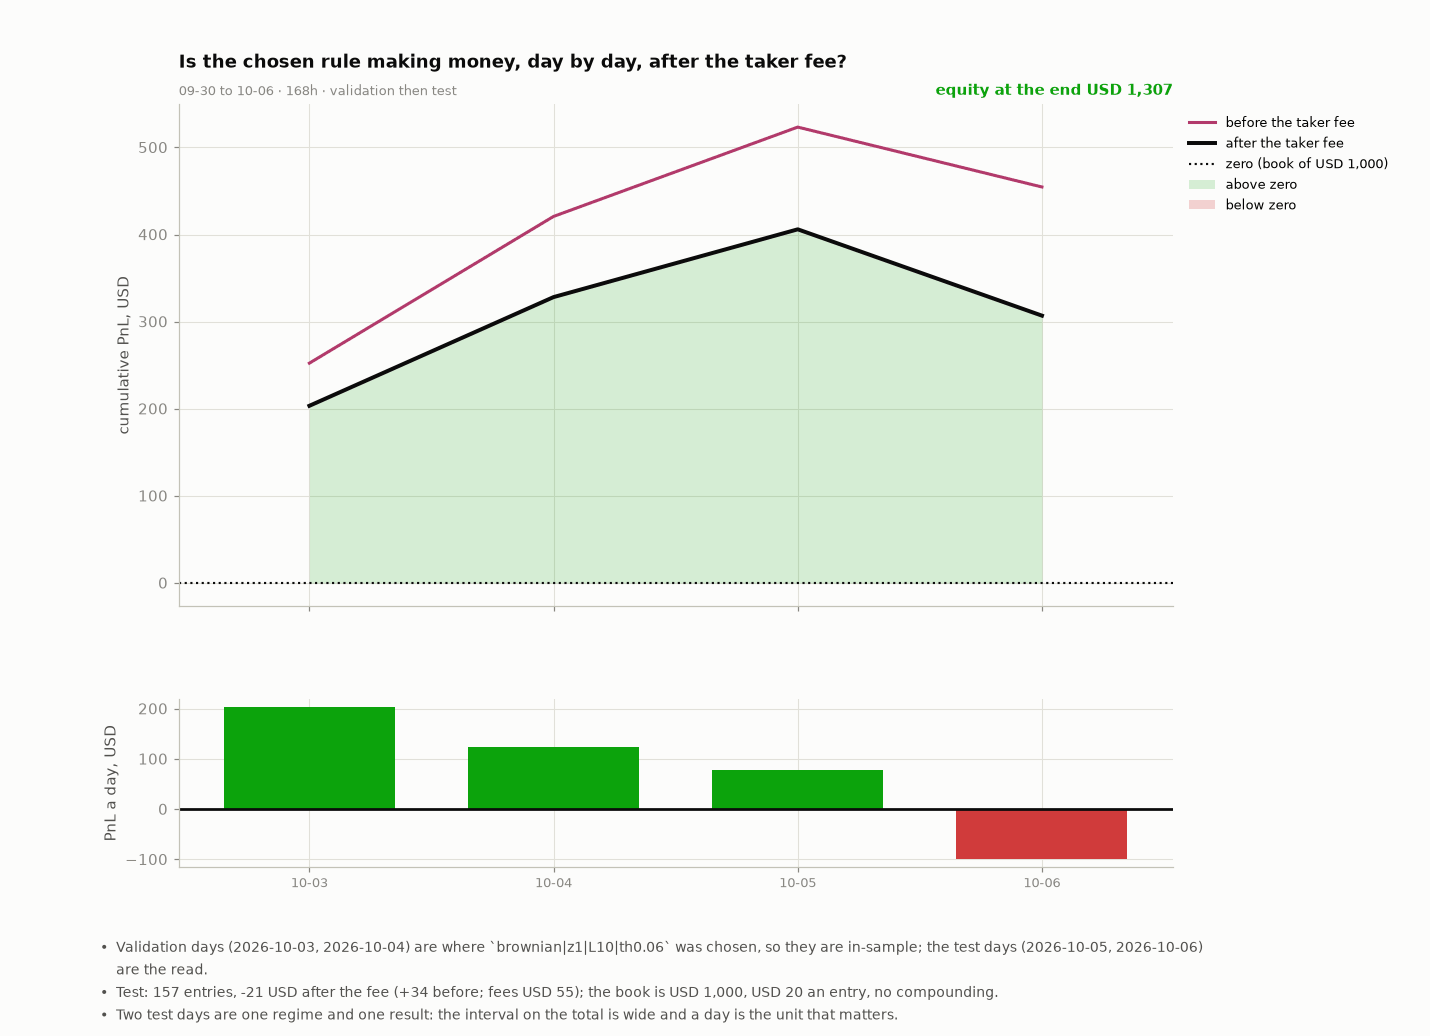

In [17]:
# the validation days of the chosen configuration are IN-SAMPLE (it was chosen on them): drawn next to the test days, labelled, never pooled into the verdict
E_VAL = D.entries_frame(VAL, CHOSEN)
E_BOTH = pd.concat([E_VAL, E_TEST], ignore_index=True)
_days = list(VAL_DAYS + TEST_DAYS)
_d = ST.daily(E_BOTH, _days)
bul = [f"Validation days ({', '.join(VAL_DAYS)}) are where `{CHOSEN}` was chosen, so they are in-sample; the test days ({', '.join(TEST_DAYS)}) are the read.",
       f"Test: {TS['n']} entries, {sgn(TS['net'], 0)} USD after the fee ({sgn(TS['gross'], 0)} before; fees {usd(TS['fee'])}); the book is {usd(BOOK_USD)}, {usd(CLIP_USD)} an entry, no compounding.",
       "Two test days are one regime and one result: the interval on the total is wide and a day is the unit that matters."]
fig = FG.draw_equity_by_day(_days, _d["net"].to_numpy(), _d["gross"].to_numpy(), BOOK_USD, "Is the chosen rule making money, day by day, after the taker fee?", WIN_TXT.replace("4 assets", "validation then test"), bul)
figstyle.show(fig, "fig:s3-equity", FIGURES)

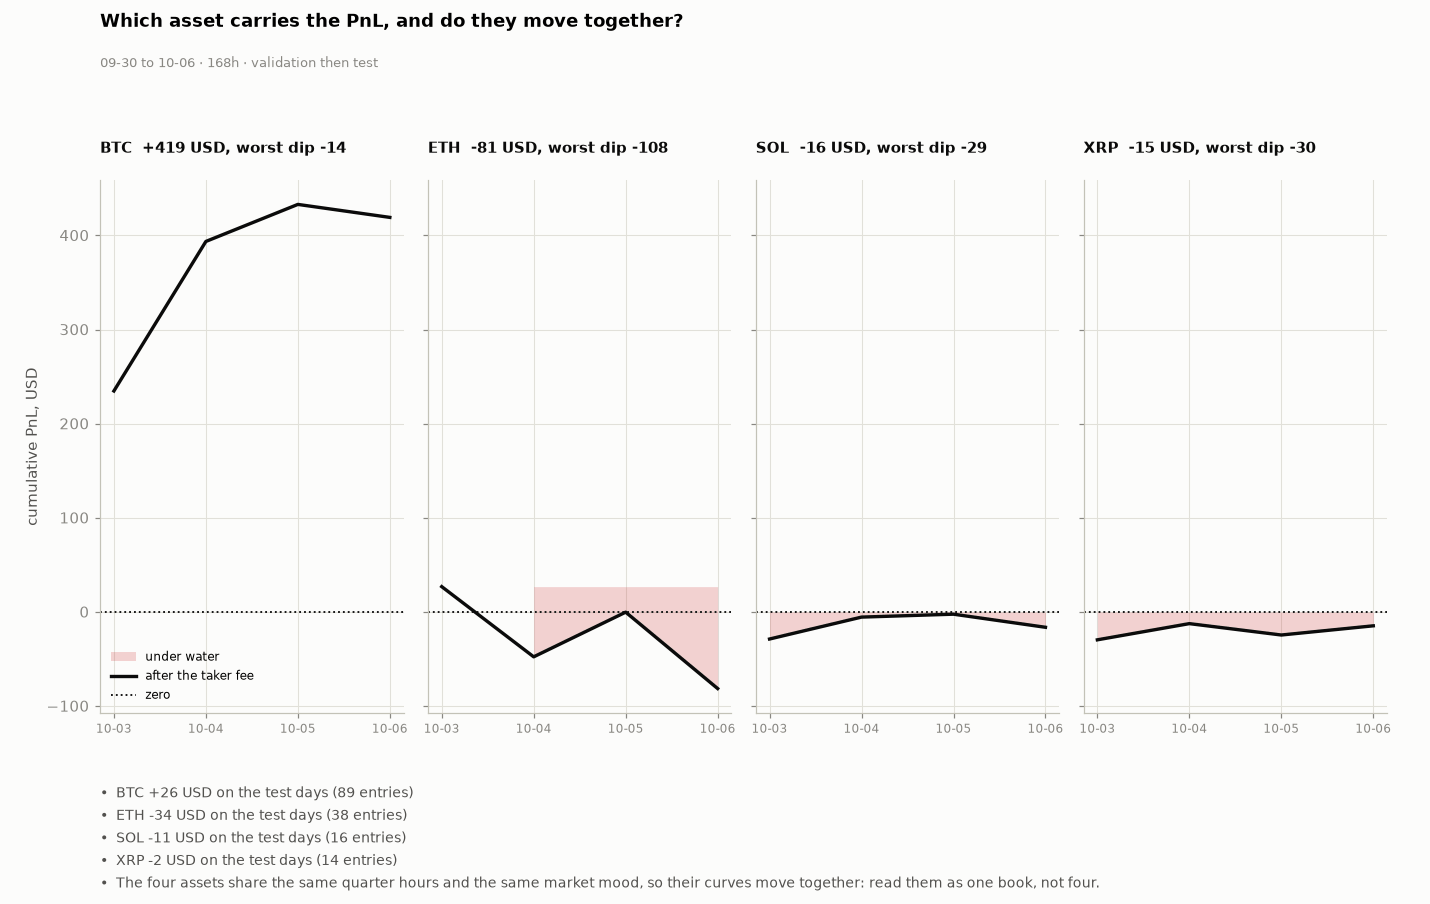

In [18]:
_pa = {a: ST.daily(E_BOTH[E_BOTH["asset"] == a], _days)["net"].to_numpy() for a in ASSETS}
bul = [f"{a.upper()} {sgn(PA.loc[a, 'net'], 0) if PA.loc[a, 'n'] else 'no entries'} USD on the test days ({int(PA.loc[a, 'n'])} entries)" for a in ASSETS]
bul += ["The four assets share the same quarter hours and the same market mood, so their curves move together: read them as one book, not four."]
fig = FG.draw_asset_equity(_days, _pa, BOOK_USD, "Which asset carries the PnL, and do they move together?", WIN_TXT.replace("4 assets", "validation then test"), bul)
figstyle.show(fig, "fig:s3-assets", FIGURES)

### S3.4 · Win rate against break-even, and is the probability calibrated

A high win rate is not the same as a profit: a token bought at 0.85 needs to win more than 85% of the time plus its fee. The first chart splits the test entries by the price they paid; the second asks whether the probability the model quoted was true, on the test days, at the instants where the signal was ON.

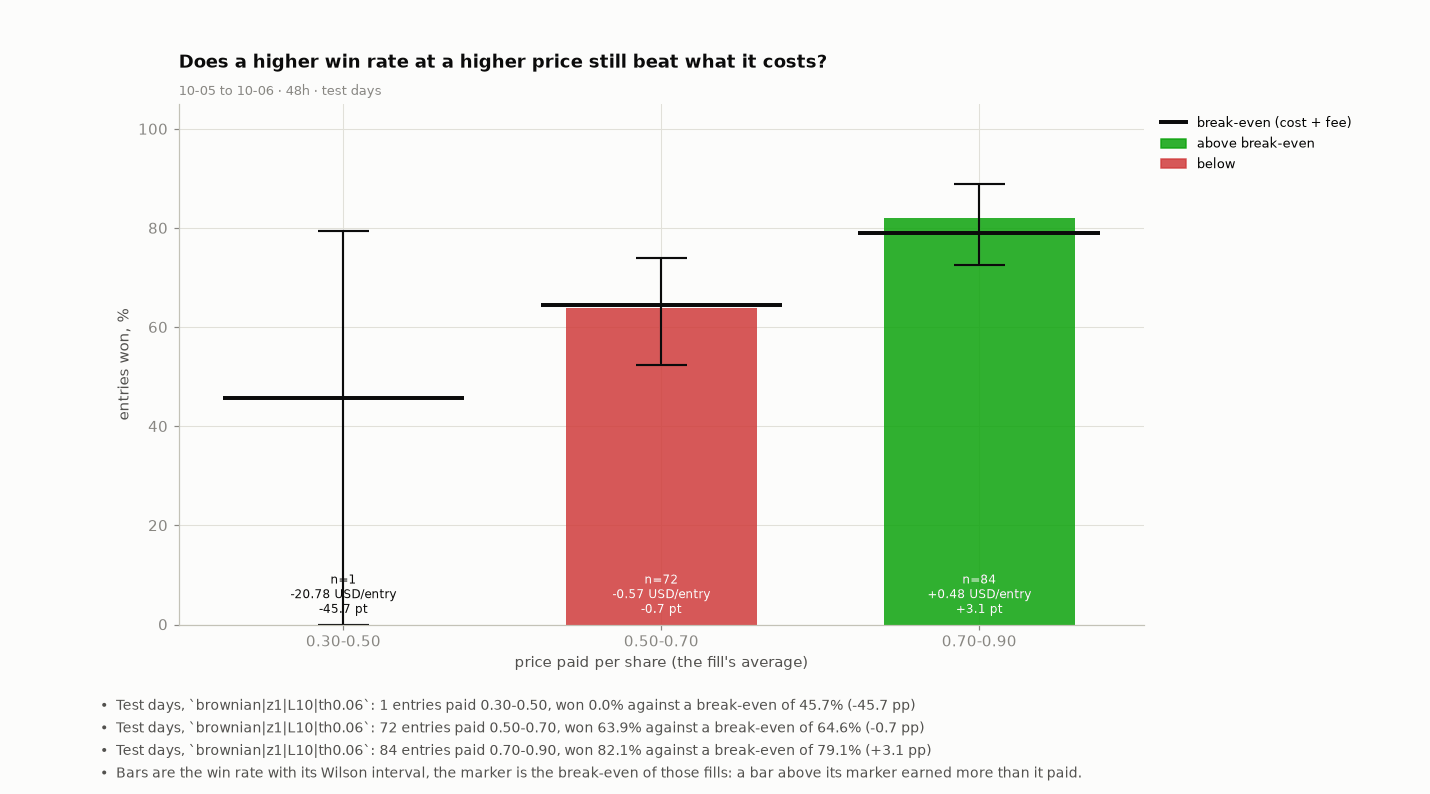

In [19]:
PB = ST.by_price_bucket(E_TEST)
if len(PB):
    _bul = [f"Test days, `{CHOSEN}`: {int(r.n)} entries paid {r.bucket}, won {pct(r.win_rate)} against a break-even of {pct(r.be)} ({r.win_minus_be_pp:+.1f} pp)" for r in PB.itertuples()]
    _bul += ["Bars are the win rate with its Wilson interval, the marker is the break-even of those fills: a bar above its marker earned more than it paid."]
    fig = FG.draw_breakeven_by_price(PB, "Does a higher win rate at a higher price still beat what it costs?", WIN_TEST, _bul)
    figstyle.show(fig, "fig:s3-breakeven", FIGURES)

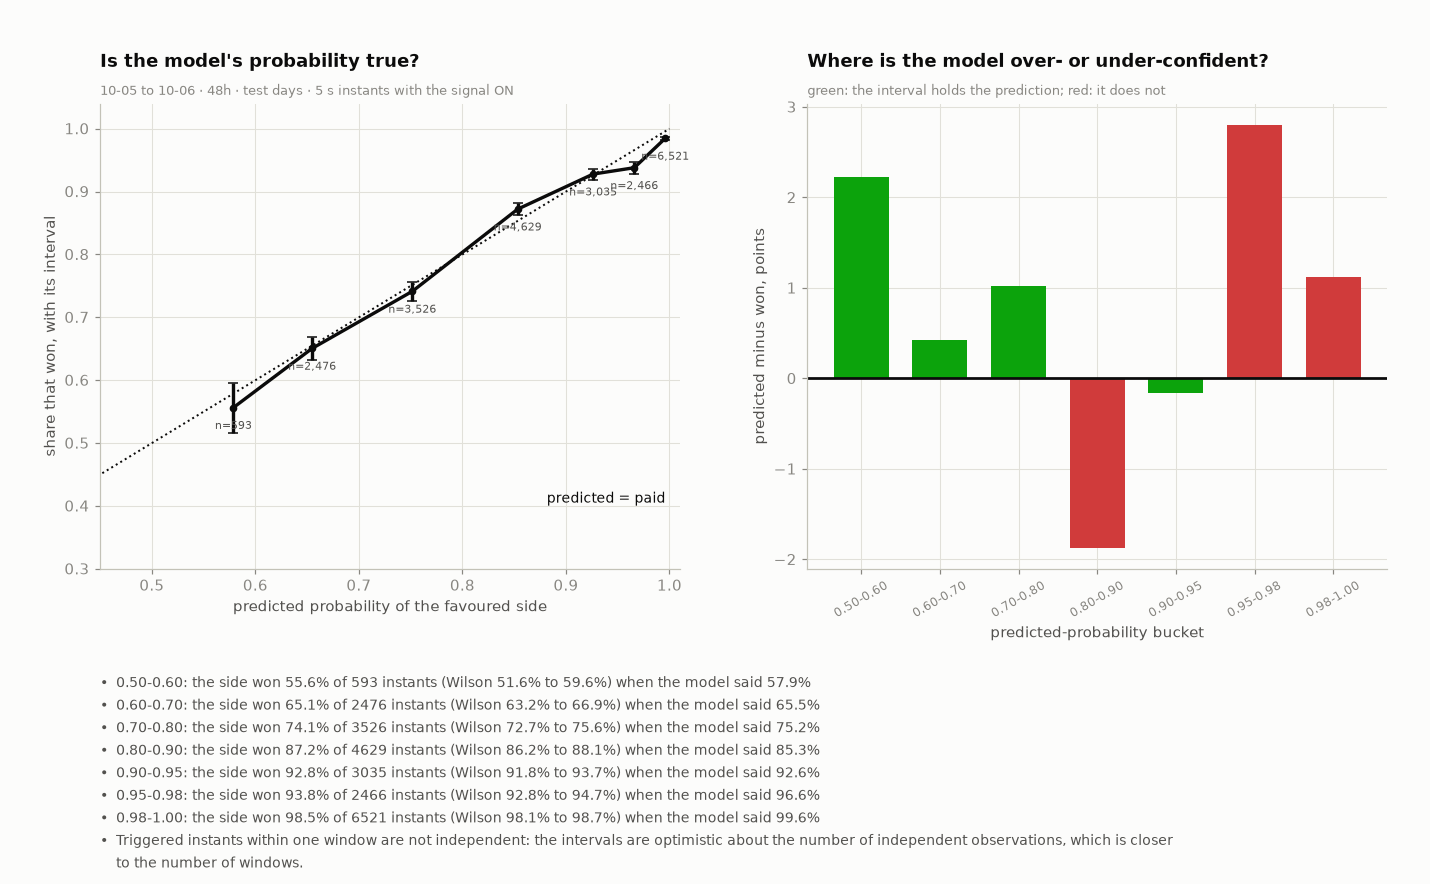

**Brier score at the triggered test instants** (21,415 instants in 685 windows; lower is better)

| Probability | Brier | Log loss |
|---|---|---|
| constant: fit-window win rate | 0.1269 | 0.4239 |
| Polymarket mid of the side | 0.1087 | 0.3500 |
| Brownian fair value (baseline) | 0.1094 | 0.3606 |
| logistic map | 0.1102 | 0.3585 |
| table map (10 s lookback) | 0.1158 | 0.3784 |

Chosen map minus the Polymarket mid: **+0.0007** Brier, 95% window-cluster interval -0.0011 to +0.0026.

In [20]:
SF_TEST = ST.sample_frame(TEST)
TEST_READS.append((CHOSEN, "the 5 s instants of the test days, for the probability scores"))
SF_TEST = SF_TEST[~((SF_TEST["win_start_ms"] >= _lo_s) & (SF_TEST["win_start_ms"] < _hi_s))]
_pcol = {"brownian": "p_brownian", "logit": "p_logit", "table": f"p_table{CH['L']}"}[CH["map"]]
TRT = ST.triggered(SF_TEST, CH["zmin"], CH["L"])
CAL = ST.calibration_table(TRT[_pcol], TRT["y_side"])
SCT = ST.prob_scores(TRT, CH["L"], BASE_FIT).set_index("name")
_name = {"brownian": "Brownian fair value (baseline)", "logit": "logistic map", "table": f"table map ({CH['L']} s lookback)"}[CH["map"]]
DIFF, DLO, DHI, NCL = ST.cluster_diff_ci(TRT.assign(model_p=TRT[_pcol]), "model_p")
_bul = [f"{r.bucket}: the side won {pct(r.win_rate)} of {int(r.n)} instants (Wilson {pct(r.lo)} to {pct(r.hi)}) when the model said {pct(r.p_mean)}" for r in CAL.itertuples()]
_bul += ["Triggered instants within one window are not independent: the intervals are optimistic about the number of independent observations, which is closer to the number of windows."]
fig = FG.draw_calibration(CAL, "Is the model's probability true?", WIN_TEST + " · 5 s instants with the signal ON", _bul)
figstyle.show(fig, "fig:s3-calibration", FIGURES)
display(Markdown(f"**Brier score at the triggered test instants** ({len(TRT[np.isfinite(TRT['mid_side'])]):,} instants in {NCL:,} windows; lower is better)\n\n| Probability | Brier | Log loss |\n|---|---|---|\n" +
                 "\n".join(f"| {nm} | {r.brier:.4f} | {r.logloss:.4f} |" for nm, r in SCT.iterrows()) +
                 f"\n\nChosen map minus the Polymarket mid: **{DIFF:+.4f}** Brier, 95% window-cluster interval {DLO:+.4f} to {DHI:+.4f}."))
GATE_PROB = bool(np.isfinite(DIFF) and DHI < 0)

In [21]:
GATES.append({"id": "G3", "section": "S3", "label": "Win beats break-even", "name": "the test win rate's Wilson interval lies above the break-even win rate of the fills",
              "reading": f"win {pct(TS['win_rate'])} [{pct(TS['lo'])}, {pct(TS['hi'])}] vs break-even {pct(TS['be'])}", "verdict": "PASS" if GATE_WIN else "FAIL",
              "would_change": "a longer window, where the interval narrows"})
GATES.append({"id": "G4", "section": "S3", "label": "Net per entry above zero", "name": "the net PnL per entry on the test days is above zero and its slot-cluster interval excludes zero",
              "reading": f"{sgn(TS['per_entry'], 2)} USD per entry, 95% {sgn(CI_PER[0], 2)} to {sgn(CI_PER[1], 2)}", "verdict": "PASS" if GATE_NET else "FAIL", "would_change": "more days"})
GATES.append({"id": "G5", "section": "S3", "label": "Beats the market's mid", "name": "the chosen probability beats the Polymarket mid on Brier at the triggered test instants (interval below zero)",
              "reading": f"{DIFF:+.4f} Brier [{DLO:+.4f}, {DHI:+.4f}]", "verdict": "PASS" if GATE_PROB else ("FLAG" if np.isfinite(DIFF) and DIFF < 0 else "FAIL"), "would_change": "a different window"})
print({g["id"]: g["verdict"] for g in GATES})

{'G1': 'PASS', 'G2': 'PASS', 'G3': 'FAIL', 'G4': 'FAIL', 'G5': 'FAIL'}


## S4 · Robustness

| question | gate to S6 |
|---|---|
| Is the result more than luck and the favourite: does the momentum gate beat the same fills with no gate, the side the mid favours, and random entry times; does it survive the latency and fee tables; and do the planted look-ahead tests behave as they must? | the planted leak is flagged, features one second from the future help, shuffled outcomes remove the edge, and the net after the fee is not an artefact of a free fill |

### S4.1 · Benchmarks on the test days

Same days, same fills model. *Baseline*: the Brownian fair value on every event with no momentum gate, at the chosen theta. *Favourite*: at each entry instant of the model, buy the side the Polymarket mid favours instead. *Random*: the same number of entries per day at random windows and random instants, on a random side. The last two are filled at the best ask of the 250 ms book grid for the whole USD 20, which is generous to them (no depth walk).

| Rule | Entries | Win rate | Break-even | Net per entry | Net total |
|---|---|---|---|---|---|
| The chosen momentum rule | 157 | 73.2% | 72.2% | -0.14 | -21 |
| Baseline: Brownian fair value, no gate | 483 | 50.1% | 47.6% | +1.51 | +730 |
| Favourite by the Polymarket mid, same instants | 157 | 72.6% | 72.4% | -0.00 | -0 |
| Random instants and side, same count (mean of 300) | 157 | 50.6% |  | -1.78 | -268 |

Random entries at the same count earn -1.78 USD per entry on average (5th to 95th percentile -5.83 to +2.97): that is the price of the fee and the spread. The chosen rule's -0.14 sits above 76% of the random draws.

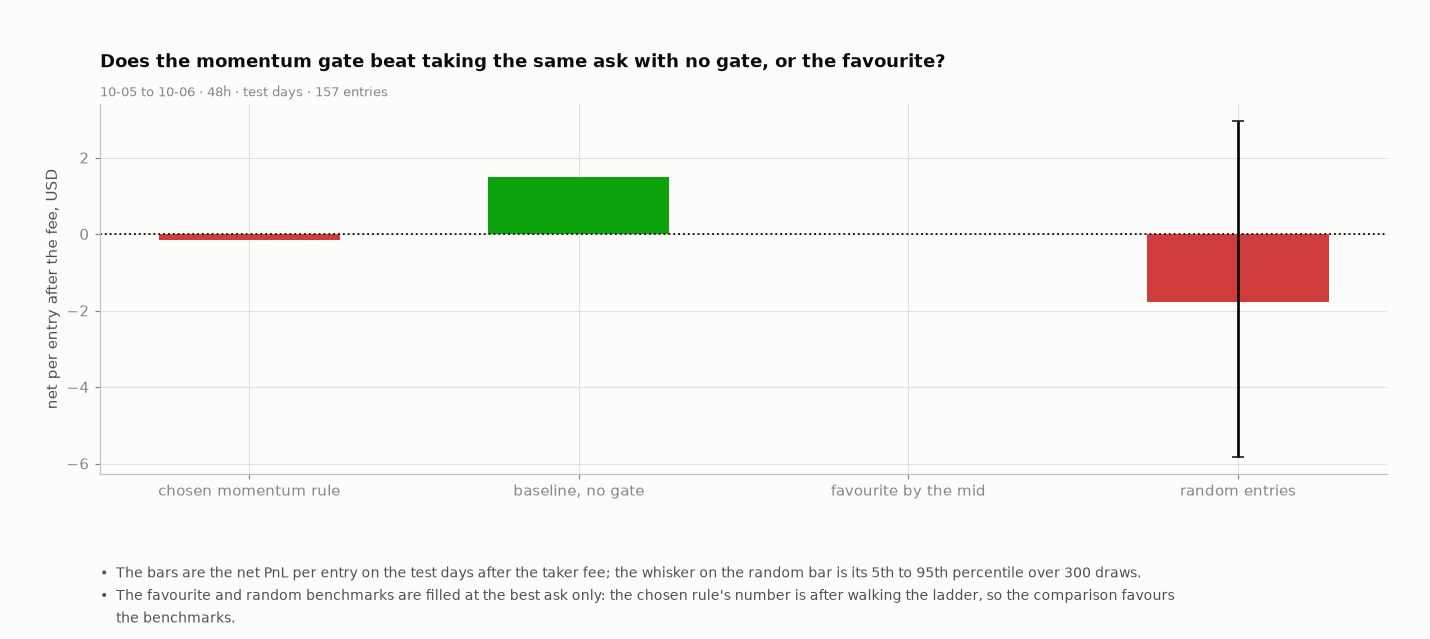

In [22]:
E_BASE = read_test(BASE_CFG, "the baseline at the chosen theta, for the comparison")
E_BASE = E_BASE[~((E_BASE["win_start_ms"] >= _lo_s) & (E_BASE["win_start_ms"] < _hi_s))]
SB = ST.entry_summary(E_BASE)
_rng = np.random.default_rng(SEED)
B_FAV = ST.bench_summary(ST.bench_entries(TEST, E_TEST, _rng, "favourite"))
RND_PER, RND_TOT = ST.random_dist(TEST, E_TEST, reps=300, seed=SEED)
RND_WIN = float(np.nanmean([ST.bench_summary(ST.bench_entries(TEST, E_TEST, np.random.default_rng(SEED + i), "random"))["win_rate"] for i in range(20)]))
_rows = [("The chosen momentum rule", TS["n"], TS["win_rate"], TS["be"], TS["per_entry"], TS["net"]),
         ("Baseline: Brownian fair value, no gate", SB["n"], SB["win_rate"], SB["be"], SB["per_entry"], SB["net"]),
         ("Favourite by the Polymarket mid, same instants", B_FAV["n"], B_FAV["win_rate"], B_FAV["be"], B_FAV["per_entry"], B_FAV["net"]),
         ("Random instants and side, same count (mean of 300)", TS["n"], RND_WIN, np.nan, float(np.nanmean(RND_PER)), float(np.nanmean(RND_TOT)))]
display(Markdown("| Rule | Entries | Win rate | Break-even | Net per entry | Net total |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {a} | {n:,} | {pct(w) if w == w else ''} | {pct(b) if b == b else ''} | {sgn(p, 2) if p == p else ''} | {sgn(t, 0)} |" for a, n, w, b, p, t in _rows)))
RND_P5, RND_P95 = float(np.nanpercentile(RND_PER, 5)), float(np.nanpercentile(RND_PER, 95))
P_RND = float((RND_PER >= TS["per_entry"]).mean()) if TS["n"] else np.nan
display(Markdown(f"Random entries at the same count earn {sgn(float(np.nanmean(RND_PER)), 2)} USD per entry on average (5th to 95th percentile {sgn(RND_P5, 2)} to {sgn(RND_P95, 2)}): that is the price of the fee and the spread. The chosen rule's {sgn(TS['per_entry'], 2)} sits above {pct(1 - P_RND, 0)} of the random draws."))
fig, gs, top = mkfig(4.2, ["The bars are the net PnL per entry on the test days after the taker fee; the whisker on the random bar is its 5th to 95th percentile over 300 draws.",
                          "The favourite and random benchmarks are filled at the best ask only: the chosen rule's number is after walking the ladder, so the comparison favours the benchmarks."], 1, 1)
ax = fig.add_subplot(gs[0])
_lab = ["chosen momentum rule", "baseline, no gate", "favourite by the mid", "random entries"]
_val = [TS["per_entry"], SB["per_entry"], B_FAV["per_entry"], float(np.nanmean(RND_PER))]
ax.bar(_lab, _val, color=[figstyle.VERDICT["good"] if (v == v and v > 0) else figstyle.VERDICT["bad"] for v in _val], width=0.55)
ax.errorbar([3], [_val[3]], yerr=[[_val[3] - RND_P5], [RND_P95 - _val[3]]], color=INK, capsize=4)
ax.axhline(0, color=INK, lw=1.2, ls=":"); ax.set_ylabel("net per entry after the fee, USD")
ask(ax, "Does the momentum gate beat taking the same ask with no gate, or the favourite?", f"{WIN_TEST} · {TS['n']} entries")
figstyle.finish(fig, ["The bars are the net PnL per entry on the test days after the taker fee; the whisker on the random bar is its 5th to 95th percentile over 300 draws.",
                      "The favourite and random benchmarks are filled at the best ask only: the chosen rule's number is after walking the ladder, so the comparison favours the benchmarks."], top)
figstyle.show(fig, "fig:s4-benchmarks", FIGURES)

### S4.2 · Fee and latency tables

The fee: the same entries re-scored with a different multiple of the taker fee. The latency: the same rule with the order reaching the book 0, 150, 250, 400 or 1000 ms after the signal, from the same ladders (the second pass over each day's pinned ladders). The venue's own taker delay is 150 ms inside the owner's 250.

In [23]:
FEE_ROWS = []
x = E_TEST[E_TEST["status"] == "entered"]
for k in (0.0, 0.5, 1.0, 1.5, 2.0):
    net = (x["pnl_gross"] - k * x["fee_usd"])
    FEE_ROWS.append((k, float(net.sum()), float(net.mean()) if len(x) else np.nan, float((net > 0).mean()) if len(x) else np.nan))
display(Markdown("**Fee multiple** (1.0 is the market's own schedule)\n\n| Fee x | Net total | Net per entry | Share of entries with a profit |\n|---|---|---|---|\n" + "\n".join(f"| {k:g} | {sgn(t, 0)} | {sgn(p, 2)} | {pct(w)} |" for k, t, p, w in FEE_ROWS)))
FEE_FLIP = next((k for k, t, p, w in FEE_ROWS if t <= 0), None)

**Fee multiple** (1.0 is the market's own schedule)

| Fee x | Net total | Net per entry | Share of entries with a profit |
|---|---|---|---|
| 0 | +34 | +0.22 | 73.2% |
| 0.5 | +6 | +0.04 | 73.2% |
| 1 | -21 | -0.14 | 73.2% |
| 1.5 | -49 | -0.31 | 73.2% |
| 2 | -76 | -0.49 | 73.2% |

In [24]:
VER_DAYS = {}
for d in VAL_DAYS + TEST_DAYS:
    b = RUN.seated_verify(d, CHOSEN)
    assert b is not None, f"the planted-test pass of {d} for {CHOSEN} is not seated: run `python updown15_runner.py verify {d} --cfg {CHOSEN}`"
    VER_DAYS[d] = D.unpack(b)
    if d in TEST_DAYS:
        TEST_READS.append((CHOSEN, f"the latency pass of {d}"))
VER_VAL = [VER_DAYS[d] for d in VAL_DAYS]
VER_TEST = [VER_DAYS[d] for d in TEST_DAYS]
_vn = VER_VAL[0][1]["variants"]
LAT_ROWS = []
for nm, lat in (("latency_0ms", 0), ("latency_50ms", 50), ("latency_150ms", 150), ("base", 250), ("latency_400ms", 400), ("latency_1000ms", 1000)):
    for lab, vd in (("validation (in-sample)", VER_VAL), ("test", VER_TEST)):
        e = D.verify_entries(vd, nm)
        e = e[~((e["win_start_ms"] >= _lo_s) & (e["win_start_ms"] < _hi_s))] if lab == "test" else e
        sm = len(e)
        LAT_ROWS.append(dict(lat=lat, which=lab, n=sm, win=float(e["won"].mean()) if sm else np.nan, be=float(((e["cost"] + e["fee_usd"]) / e["shares"]).mean()) if sm else np.nan,
                             per=float(e["pnl_net"].mean()) if sm else np.nan, net=float(e["pnl_net"].sum()) if sm else 0.0))
LAT = pd.DataFrame(LAT_ROWS)
display(Markdown("**Signal-to-book latency** (the rule as chosen; 250 is the owner's number; the validation rows are where it was chosen)\n\n| Latency | Days | Entries | Win rate | Break-even | Net per entry | Net total |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.lat} ms | {r.which} | {r.n} | {pct(r.win) if r.win == r.win else ''} | {pct(r.be) if r.be == r.be else ''} | {sgn(r.per, 2) if r.per == r.per else ''} | {sgn(r.net, 0)} |" for r in LAT.itertuples())))
LAT_T = LAT[LAT["which"] == "test"].set_index("lat")
_chk = float(LAT_T.loc[250, "net"]) - TS["net"]
print(f"the second pass at 250 ms reproduces the first pass's test net: difference {_chk:+.4f} USD")
assert abs(_chk) < 1e-3, "the second pass does not reproduce the first: the derivation is not deterministic"
VERIFY["passed"] += 1; VERIFY["total"] += 1

**Signal-to-book latency** (the rule as chosen; 250 is the owner's number; the validation rows are where it was chosen)

| Latency | Days | Entries | Win rate | Break-even | Net per entry | Net total |
|---|---|---|---|---|---|---|
| 0 ms | validation (in-sample) | 399 | 74.7% | 68.0% | +1.88 | +752 |
| 0 ms | test | 249 | 74.7% | 69.1% | +1.53 | +381 |
| 50 ms | validation (in-sample) | 383 | 74.9% | 68.4% | +2.10 | +804 |
| 50 ms | test | 242 | 74.8% | 69.3% | +1.36 | +330 |
| 150 ms | validation (in-sample) | 312 | 76.6% | 70.4% | +1.52 | +473 |
| 150 ms | test | 186 | 71.5% | 70.7% | +0.15 | +28 |
| 250 ms | validation (in-sample) | 274 | 76.6% | 72.5% | +1.20 | +328 |
| 250 ms | test | 157 | 73.2% | 72.2% | -0.14 | -21 |
| 400 ms | validation (in-sample) | 266 | 76.7% | 73.1% | +1.40 | +372 |
| 400 ms | test | 151 | 72.2% | 72.3% | -0.24 | -36 |
| 1000 ms | validation (in-sample) | 259 | 76.1% | 73.1% | +0.99 | +256 |
| 1000 ms | test | 141 | 70.2% | 72.4% | -0.75 | -105 |

the second pass at 250 ms reproduces the first pass's test net: difference -0.0000 USD


### S4.2b · The no-gate baseline earned more than the chosen rule: a lead, not a result

The baseline (the Brownian fair value on every event, either side, at the same theta) is one of the 138 pre-registered trials and a named benchmark; it was NOT the configuration the pre-registered rule chose (that rule picks among momentum configurations). It beat the chosen rule on both validation days and on the test days, so it is read here with the same care: its interval, its days and assets, its latency, and the planted tests on it. Nothing here moves the verdict on the registered question; it names the next bet.

In [25]:
CI_B = ST.slot_cluster_mean_ci(E_BASE)
CI_B_TOT = ST.window_cluster_ci(E_BASE)
E_BASE_V = D.entries_frame(VAL, BASE_CFG)
SBV = ST.entry_summary(E_BASE_V)
_pd = ST.daily(E_BASE, list(TEST_DAYS))
PBA = ST.by_key(E_BASE, "asset").set_index("key").reindex(list(ASSETS))
display(Markdown(f"**`{BASE_CFG}`, the same days and fills as the chosen rule**\n\n| | Entries | Win rate | Break-even | Win - break-even | Net after fee | Net per entry | Per-entry interval |\n|---|---|---|---|---|---|---|---|\n"
                 f"| Validation days (in-sample for the grid) | {SBV['n']} | {pct(SBV['win_rate'])} | {pct(SBV['be'])} | {SBV['win_minus_be_pp']:+.1f} pp | {sgn(SBV['net'], 0)} | {sgn(SBV['per_entry'], 2)} | |\n"
                 f"| **Test days** | {SB['n']} | {pct(SB['win_rate'])} (Wilson {pct(SB['lo'])} to {pct(SB['hi'])}) | {pct(SB['be'])} | {SB['win_minus_be_pp']:+.1f} pp | **{sgn(SB['net'], 0)}** (95% {sgn(CI_B_TOT[0], 0)} to {sgn(CI_B_TOT[1], 0)}) | {sgn(SB['per_entry'], 2)} | {sgn(CI_B[0], 2)} to {sgn(CI_B[1], 2)} |"))
display(Markdown("**Baseline on the test days, by day and by asset**\n\n| | Entries | Net after fee |\n|---|---|---|\n" + "\n".join(f"| {d} | {int(r.n)} | {sgn(r.net, 0)} |" for d, r in _pd.iterrows()) + "\n" +
                 "\n".join(f"| {a.upper()} | {int(r.n)} | {sgn(r.net, 0)} |" for a, r in PBA.iterrows() if r.n)))
VER_BV = {d: D.unpack(RUN.seated_verify(d, BASE_CFG)) for d in VAL_DAYS + TEST_DAYS}
TEST_READS.append((BASE_CFG, "the baseline's latency and planted passes on the test days"))
_rows = []
for nm, lab in (("latency_0ms", "0 ms"), ("latency_50ms", "50 ms"), ("latency_150ms", "150 ms"), ("base", "250 ms"), ("latency_400ms", "400 ms"), ("latency_1000ms", "1000 ms"), ("decision_later_1s", "decision 1 s later"), ("features_stale_1s", "features 1 s stale"),
                ("features_future_1s", "features 1 s from the future"), ("features_future_15s", "features 15 s from the future"), ("leak", "leak (the window-end price)")):
    for which, dd in (("validation", VAL_DAYS), ("test", TEST_DAYS)):
        e = D.verify_entries([VER_BV[d] for d in dd], nm)
        if which == "test":
            e = e[~((e["win_start_ms"] >= _lo_s) & (e["win_start_ms"] < _hi_s))]
        _rows.append((lab, which, len(e), float(e["won"].mean()) if len(e) else np.nan, float(e["pnl_net"].mean()) if len(e) else np.nan, float(e["pnl_net"].sum()) if len(e) else 0.0))
display(Markdown("**The baseline under the latency table and the planted variants** (entries, win rate, net per entry, net total)\n\n| Variant | Days | Entries | Win rate | Net per entry | Net total |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {a} | {b} | {c} | {pct(d_)} | {sgn(e_, 2)} | {sgn(f_, 0)} |" for a, b, c, d_, e_, f_ in _rows)))
BASE_LEAK_OK = all(r_[3] > 0.9 for r_ in _rows if r_[0].startswith("leak"))
BASE_DOSE_OK = all(next(r_[4] for r_ in _rows if r_[0] == lab_ and r_[1] == "test") > next(r_[4] for r_ in _rows if r_[0] == "250 ms" and r_[1] == "test") for lab_ in ("features 1 s from the future", "features 15 s from the future"))
display(Markdown("Read: a rule of this kind lives or dies on its clock. Features one second STALE lose money, features from the FUTURE gain steadily, the leak wins almost every time, and a decision one second late turns the net negative: the planted tests behave as they must on the baseline too. "
                 f"On the {len(TEST_DAYS)} test days it earned {sgn(SB['net'], 0)} USD on {SB['n']} entries, but the interval on the per-entry net ({sgn(CI_B[0], 2)} to {sgn(CI_B[1], 2)}) and the day-to-day spread are those of two days, and it was not the pre-registered choice: read it as the next bet (S7), not as an edge."))

**`baseline|th0.06`, the same days and fills as the chosen rule**

| | Entries | Win rate | Break-even | Win - break-even | Net after fee | Net per entry | Per-entry interval |
|---|---|---|---|---|---|---|---|
| Validation days (in-sample for the grid) | 624 | 53.5% | 51.0% | +2.5 pp | +596 | +0.96 | |
| **Test days** | 483 | 50.1% (Wilson 45.7% to 54.5%) | 47.6% | +2.5 pp | **+730** (95% -159 to +1,652) | +1.51 | -0.36 to +3.38 |

**Baseline on the test days, by day and by asset**

| | Entries | Net after fee |
|---|---|---|
| 2026-10-05 | 228 | +51 |
| 2026-10-06 | 255 | +679 |
| BTC | 147 | +500 |
| ETH | 137 | +110 |
| SOL | 104 | +55 |
| XRP | 95 | +65 |

**The baseline under the latency table and the planted variants** (entries, win rate, net per entry, net total)

| Variant | Days | Entries | Win rate | Net per entry | Net total |
|---|---|---|---|---|---|
| 0 ms | validation | 681 | 56.1% | +1.68 | +1,144 |
| 0 ms | test | 564 | 54.3% | +1.35 | +760 |
| 50 ms | validation | 673 | 56.2% | +1.61 | +1,082 |
| 50 ms | test | 557 | 54.0% | +0.88 | +491 |
| 150 ms | validation | 640 | 55.5% | +1.38 | +885 |
| 150 ms | test | 510 | 49.6% | +0.41 | +210 |
| 250 ms | validation | 624 | 53.5% | +0.96 | +596 |
| 250 ms | test | 483 | 50.1% | +1.51 | +730 |
| 400 ms | validation | 619 | 52.8% | +1.01 | +624 |
| 400 ms | test | 478 | 49.8% | +1.15 | +551 |
| 1000 ms | validation | 614 | 52.0% | +0.66 | +403 |
| 1000 ms | test | 460 | 48.9% | +1.48 | +682 |
| decision 1 s later | validation | 709 | 42.5% | -1.25 | -887 |
| decision 1 s later | test | 659 | 48.4% | -0.47 | -310 |
| features 1 s stale | validation | 708 | 43.5% | -1.33 | -943 |
| features 1 s stale | test | 650 | 48.6% | -0.20 | -131 |
| features 1 s from the future | validation | 656 | 56.7% | +2.30 | +1,507 |
| features 1 s from the future | test | 559 | 53.7% | +1.98 | +1,109 |
| features 15 s from the future | validation | 718 | 60.9% | +3.20 | +2,301 |
| features 15 s from the future | test | 700 | 59.3% | +3.08 | +2,157 |
| leak (the window-end price) | validation | 721 | 98.1% | +13.76 | +9,921 |
| leak (the window-end price) | test | 705 | 99.1% | +14.48 | +10,208 |

Read: a rule of this kind lives or dies on its clock. Features one second STALE lose money, features from the FUTURE gain steadily, the leak wins almost every time, and a decision one second late turns the net negative: the planted tests behave as they must on the baseline too. On the 2 test days it earned +730 USD on 483 entries, but the interval on the per-entry net (-0.36 to +3.38) and the day-to-day spread are those of two days, and it was not the pre-registered choice: read it as the next bet (S7), not as an edge.

### S4.2c · Does the decision clock matter? (validation days only)

The rule decides at every Binance trade. Here the same rule decides only on a clock: every 5 s, every 1 s or every 250 ms (the features are read as of that instant, the order still reaches the book 250 ms later). It runs on the two validation days only: the test days are not re-read at a new cadence (a new cadence on the test days would be a new registered run).

In [26]:
_cad = []
for cfg_, lab_ in ((CHOSEN, "the chosen rule"), (BASE_CFG, "the no-gate baseline")):
    vv = [D.unpack(RUN.seated_verify(d, cfg_)) for d in VAL_DAYS]
    for nm_, lab2 in (("base", "every Binance trade"), ("cadence_250ms", "every 250 ms"), ("cadence_1s", "every 1 s"), ("cadence_5s", "every 5 s")):
        c_, e_ = D.verify_counts(vv, nm_), D.verify_entries(vv, nm_)
        _cad.append((lab_, lab2, c_["windows"], c_["triggered"], c_["entered"], c_["ask_gone"], float(e_["won"].mean()), float(((e_["cost"] + e_["fee_usd"]) / e_["shares"]).mean()), float(e_["pnl_net"].mean()), float(e_["pnl_net"].sum())))
CAD = pd.DataFrame(_cad, columns=["rule", "clock", "windows", "triggered", "entered", "ask_gone", "win", "be", "per_entry", "net"])
display(Markdown("| Rule | Decides | Windows | With a trigger | Entered | Ask gone at every try | Win rate | Break-even | Net per entry | Net total |\n|---|---|---|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.rule} | {r.clock} | {r.windows} | {r.triggered} | {r.entered} | {r.ask_gone} | {pct(r.win)} | {pct(r.be)} | {sgn(r.per_entry, 2)} | {sgn(r.net, 0)} |" for r in CAD.itertuples())))
display(Markdown("Read: a coarser clock sees fewer triggers and loses fewer of them to a moved ask, but the net per entry stays inside its own noise (one standard error of the per-entry mean is about 0.7 USD on these days), and for the no-gate baseline it changes sign between clocks, so the decision clock is not what makes the edge thin and the baseline's positive number is fragile to which instant fires first. "
                 "The edge, where there is one, is the speed of the first reaction, and that is what the 250 ms eats."))

| Rule | Decides | Windows | With a trigger | Entered | Ask gone at every try | Win rate | Break-even | Net per entry | Net total |
|---|---|---|---|---|---|---|---|---|---|
| the chosen rule | every Binance trade | 721 | 402 | 274 | 126 | 76.6% | 72.5% | +1.20 | +328 |
| the chosen rule | every 250 ms | 721 | 361 | 286 | 74 | 75.2% | 72.4% | +0.79 | +226 |
| the chosen rule | every 1 s | 721 | 295 | 263 | 31 | 75.3% | 72.6% | +0.79 | +208 |
| the chosen rule | every 5 s | 721 | 224 | 210 | 13 | 78.6% | 74.3% | +1.32 | +278 |
| the no-gate baseline | every Binance trade | 721 | 684 | 624 | 59 | 53.5% | 51.0% | +0.96 | +596 |
| the no-gate baseline | every 250 ms | 721 | 685 | 660 | 22 | 49.1% | 50.3% | -0.69 | -457 |
| the no-gate baseline | every 1 s | 721 | 661 | 638 | 20 | 49.5% | 50.1% | -0.38 | -240 |
| the no-gate baseline | every 5 s | 721 | 619 | 608 | 11 | 51.0% | 49.9% | +1.06 | +646 |

Read: a coarser clock sees fewer triggers and loses fewer of them to a moved ask, but the net per entry stays inside its own noise (one standard error of the per-entry mean is about 0.7 USD on these days), and for the no-gate baseline it changes sign between clocks, so the decision clock is not what makes the edge thin and the baseline's positive number is fragile to which instant fires first. The edge, where there is one, is the speed of the first reaction, and that is what the 250 ms eats.

### S4.3 · The planted tests (the look-ahead proof)

Each test breaks one thing on purpose and asks what the number then does. They run on the **validation days** (the days the rule was chosen on), from the same ladders, so they are method checks and not a second look at the test days.

| Test | What it changes | What must happen |
|---|---|---|
| a. Leak | the model is told the window-end average | it must win absurdly often and be flagged |
| b. Features 1 s stale / 1 s from the future | every Binance read is one second older / newer | stale: no material change; future: the PnL must improve (else the features are not what we think) |
| c. Shuffled outcomes | the same entries scored against outcomes of other windows of the same asset | win rate at the base rate and PnL at its analytic value |
| d. The clock later | the decision clock moved +250 ms and +1 s against the book | the PnL must not rise |

In [27]:
WINS_V = pd.DataFrame([dict(asset=D.ASSETS[int(a)], outcome_up=bool(u)) for arrs, meta in VER_VAL for a, u in zip(arrs["w_asset"], arrs["w_up"])])
_map = {(): "base", (("leak", True),): "leak", (("feature_shift_s", 1),): "features_stale_1s", (("feature_shift_s", -1),): "features_future_1s",
        (("latency_ms_extra", 250),): "decision_later_250ms", (("latency_ms_extra", 1000),): "decision_later_1s"}


def run_variant(**kw):
    return D.verify_entries(VER_VAL, _map[tuple(sorted(kw.items()))])


PL_ROWS, PL_RAW = VF.run_all(run_variant, WINS_V)
display(Markdown("| Test | Expected | Reading | Result |\n|---|---|---|---|\n" + "\n".join(f"| {r['name']} | {r['expected']} | {r['reading']} | **{'PASS' if r['passed'] else 'FAIL'}** |" for r in PL_ROWS)))
display(HTML(PL_RAW["decay"].round(3).to_html(index=False, border=0)))
N_PL = len(PL_ROWS)
VERIFY["passed"] += sum(int(r["passed"]) for r in PL_ROWS); VERIFY["total"] += N_PL
GATE_PLANTED = all(r["passed"] for r in PL_ROWS)
# the registered b2 test moves the features one second; a momentum signal that reads the move since the start barely changes in a second, so that test is weak by design. The dose-response
# below shifts further (a leak of 5, 15 and 60 s) and reads the gain in standard errors of the base mean: time-aligned features gain more the further the future they are shown.
_base = D.verify_entries(VER_VAL, "base")
_se = float(_base["pnl_net"].std(ddof=1) / np.sqrt(len(_base))) if len(_base) > 1 else float("nan")
DOSE = []
for nm, sec in (("features_stale_15s", -15), ("features_stale_5s", -5), ("features_stale_1s", -1), ("base", 0), ("features_future_1s", 1), ("features_future_5s", 5), ("features_future_15s", 15), ("features_future_60s", 60)):
    e = D.verify_entries(VER_VAL, nm)
    DOSE.append(dict(shift_s=sec, entries=len(e), win=float(e["won"].mean()) if len(e) else np.nan, per_entry=float(e["pnl_net"].mean()) if len(e) else np.nan))
DOSE = pd.DataFrame(DOSE)
DOSE["gain_vs_base"] = DOSE["per_entry"] - float(DOSE.loc[DOSE["shift_s"] == 0, "per_entry"].iloc[0])
DOSE["gain_in_se"] = DOSE["gain_vs_base"] / _se
display(Markdown("**Dose-response: how far into the future the features are shown** (validation days; negative = stale, positive = from the future; the gain is in USD per entry and in standard errors of the base mean)\n\n| Shift, s | Entries | Win rate | Net per entry | Gain vs as run | In SE |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.shift_s:+d} | {r.entries} | {pct(r.win)} | {sgn(r.per_entry, 2)} | {sgn(r.gain_vs_base, 2)} | {r.gain_in_se:+.1f} |" for r in DOSE.itertuples())))
_fut = DOSE[DOSE["shift_s"] > 0]
DOSE_OK = bool(_fut["gain_vs_base"].is_monotonic_increasing and float(_fut["gain_in_se"].max()) >= 2.0)
_only_b2 = [r["name"] for r in PL_ROWS if not r["passed"]] == [next(r["name"] for r in PL_ROWS if r["name"].startswith("b2"))]
VERIFY["passed"] += int(DOSE_OK); VERIFY["total"] += 1

| Test | Expected | Reading | Result |
|---|---|---|---|
| a1 the leaking model is flagged | win rate Wilson low > 0.90 | win 0.981 on 721, low 0.968 | **PASS** |
| a2 the honest model is not flagged | Wilson low <= 0.90 | win 0.766 on 274, low 0.713 | **PASS** |
| b1 features 1 s stale: no material change | within 2 SE | -1.256 USD per entry vs SE 0.667 | **PASS** |
| b2 features 1 s from the future: better | at least +2 SE | +0.023 USD per entry vs SE 0.667 | **FAIL** |
| c1 shuffled outcomes: win rate at the base rate | 0.509 +/- 0.03 | 0.508 | **PASS** |
| c2 shuffled outcomes: PnL at its analytic value | -4.910 USD per entry | -4.943 (5th-95th -6.15..-3.79) | **PASS** |
| d1 clock +250 ms: PnL does not rise | per entry <= as run + 1 SE | -0.407 USD | **PASS** |
| d2 clock +1 s: PnL does not rise | per entry <= as run + 1 SE | -0.689 USD | **PASS** |

run,entries,win_rate,pnl_after_fee,per_entry,se
as run,274,0.766,328.269,1.198,0.667
+250 ms,303,0.752,239.809,0.791,0.664
+1 s,363,0.719,184.694,0.509,0.634


**Dose-response: how far into the future the features are shown** (validation days; negative = stale, positive = from the future; the gain is in USD per entry and in standard errors of the base mean)

| Shift, s | Entries | Win rate | Net per entry | Gain vs as run | In SE |
|---|---|---|---|---|---|
| -15 | 532 | 65.4% | -0.85 | -2.05 | -3.1 |
| -5 | 429 | 67.6% | -0.43 | -1.63 | -2.4 |
| -1 | 340 | 70.9% | -0.06 | -1.26 | -1.9 |
| +0 | 274 | 76.6% | +1.20 | +0.00 | +0.0 |
| +1 | 340 | 73.2% | +1.22 | +0.02 | +0.0 |
| +5 | 501 | 71.5% | +2.15 | +0.96 | +1.4 |
| +15 | 605 | 70.4% | +2.68 | +1.49 | +2.2 |
| +60 | 662 | 69.5% | +3.55 | +2.35 | +3.5 |

In [28]:
GATES.append({"id": "G6", "section": "S4", "label": "Planted tests behave", "name": "the leak is flagged, a stale feature set does not matter, a future one helps, shuffled outcomes remove the edge, a later clock does not help",
              "reading": f"{sum(int(r['passed']) for r in PL_ROWS)} of {N_PL} planted checks as they must; dose-response of the future shift {'clean' if DOSE_OK else 'not clean'} (15 s: {float(DOSE.loc[DOSE['shift_s'] == 15, 'gain_in_se'].iloc[0]):+.1f} SE)",
              "verdict": "PASS" if GATE_PLANTED else ("FLAG" if (_only_b2 and DOSE_OK) else "FAIL"), "would_change": "a detector stuck green on a planted fault"})
_b = float(np.nanmean(RND_PER))
GATES.append({"id": "G7", "section": "S4", "label": "Beats the same fills", "name": "the net per entry beats the no-gate baseline, the favourite and the random mean",
              "reading": f"{sgn(TS['per_entry'], 2)} vs baseline {sgn(SB['per_entry'], 2)}, favourite {sgn(B_FAV['per_entry'], 2)}, random {sgn(_b, 2)}",
              "verdict": "PASS" if (TS['per_entry'] > max(SB['per_entry'], B_FAV['per_entry'], _b)) else "FAIL", "would_change": "a longer window"})
GATES.append({"id": "G8", "section": "S4", "label": "Survives the fee", "name": "the net total stays above zero at the market's own fee",
              "reading": f"{sgn(TS['net'], 0)} USD at 1.0x; first multiple at or below zero: {FEE_FLIP if FEE_FLIP is not None else 'none up to 2.0'}", "verdict": "PASS" if TS["net"] > 0 else "FAIL", "would_change": "a different fee"})
print({g["id"]: g["verdict"] for g in GATES})

{'G1': 'PASS', 'G2': 'PASS', 'G3': 'FAIL', 'G4': 'FAIL', 'G5': 'FAIL', 'G6': 'FLAG', 'G7': 'FAIL', 'G8': 'FAIL'}


## S5 · Risk and diagnostics

| question | answer form |
|---|---|
| How often does the signal fire, why did a window not enter, what did the ask do in the 250 ms, do the four assets move together, and what does one window and its book look like? | counts and charts from the derived days; an interactive day and window view for JupyterLab, with a static picture of the same figure |

**Why a window entered or not** (test days, the chosen configuration)

| Reason | Windows | Share |
|---|---|---|
| entered | 157 | 22.3% |
| the signal never cleared theta (no edge) | 455 | 64.5% |
| an edge only in the last minute (too late) | 0 | 0.0% |
| a trigger, but the ask had moved by the fill | 92 | 13.0% |
| a trigger, but under 5 shares or no depth at the signal ask | 1 | 0.1% |
| no book by the first decision, 10 s in (excluded) | 0 | 0.0% |
| a Binance gap over 30 s (excluded) | 0 | 0.0% |

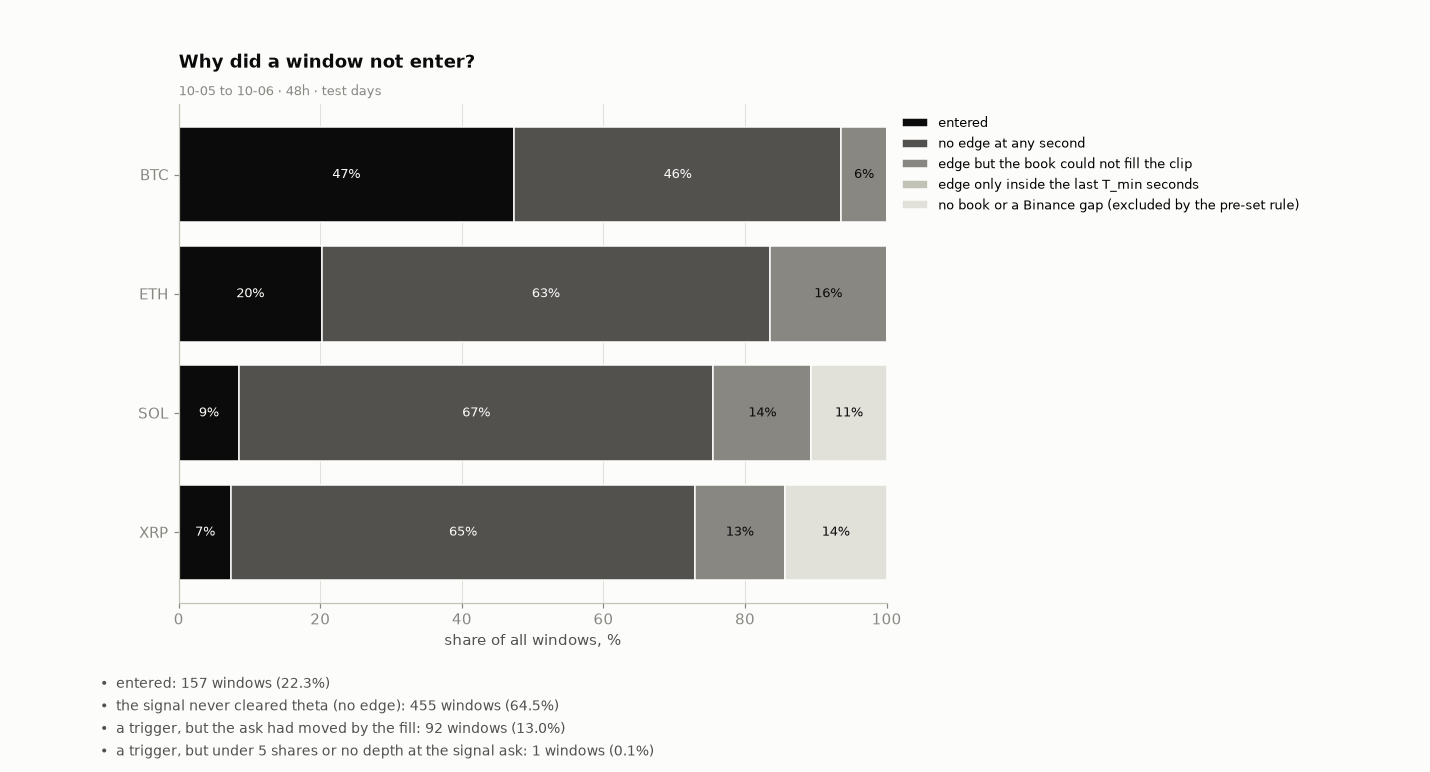

In [29]:
WINS_T, ENT_T = ST.figure_frames(TEST, CHOSEN)
WINS_T = WINS_T[~((WINS_T["win_start_ms"] >= _lo_s) & (WINS_T["win_start_ms"] < _hi_s))]
ENT_T = ENT_T[~((ENT_T["win_start_ms"] >= _lo_s) & (ENT_T["win_start_ms"] < _hi_s))]
RS = ST.reasons(E_TEST).value_counts()
LAB = {"entered": "entered", "no_edge": "the signal never cleared theta (no edge)", "late": "an edge only in the last minute (too late)", "ask_gone": "a trigger, but the ask had moved by the fill",
       "no_depth": "a trigger, but under 5 shares or no depth at the signal ask", "no_book": "no book by the first decision, 10 s in (excluded)", "binance_gap": "a Binance gap over 30 s (excluded)"}
display(Markdown("**Why a window entered or not** (test days, the chosen configuration)\n\n| Reason | Windows | Share |\n|---|---|---|\n" +
                 "\n".join(f"| {LAB[k]} | {int(RS.get(k, 0)):,} | {pct(RS.get(k, 0) / len(E_TEST))} |" for k in LAB)))
_bul = [f"{LAB[k]}: {int(RS.get(k, 0)):,} windows ({pct(RS.get(k, 0) / len(E_TEST))})" for k in LAB if RS.get(k, 0)]
fig = FG.draw_reasons(WINS_T, "Why did a window not enter?", WIN_TEST, _bul)
figstyle.show(fig, "fig:s5-reasons", FIGURES)

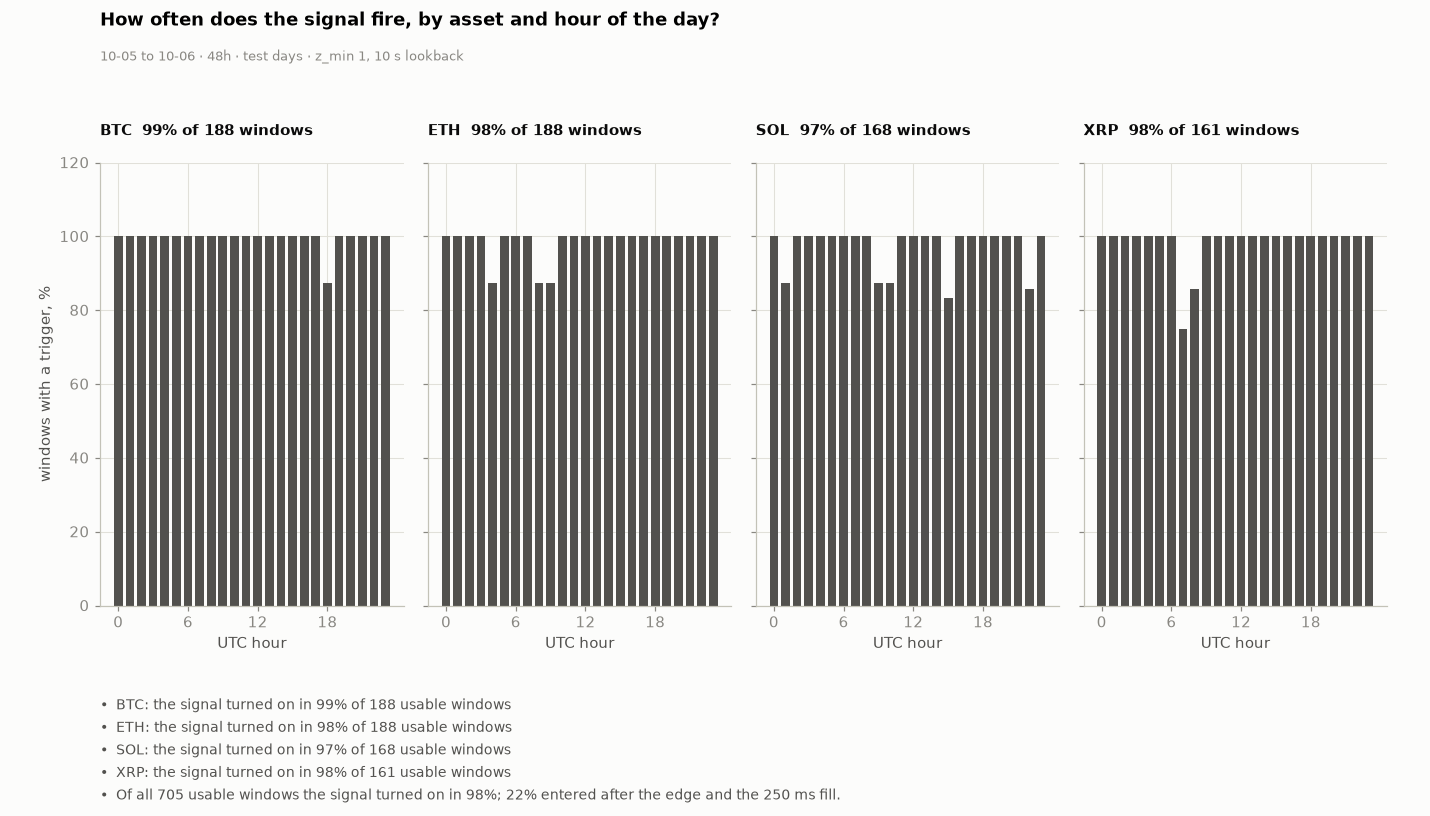

In [30]:
SIG = ST.signal_on_frame(TEST, CH["zmin"], CH["L"])
SIG = SIG[~((SIG["win_start_ms"] >= _lo_s) & (SIG["win_start_ms"] < _hi_s))]
_ba = SIG.groupby("asset")["triggered"].mean()
_bul = [f"{a.upper()}: the signal turned on in {pct(_ba.get(a, np.nan), 0)} of {int((SIG['asset'] == a).sum())} usable windows" for a in ASSETS]
_bul += [f"Of all {len(SIG):,} usable windows the signal turned on in {pct(SIG['triggered'].mean(), 0)}; {pct(TS['n'] / max(len(SIG), 1), 0)} entered after the edge and the 250 ms fill."]
fig = FG.draw_trigger_by_hour_asset(SIG[["asset", "hour", "triggered"]], "How often does the signal fire, by asset and hour of the day?", WIN_TEST + f" · z_min {CH['zmin']:g}, {CH['L']} s lookback", _bul)
figstyle.show(fig, "fig:s5-trigger-hour", FIGURES)

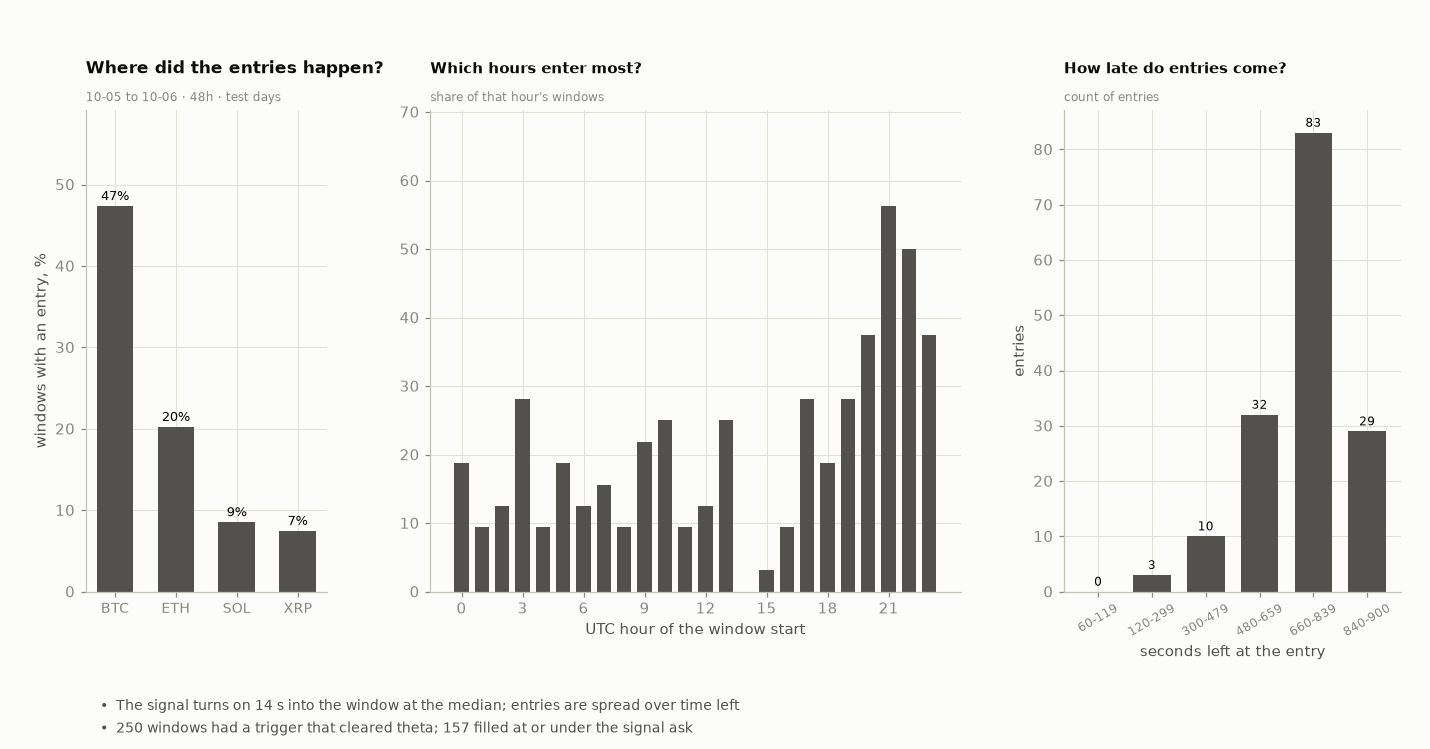

In [31]:
_bul = [f"The signal turns on {SIG.loc[SIG['triggered'], 'first_s'].median():.0f} s into the window at the median; entries are spread over time left" if SIG["triggered"].any() else "the signal never turned on"]
_bul += [f"{ST.adverse(E_TEST)['windows_with_trigger']:,} windows had a trigger that cleared theta; {TS['n']:,} filled at or under the signal ask"]
fig = FG.draw_trigger_rates(WINS_T, ENT_T, "Where did the entries happen?", WIN_TEST, _bul, hour_of=lambda ms: int((ms // 3_600_000) % 24))
figstyle.show(fig, "fig:s5-entry-rate", FIGURES)

In [32]:
_x = E_TEST[E_TEST["status"] == "entered"].copy()
_x["into"] = _x["t_signal_off_ms"] / 1000.0
_x["left"] = 900.0 - _x["into"]
display(Markdown("**When the entries happened** (test days, the chosen rule; the decision instant, seconds after the window opened and seconds before it closed)\n\n| Asset | Entries | Into the window, 25th / median / 75th | Left at the decision, 25th / median / 75th |\n|---|---|---|---|\n" +
                 "\n".join(f"| {a.upper()} | {len(g)} | {g.into.quantile(.25):.0f} / {g.into.median():.0f} / {g.into.quantile(.75):.0f} s | {g.left.quantile(.25):.0f} / {g.left.median():.0f} / {g.left.quantile(.75):.0f} s |" for a, g in _x.groupby("asset")) +
                 f"\n| All | {len(_x)} | {_x.into.quantile(.25):.0f} / {_x.into.median():.0f} / {_x.into.quantile(.75):.0f} s | {_x.left.quantile(.25):.0f} / {_x.left.median():.0f} / {_x.left.quantile(.75):.0f} s |"))

**When the entries happened** (test days, the chosen rule; the decision instant, seconds after the window opened and seconds before it closed)

| Asset | Entries | Into the window, 25th / median / 75th | Left at the decision, 25th / median / 75th |
|---|---|---|---|
| BTC | 89 | 93 / 172 / 292 s | 608 / 728 / 807 s |
| ETH | 38 | 52 / 132 / 193 s | 707 / 768 / 848 s |
| SOL | 16 | 106 / 159 / 279 s | 621 / 741 / 794 s |
| XRP | 14 | 82 / 145 / 293 s | 607 / 755 / 818 s |
| All | 157 | 81 / 160 / 255 s | 645 / 740 / 819 s |

### S5.1 · What happens to the ask in 250 ms

For each entry, how far the ask of the side we bought moved between the signal and the fill, and one second after the signal. A positive number is the market moving away from us.

In [33]:
ADV = ST.adverse(E_TEST)
_x = E_TEST[E_TEST["status"] == "entered"]
display(Markdown("| Measure | Value |\n|---|---|\n"
    f"| Entries | {ADV['n']:,} |\n| Mean ask move at 250 ms (cents of a share) | {ADV['mean_move_250_c']:+.2f} |\n| Share of entries where the ask had risen by 250 ms | {pct(ADV['up_250'])} |\n"
    f"| Mean ask move at 1 s (cents) | {ADV['mean_move_1000_c']:+.2f} |\n| Share where the ask is higher at 1 s | {pct(ADV['up_1000'])} |\n"
    f"| Windows with a trigger that cleared theta | {ADV['windows_with_trigger']:,} |\n| of those, the ask was gone at every try | {ADV['windows_ask_gone_only']:,} |\n"
    f"| Share of those windows where an order found the ask gone before the entry, or never filled | {pct(ADV['first_gone_share'])} |\n"
    f"| Fills above the signal ask | none by construction: the order is limited to the signal ask |\n| Average price paid against the signal ask | {(_x['vwap'] - _x['ask_signal']).mean() * 100:+.2f} cents |"))
display(Markdown("A fill at or under the signal ask means the only cost of the delay is the trades we did NOT get: the triggers whose ask had already gone. Those are counted above, not hidden."))

| Measure | Value |
|---|---|
| Entries | 157 |
| Mean ask move at 250 ms (cents of a share) | -0.25 |
| Share of entries where the ask had risen by 250 ms | 0.0% |
| Mean ask move at 1 s (cents) | +0.57 |
| Share where the ask is higher at 1 s | 33.1% |
| Windows with a trigger that cleared theta | 250 |
| of those, the ask was gone at every try | 92 |
| Share of those windows where an order found the ask gone before the entry, or never filled | 67.6% |
| Fills above the signal ask | none by construction: the order is limited to the signal ask |
| Average price paid against the signal ask | -0.25 cents |

A fill at or under the signal ask means the only cost of the delay is the trades we did NOT get: the triggers whose ask had already gone. Those are counted above, not hidden.

In [34]:
# ---- the trigger log: the FIRST trigger of every window with one (test days, the chosen rule): when, against which book row, at what ask, and what the ask was when the order arrived ----
_f = E_TEST[(E_TEST["wstatus"] == "ok") & (E_TEST["n_trig"] > 0)].copy()
_f["t_d_utc"] = [dt.datetime.fromtimestamp((s_ + o_) / 1000, dt.timezone.utc).strftime("%m-%d %H:%M:%S.%f")[:-3] for s_, o_ in zip(_f["win_start_ms"], _f["first_t_off_ms"])]
_f["into_s"] = _f["first_t_off_ms"] / 1000.0
_f["left_s"] = 900.0 - _f["into_s"]
_f["ask_move_c"] = (_f["first_ask_at_fill"] - _f["first_ask_signal"]) * 100
_f["gone_first"] = _f["first_ask_at_fill"] > _f["first_ask_signal"] + 1e-9
FT = _f
display(Markdown(f"**The first trigger of each window, test days** ({len(FT):,} windows with a trigger that cleared theta)\n\n| Measure | Value |\n|---|---|\n"
    f"| Into the window at `t_d`, 25th / median / 75th | {FT.into_s.quantile(.25):.0f} / {FT.into_s.median():.0f} / {FT.into_s.quantile(.75):.0f} s |\n"
    f"| Age of the book row used at `t_d` (ms since the last Polymarket book change), 25th / median / 75th / 95th | {FT.first_book_age_ms.quantile(.25):.0f} / {FT.first_book_age_ms.median():.0f} / {FT.first_book_age_ms.quantile(.75):.0f} / {FT.first_book_age_ms.quantile(.95):.0f} |\n"
    f"| Ask of the bought side at `t_d + 250 ms` against the signal ask, mean (cents) | {FT.ask_move_c.mean():+.2f} |\n| Share of first triggers where the ask had risen above the signal ask by the fill instant | {pct(FT.gone_first.mean())} |\n"
    f"| Share of first triggers that filled at once | {pct((FT['status'] == 'entered').mean() - ((FT['status'] == 'entered') & FT['gone_first']).mean())} |"))
_e = E_TEST[E_TEST["status"] == "entered"].copy()
_e["t_d_utc"] = [dt.datetime.fromtimestamp((s_ + o_) / 1000, dt.timezone.utc).strftime("%m-%d %H:%M:%S.%f")[:-3] for s_, o_ in zip(_e["win_start_ms"], _e["t_signal_off_ms"])]
ENTRY_LOG = pd.DataFrame(dict(asset=_e["asset"].str.upper(), window=[iso_(m_)[5:16] for m_ in _e["win_start_ms"]], t_d_utc=_e["t_d_utc"], into_s=(_e["t_signal_off_ms"] / 1000).round(1), left_s=(900 - _e["t_signal_off_ms"] / 1000).round(1),
                              side=np.where(_e["side"] > 0, "Up", "Down"), book_row_at_td_ms=_e["book_ts_signal_off"], book_age_ms=_e["book_age_ms"], book_row_at_fill_ms=_e["book_ts_fill_off"],
                              ask_signal=_e["ask_signal"].round(3), ask_at_fill=_e["ask_best"].round(3), levels=_e["levels"], avg_price=_e["vwap"].round(4), shares=_e["shares"].round(2), fee_usd=_e["fee_usd"].round(4),
                              won=_e["won"], net_usd=_e["pnl_net"].round(2)))
display(Markdown("**The first 12 entries of the log** (the whole log of every entry, with its book rows in ms from the window start, is in the Appendix)"))
display(HTML(ENTRY_LOG.head(12).to_html(index=False, border=0)))

**The first trigger of each window, test days** (250 windows with a trigger that cleared theta)

| Measure | Value |
|---|---|
| Into the window at `t_d`, 25th / median / 75th | 60 / 135 / 250 s |
| Age of the book row used at `t_d` (ms since the last Polymarket book change), 25th / median / 75th / 95th | 0 / 2 / 8 / 50 |
| Ask of the bought side at `t_d + 250 ms` against the signal ask, mean (cents) | +3.65 |
| Share of first triggers where the ask had risen above the signal ask by the fill instant | 66.4% |
| Share of first triggers that filled at once | 33.2% |

**The first 12 entries of the log** (the whole log of every entry, with its book rows in ms from the window start, is in the Appendix)

asset,window,t_d_utc,into_s,left_s,side,book_row_at_td_ms,book_age_ms,book_row_at_fill_ms,ask_signal,ask_at_fill,levels,avg_price,shares,fee_usd,won,net_usd
BTC,10-05T00:00,10-05 00:01:22.810,82.8,817.2,Down,82806,4,83060,0.81,0.81,1,0.81,24.690001,0.2660,True,4.430000
BTC,10-05T00:15,10-05 00:17:09.456,129.5,770.5,Up,129456,0,129701,0.73,0.73,1,0.73,27.389999,0.3779,False,-20.370001
SOL,10-05T00:00,10-05 00:01:22.182,82.2,817.8,Down,82177,5,82409,0.73,0.71,1,0.71,28.160000,0.4059,True,7.760000
BTC,10-05T08:15,10-05 08:25:04.527,604.5,295.5,Down,604527,0,604777,0.88,0.88,1,0.88,22.719999,0.1680,False,-20.160000
BTC,10-05T08:45,10-05 08:45:58.940,58.9,841.1,Down,58159,781,58159,0.77,0.77,1,0.77,25.969999,0.3220,True,5.650000
BTC,10-05T16:15,10-05 16:16:35.443,95.4,804.6,Down,95442,1,95693,0.71,0.71,1,0.71,15.000000,0.2162,True,4.130000
ETH,10-05T16:15,10-05 16:16:34.623,94.6,805.4,Down,94396,227,94824,0.72,0.72,1,0.72,6.850000,0.0967,True,1.820000
BTC,10-05T20:00,10-05 20:00:42.288,42.3,857.7,Up,42288,0,42538,0.61,0.61,1,0.61,32.779999,0.5459,False,-20.540001
BTC,10-05T20:15,10-05 20:17:01.139,121.1,778.9,Up,121137,2,121389,0.74,0.74,1,0.74,5.000000,0.0673,True,1.230000
BTC,10-05T20:30,10-05 20:31:00.548,60.5,839.5,Up,60548,0,60798,0.56,0.55,1,0.55,36.360001,0.6299,True,15.730000


### S5.2 · Four assets, one quarter hour

The four assets are separate markets but the same quarter hours and the same market mood. Their daily PnL is shown together, and the correlation of their PnL across the quarter hours in which two assets both entered, so the four are not counted as four independent bets.

In [35]:
_s = E_TEST[E_TEST["status"] == "entered"].pivot_table(index="win_start_ms", columns="asset", values="pnl_net", aggfunc="sum")
_s = _s.reindex(columns=list(ASSETS))
_cor = _s.corr(min_periods=8)
_nov = _s.notna().astype(int).T.dot(_s.notna().astype(int))
display(Markdown("**Correlation of per-quarter-hour PnL between assets** (only quarter hours in which both entered; in brackets how many)\n\n| | " + " | ".join(a.upper() for a in ASSETS) + " |\n|---|" + "---|" * len(ASSETS) + "\n" +
                 "\n".join(f"| {a.upper()} | " + " | ".join("" if a == b else (f"{_cor.loc[a, b]:+.2f} ({int(_nov.loc[a, b])})" if np.isfinite(_cor.loc[a, b]) else f"n/a ({int(_nov.loc[a, b])})") for b in ASSETS) + " |" for a in ASSETS)))
_all = E_TEST[E_TEST["status"] == "entered"].groupby("win_start_ms")["pnl_net"].agg(["sum", "size"])
SLOTS_MULTI = int((_all["size"] > 1).sum())
display(Markdown(f"{SLOTS_MULTI:,} of the {len(_all):,} quarter hours with an entry had two or more assets entered at once. The slot-cluster intervals in S3 treat a quarter hour's four assets as one draw."))

**Correlation of per-quarter-hour PnL between assets** (only quarter hours in which both entered; in brackets how many)

| | BTC | ETH | SOL | XRP |
|---|---|---|---|---|
| BTC |  | -0.06 (30) | +0.14 (15) | -0.31 (12) |
| ETH | -0.06 (30) |  | +0.32 (11) | n/a (7) |
| SOL | +0.14 (15) | +0.32 (11) |  | n/a (3) |
| XRP | -0.31 (12) | n/a (7) | n/a (3) |  |

40 of the 99 quarter hours with an entry had two or more assets entered at once. The slot-cluster intervals in S3 treat a quarter hour's four assets as one draw.

### S5.3 · The signal on one window, and the fair value against the book

The first chart is the momentum signal of one validation window: `z` and the three lookbacks, the trigger line and the second the signal turned on. The second is a day of one asset on the clock: the model's fair value (thick line, the favoured side) against the Polymarket bid-ask band, the edge shaded green where the fair value is above the ask, the entry as a marker, and the windows that did not enter drawn dim with the reason.

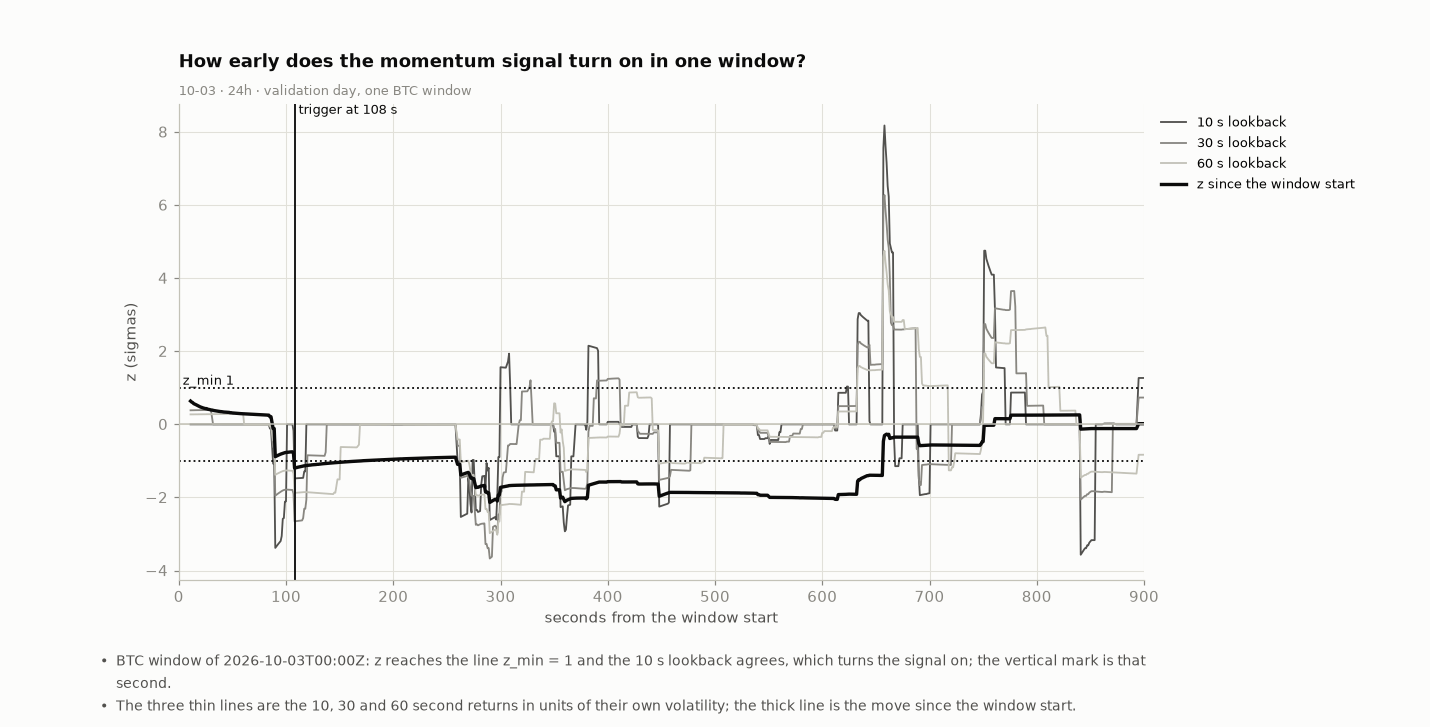

In [36]:
WINS_V, ENT_V = ST.figure_frames(VAL, CHOSEN)
PAN_V = ST.Panels(VAL, {"brownian": "logit", "logit": "logit", "table": f"table{CH['L']}"}[CH["map"]], ENT_V, CH["zmin"])
_w0 = ENT_V[ENT_V["asset"] == "btc"].sort_values("win_start_ms")
_w0 = _w0.iloc[0] if len(_w0) else ENT_V.sort_values("win_start_ms").iloc[0]
_p = PAN_V(_w0["asset"], int(_w0["win_start_ms"]))
_bul = [f"{_w0['asset'].upper()} window of {iso_(int(_w0['win_start_ms']))}: z reaches the line z_min = {CH['zmin']:g} and the {CH['L']} s lookback agrees, which turns the signal on; the vertical mark is that second.",
        "The three thin lines are the 10, 30 and 60 second returns in units of their own volatility; the thick line is the move since the window start."]
fig = FG.draw_signal(_p, "How early does the momentum signal turn on in one window?", f"{VAL_DAYS[0][5:]} · 24h · validation day, one {_w0['asset'].upper()} window", _bul)
figstyle.show(fig, "fig:s5-signal", FIGURES)

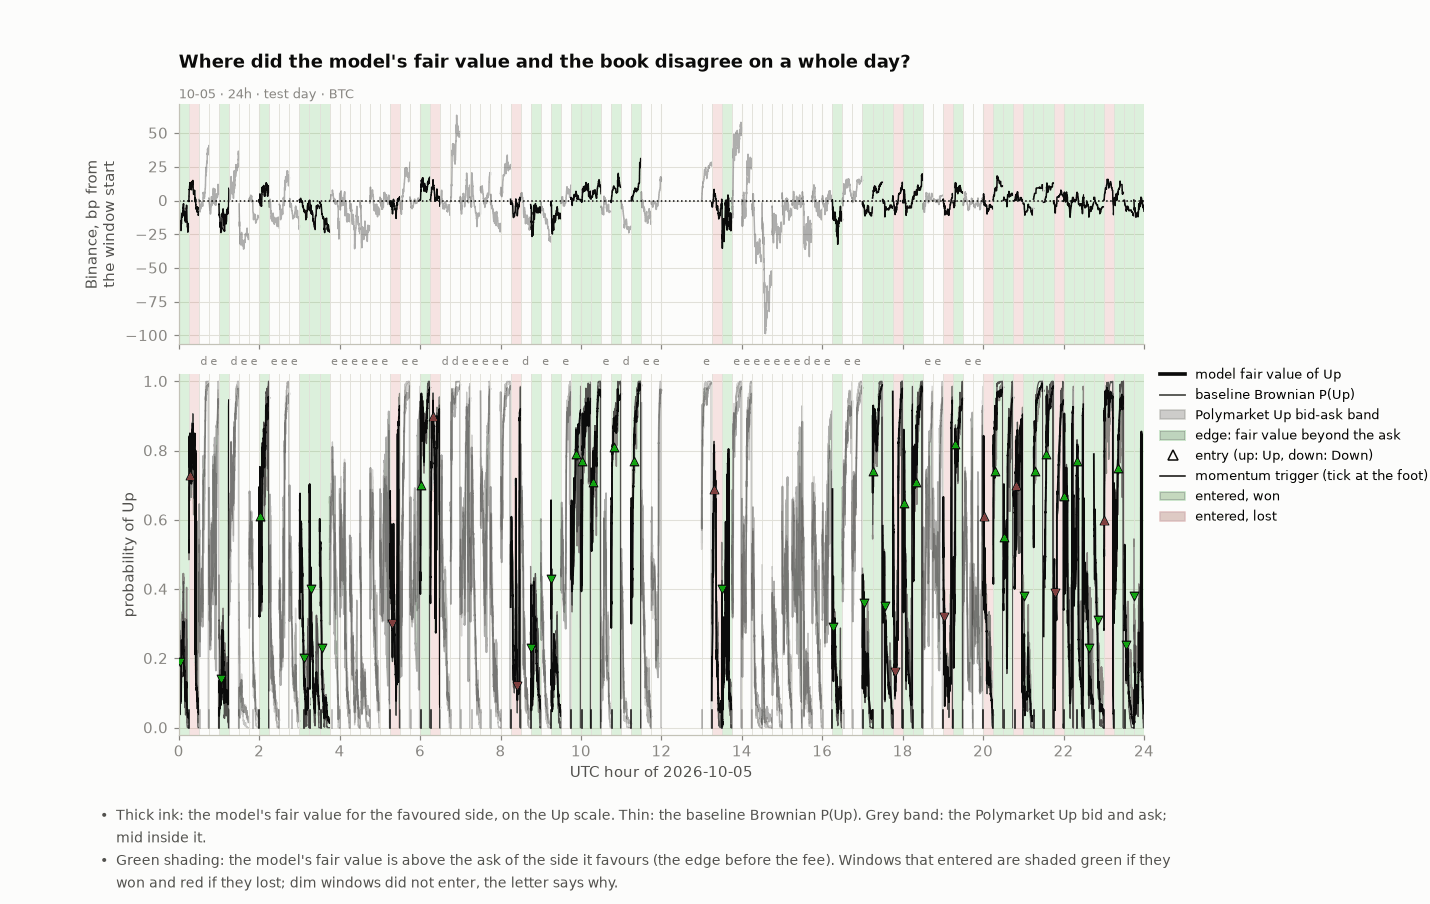

In [37]:
PAN_T = ST.Panels(TEST, {"brownian": "logit", "logit": "logit", "table": f"table{CH['L']}"}[CH["map"]], ENT_T, CH["zmin"])
_day = TEST_DAYS[0]
_dlo = D.day_start_ms(_day)
_wd = WINS_T[(WINS_T["win_start_ms"] >= _dlo) & (WINS_T["win_start_ms"] < _dlo + D.DAY_MS)]
_bul = ["Thick ink: the model's fair value for the favoured side, on the Up scale. Thin: the baseline Brownian P(Up). Grey band: the Polymarket Up bid and ask; mid inside it.",
        "Green shading: the model's fair value is above the ask of the side it favours (the edge before the fee). Windows that entered are shaded green if they won and red if they lost; dim windows did not enter, the letter says why."]
fig = FG.draw_day_strip(_day, "btc", _wd, ENT_T, PAN_T, "Where did the model's fair value and the book disagree on a whole day?", f"{_day[5:]} · 24h · test day · BTC", _bul)
figstyle.show(fig, "fig:s5-intraday", FIGURES)

C:\dev\fund\platform\research\studies\updown15_figs.py:201: RuntimeWarning: invalid value encountered in add
  mid = np.where(np.isfinite(best_bid) & np.isfinite(best_ask), (best_bid + best_ask) / 2, np.nan)


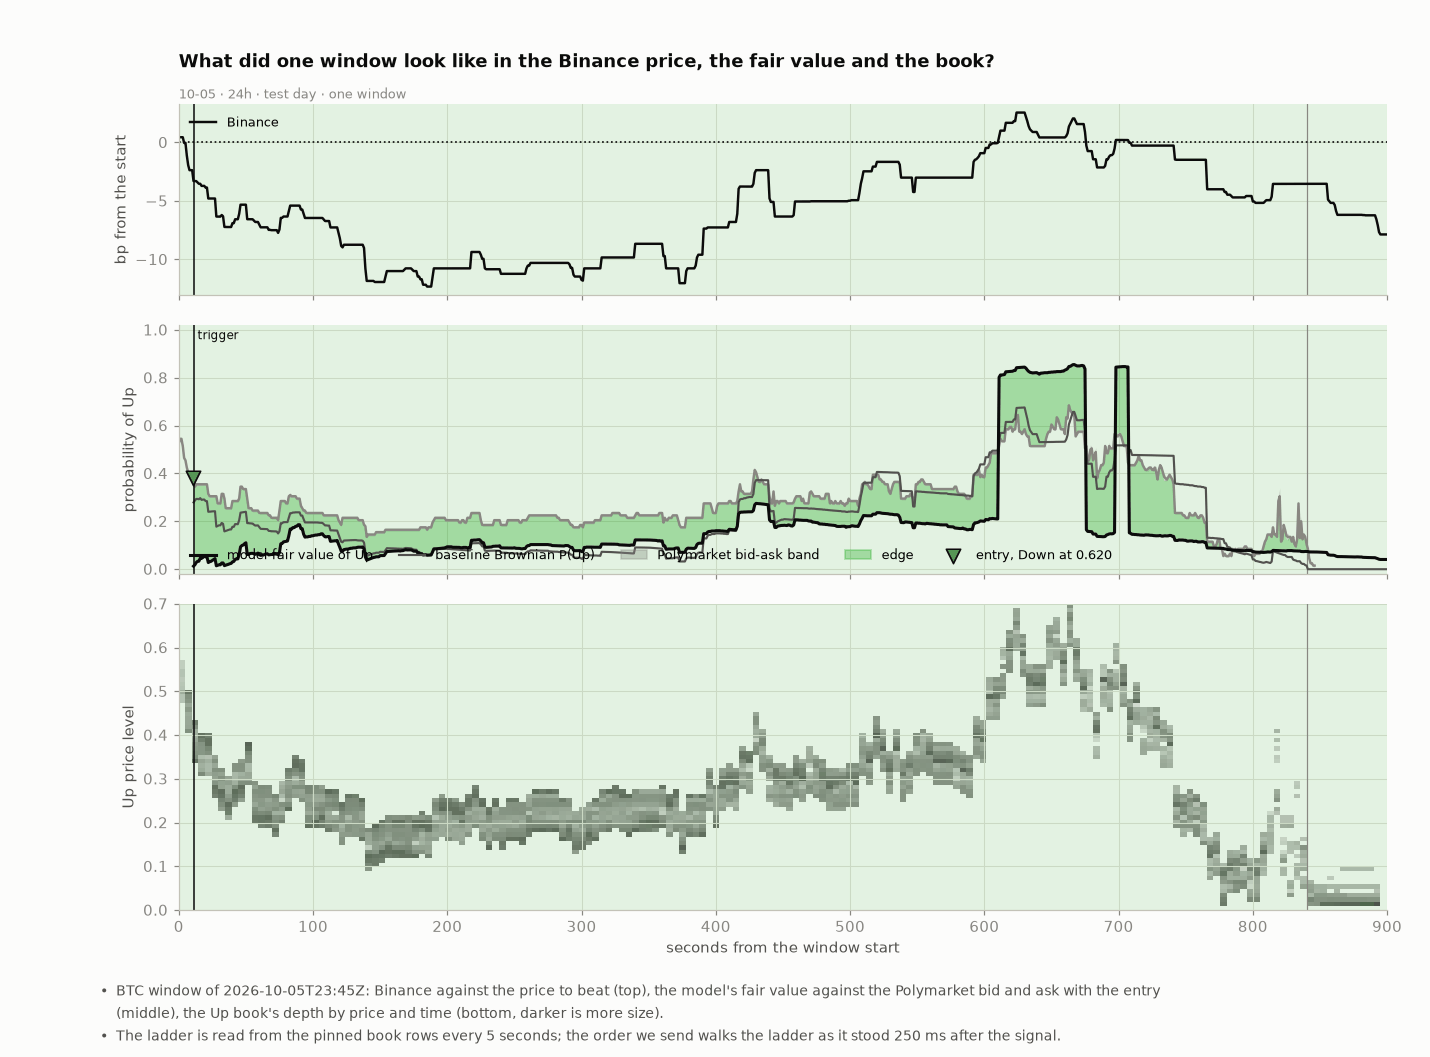

In [38]:
_e = ENT_T[ENT_T["asset"] == "btc"].sort_values("win_start_ms")
_pick = _e.iloc[len(_e) // 2] if len(_e) else WINS_T[WINS_T["asset"] == "btc"].iloc[0]
_wrow = WINS_T[(WINS_T["asset"] == _pick["asset"]) & (WINS_T["win_start_ms"] == _pick["win_start_ms"])].iloc[0]
_erow = ENT_T[(ENT_T["asset"] == _pick["asset"]) & (ENT_T["win_start_ms"] == _pick["win_start_ms"])]
_erow = _erow.iloc[0] if len(_erow) else None
_p = PAN_T(_pick["asset"], int(_pick["win_start_ms"]))
_bul = [f"{_pick['asset'].upper()} window of {iso_(int(_pick['win_start_ms']))}: Binance against the price to beat (top), the model's fair value against the Polymarket bid and ask with the entry (middle), the Up book's depth by price and time (bottom, darker is more size).",
        "The ladder is read from the pinned book rows every 5 seconds; the order we send walks the ladder as it stood 250 ms after the signal."]
fig = FG.draw_window(_pick["asset"], int(_pick["win_start_ms"]), _wrow, _erow, _p, "What did one window look like in the Binance price, the fair value and the book?", f"{_day[5:]} · 24h · test day · one window", _bul)
figstyle.show(fig, "fig:s5-window", FIGURES)

In [39]:
# ---- the interactive view (JupyterLab): a day and an asset dropdown, a window dropdown, a book-snapshot slider. It draws the SAME figures as the static pictures above from the
# ---- derived days in memory; it needs a live kernel, so in a saved notebook the pictures above are the Research room's copy of it.
_ENT_ALL = pd.concat([ENT_V, ENT_T], ignore_index=True)
_WINS_ALL = pd.concat([WINS_V, WINS_T], ignore_index=True)
PAN_ALL = ST.Panels(VAL + TEST, {"brownian": "logit", "logit": "logit", "table": f"table{CH['L']}"}[CH["map"]], _ENT_ALL, CH["zmin"])
W_BOX = FG.intraday_widget(list(VAL_DAYS + TEST_DAYS), list(ASSETS), _WINS_ALL, _ENT_ALL, PAN_ALL, f"{VAL_DAYS[0][5:]} to {TEST_DAYS[-1][5:]} · {4 * 24}h · validation then test", hour_label=lambda ms: iso_(ms)[11:16])
display(W_BOX)

### S5.4 · Outside the registered run: is there momentum from BEFORE the window?

A diagnostic, not part of `um-003` and never a signal in it. The question: does the direction of the previous quarter hour, hour or four hours say anything about the next window's recorded outcome? The reference is `A0`, the 60-second average at each window's start, known at that start; "the previous 15 minutes" is `A0` against the `A0` of the window before, and so on. Only these seven days are read (96 windows a day per asset, no gap), so each cell below rests on 250 to 400 windows and carries an interval of about plus or minus 5.5 points. Another reading of 88 days of index bars (outside this notebook) found a mild tilt towards reversal; this sample can neither confirm nor reject it. It stays a hypothesis for a later pre-registered bet.

In [40]:
_rows = []
for d in DAYS_HAVE:
    a_, m_ = DAY[d]
    for i in range(len(a_["w_start"])):
        _rows.append((ASSETS[int(a_["w_asset"][i])], int(a_["w_start"][i]), float(a_["w_a0"][i]), int(a_["w_up"][i])))
PRE = pd.DataFrame(_rows, columns=["asset", "start", "a0", "up"]).sort_values(["asset", "start"])
_out = []
for asset_, g_ in PRE.groupby("asset"):
    g_ = g_.reset_index(drop=True)
    assert (np.diff(g_["start"]) == 900_000).all(), "a gap in the window sequence"
    for name_, lag_ in (("previous 15 min", 1), ("previous hour", 4), ("previous 4 hours", 16)):
        r_ = np.log(g_["a0"] / g_["a0"].shift(lag_))
        d_ = pd.DataFrame({"r": r_, "up": g_["up"]}).dropna()
        for lab_, m2 in (("after Up", d_["r"] > 0), ("after Down", d_["r"] <= 0)):
            n_, k_ = int(m2.sum()), int(d_["up"][m2].sum())
            lo_, hi_ = ST.M.wilson(k_, n_)
            _out.append(dict(asset=asset_, horizon=name_, cond=lab_, n=n_, p=k_ / n_, lo=lo_, hi=hi_))
        _out.append(dict(asset=asset_, horizon=name_, cond="corr", n=len(d_), p=float(np.corrcoef(d_["r"], d_["up"])[0, 1]), lo=np.nan, hi=np.nan))
PREO = pd.DataFrame(_out)
_t = PREO[PREO["cond"] != "corr"]
display(Markdown("**Share of windows that resolved Up, by the direction before the window** (the number of windows in brackets; the sample is the seven days only)\n\n| Before the window | " + " | ".join(a.upper() for a in ASSETS) + " |\n|---|" + "---|" * len(ASSETS) + "\n" +
                 "\n".join(f"| {h}, {c} | " + " | ".join(f"{pct(_t[(_t.asset == a) & (_t.horizon == h) & (_t.cond == c)].p.iloc[0])} ({int(_t[(_t.asset == a) & (_t.horizon == h) & (_t.cond == c)].n.iloc[0])})" for a in ASSETS) + " |"
                           for h in ("previous 15 min", "previous hour", "previous 4 hours") for c in ("after Up", "after Down"))))
_c = PREO[PREO["cond"] == "corr"]
display(Markdown("**Correlation of the previous move's sign with the next outcome**\n\n| Horizon | " + " | ".join(a.upper() for a in ASSETS) + " |\n|---|" + "---|" * len(ASSETS) + "\n" +
                 "\n".join(f"| {h} | " + " | ".join(f"{_c[(_c.asset == a) & (_c.horizon == h)].p.iloc[0]:+.3f}" for a in ASSETS) + " |" for h in ("previous 15 min", "previous hour", "previous 4 hours"))))
PRE_MAXDEV = float(np.nanmax(np.abs(_t["p"] - 0.5)))
display(Markdown(f"Read: no cell is more than {PRE_MAXDEV * 100:.1f} points from 50% and the signs do not agree across assets or horizons; the assets are correlated with each other, so four columns are not four independent readings. On seven days this is consistent with no tilt at all, and it cannot contradict a tilt of 4 to 6 points: it has no power to. It is kept as a hypothesis, outside the registered run."))

**Share of windows that resolved Up, by the direction before the window** (the number of windows in brackets; the sample is the seven days only)

| Before the window | BTC | ETH | SOL | XRP |
|---|---|---|---|---|
| previous 15 min, after Up | 50.5% (331) | 49.6% (335) | 47.6% (351) | 44.3% (334) |
| previous 15 min, after Down | 49.7% (340) | 50.0% (336) | 55.6% (320) | 54.9% (337) |
| previous hour, after Up | 51.5% (373) | 50.4% (361) | 51.7% (358) | 48.0% (377) |
| previous hour, after Down | 48.5% (295) | 48.9% (307) | 51.0% (310) | 51.5% (291) |
| previous 4 hours, after Up | 53.7% (387) | 48.4% (384) | 48.9% (378) | 48.2% (365) |
| previous 4 hours, after Down | 45.7% (269) | 51.8% (272) | 54.0% (278) | 51.2% (291) |

**Correlation of the previous move's sign with the next outcome**

| Horizon | BTC | ETH | SOL | XRP |
|---|---|---|---|---|
| previous 15 min | +0.024 | +0.019 | -0.029 | -0.076 |
| previous hour | +0.049 | +0.036 | -0.011 | -0.073 |
| previous 4 hours | +0.017 | +0.021 | -0.039 | -0.020 |

Read: no cell is more than 5.7 points from 50% and the signs do not agree across assets or horizons; the assets are correlated with each other, so four columns are not four independent readings. On seven days this is consistent with no tilt at all, and it cannot contradict a tilt of 4 to 6 points: it has no power to. It is kept as a hypothesis, outside the registered run.

## S6 · Decision

| question | decision rule |
|---|---|
| If every earlier gate passed, would a size be earned, and does the book hold the clip? | a size only if G3, G4, G5, G7 and G8 PASS and G6 is not a FAIL (a FLAG on G6 means only the registered 1 s feature shift lacks power and the dose-response is clean); otherwise the verdict is NO SIZE and what follows is information only |

In [41]:
# ---- the fill reality: the depth we met at the fill instant, from the pinned ladders kept with each entry (the ladder as of t + 250 ms) ----
_x = E_TEST[E_TEST["status"] == "entered"]
_cap = []
for r_ in _x.itertuples():
    arrs_, _m = DAY[r_.day]
    px, sz = arrs_["f_px"][int(r_.fill)], arrs_["f_sz"][int(r_.fill)]
    ok = np.isfinite(px) & (px <= r_.ask_signal + 1e-9)
    _cap.append(float((px[ok] * sz[ok]).sum()))
CAPU = np.array(_cap)
CAP_MED = float(np.median(CAPU)) if len(CAPU) else np.nan
CAP_P10 = float(np.percentile(CAPU, 10)) if len(CAPU) else np.nan
display(Markdown("**Depth at or under the signal ask when the order arrived** (USD of the token we bought; the order is limited to the signal ask)\n\n| Measure | Value |\n|---|---|\n"
    f"| Median | {usd(CAP_MED)} |\n| 10th percentile | {usd(CAP_P10)} |\n" + "\n".join(f"| Entries with at least {usd(c_)} there | {pct((CAPU >= c_).mean(), 0) if len(CAPU) else 'n/a'} |" for c_ in (20, 50, 100, 200)) +
    f"\n| Fills that took more than one level | {pct((_x['levels'] > 1).mean(), 0) if len(_x) else 'n/a'} |\n| Fills under the USD 20 clip (partial) | {int(_x['partial'].sum())} of {len(_x)} |\n"
    f"| Average price paid against the signal ask | {(_x['vwap'] - _x['ask_signal']).mean() * 100:+.2f} cents |"))
SIZED = all(g["verdict"] == "PASS" for g in GATES if g["id"] in {"G3", "G4", "G5", "G7", "G8"}) and next(g["verdict"] for g in GATES if g["id"] == "G6") != "FAIL"
print(f"SIZED = {SIZED}: gates " + ", ".join(f"{g['id']} {g['verdict']}" for g in GATES))

**Depth at or under the signal ask when the order arrived** (USD of the token we bought; the order is limited to the signal ask)

| Measure | Value |
|---|---|
| Median | USD 72 |
| 10th percentile | USD 7 |
| Entries with at least USD 20 there | 73% |
| Entries with at least USD 50 there | 57% |
| Entries with at least USD 100 there | 48% |
| Entries with at least USD 200 there | 32% |
| Fills that took more than one level | 1% |
| Fills under the USD 20 clip (partial) | 43 of 157 |
| Average price paid against the signal ask | -0.25 cents |

SIZED = False: gates G1 PASS, G2 PASS, G3 FAIL, G4 FAIL, G5 FAIL, G6 FLAG, G7 FAIL, G8 FAIL


## S7 · Verdict

The gates, the conclusion and the manifest are rendered below from the run's own objects.

In [42]:
# ---- every read of the test days, against what the pre-registration allows ----
_allowed = {CHOSEN, BASE_CFG}
assert all(c_ in _allowed for c_, _w in TEST_READS), [r_ for r_ in TEST_READS if r_[0] not in _allowed]
display(Markdown("**Reads of the test days** (the pre-registration allows the chosen configuration and the baseline at its theta; each is logged)\n\n| Configuration | Why |\n|---|---|\n" + "\n".join(f"| `{c_}` | {w_} |" for c_, w_ in TEST_READS)))
VERIFY["passed"] += 1; VERIFY["total"] += 1
VERIFY["books"] = int(sum(DAY[d][0]["w_status"].tolist().count(0) for d in VAL_DAYS + TEST_DAYS))
FAILED = [g_ for g_ in GATES if g_["verdict"] == "FAIL"]
WORD = "NO SIZE" if (FAILED or not SIZED) else "1x"
print(WORD, [g_["id"] for g_ in FAILED])

**Reads of the test days** (the pre-registration allows the chosen configuration and the baseline at its theta; each is logged)

| Configuration | Why |
|---|---|
| `brownian|z1|L10|th0.06` | the chosen configuration |
| `brownian|z1|L10|th0.06` | the 5 s instants of the test days, for the probability scores |
| `baseline|th0.06` | the baseline at the chosen theta, for the comparison |
| `brownian|z1|L10|th0.06` | the latency pass of 2026-10-05 |
| `brownian|z1|L10|th0.06` | the latency pass of 2026-10-06 |
| `baseline|th0.06` | the baseline's latency and planted passes on the test days |

NO SIZE ['G3', 'G4', 'G5', 'G7', 'G8']


In [43]:
# ---- the conclusion, rendered from the run's own objects: no number is typed ----
_x = E_TEST[E_TEST["status"] == "entered"]
_t, _eq, _dd = ST.equity_curve(E_TEST, BOOK_USD)
DD_USD = float(_dd.min()) if len(_dd) else 0.0
TEST_HOURS = len(TEST_DAYS) * 24
HOLD_H = float(((D.WIN_S * 1000 - (_x["t_signal_off_ms"] + LATENCY_MS)) / 3.6e6).mean()) if len(_x) else float("nan")
_w, _l = _x[_x["won"]], _x[~_x["won"]]
PF = float(_w["pnl_net"].sum() / -_l["pnl_net"].sum()) if len(_l) and _l["pnl_net"].sum() < 0 else float("nan")
WLR = float(_w["pnl_net"].mean() / -_l["pnl_net"].mean()) if len(_w) and len(_l) and _l["pnl_net"].mean() < 0 else float("nan")
AVG_COST = float(_x["cost"].mean()) if len(_x) else float("nan")
EXPOSURE = float((_x["cost"] * (D.WIN_S * 1000 - (_x["t_signal_off_ms"] + LATENCY_MS)) / 3.6e6).sum() / (BOOK_USD * TEST_HOURS) * 100) if len(_x) else 0.0
GROSS_BP = float(_x["pnl_gross"].mean() / AVG_COST * 1e4) if len(_x) else float("nan")
FEE_BP = float(_x["fee_usd"].mean() / AVG_COST * 1e4) if len(_x) else float("nan")
EXP_BP = float(_x["pnl_net"].mean() / AVG_COST * 1e4) if len(_x) else float("nan")
WORST_DAY = float(DY["net"].min()) if len(DY) else 0.0
sentences = [
    f"**{WORD}.** " + (f"On the two test days `{CHOSEN}` entered {TS['n']:,} times, won {pct(TS['win_rate'])} of them against a break-even of {pct(TS['be'])} (Wilson {pct(TS['lo'])} to {pct(TS['hi'])}), "
                       f"and made {sgn(TS['net'], 0)} USD after the fee ({sgn(TS['gross'], 0)} before; fees {usd(TS['fee'])})." if TS["n"] else "The chosen configuration made no entry on the test days."),
    f"The win rate is {TS['win_minus_be_pp']:+.1f} percentage points from break-even at an average price of {TS['avg_px']:.3f}: the fills are priced close to the probability of winning, so the edge a momentum signal finds is small against the price and the fee." if TS["n"] else "",
    f"Against the same fills the baseline with no gate nets {sgn(SB['per_entry'], 2)} USD per entry, the favourite by the mid {sgn(B_FAV['per_entry'], 2)}, random entries {sgn(float(np.nanmean(RND_PER)), 2)}; the chosen rule nets {sgn(TS['per_entry'], 2)}.",
    f"The momentum probability's Brier at the triggered test instants is {DIFF:+.4f} against the Polymarket mid's (95% {DLO:+.4f} to {DHI:+.4f}).",
    f"The no-gate baseline at the same theta, which the registered rule did not choose, netted {sgn(SB['per_entry'], 2)} USD per entry on {SB['n']} test entries ({sgn(SB['net'], 0)} USD; per-entry interval {sgn(CI_B[0], 2)} to {sgn(CI_B[1], 2)}) and {sgn(SBV['per_entry'], 2)} on the validation days: a lead for the next bet, not an edge.",
    f"The planted tests: {sum(int(r['passed']) for r in PL_ROWS)} of {N_PL} behave as they must; the look-ahead probe passed on {CAUS_N} windows with the planted future read caught on each.",
    f"Binance leads the Polymarket mid by {', '.join(f'{a.upper()} {LAG_PEAK[a]:+d} ms' for a in ASSETS)} at the correlation peak; a 250 ms order reaches a book that has typically moved part of the way, and in {pct(ADV['first_gone_share'], 0)} of the windows with a trigger an order found the ask gone first.",
    f"This is {len(DAYS_ALL)} days in one regime with two test days and {N_TRIALS} trials on the validation pair: the intervals are wide, a pass would be one result and not an expectation, and a fail is also only this window's.",
]
display(Markdown("\n\n".join(s for s in sentences if s)))
FAIL_IDS = [g_["id"] for g_ in GATES if g_["verdict"] == "FAIL"]
VERDICT = {"word": WORD, "why": [f"{g_['label']}: {g_['reading']}"[:110] for g_ in FAILED[:3]] or ["every S3 and S4 gate passed"],
           "next_bet": "the no-gate Brownian-edge rule at theta 0.06 on the next three complete days: net per entry above zero",
           "next": {"metric": "net PnL per entry of the no-gate Brownian-edge rule at theta 0.06, USD", "predict": "above zero", "window": "the three complete days after 2026-10-06"}}
display(Markdown("**What would change it.** (1) More days: the intervals here are two days wide. (2) A real Binance book (top of book and depth) in place of the trade-implied mid. (3) A better read of the Chainlink stream the market resolves on than the Binance average. (4) A cheaper fee tier. "
                 "**What could mislead us.** One regime; two test days; 138 trials on two validation days; a book archive that is a vendor's reconstruction; no queue position (we only lift) and no re-validation effect beyond the ladder at t + 250 ms."))

**NO SIZE.** On the two test days `brownian|z1|L10|th0.06` entered 157 times, won 73.2% of them against a break-even of 72.2% (Wilson 65.8% to 79.6%), and made -21 USD after the fee (+34 before; fees USD 55).

The win rate is +1.0 percentage points from break-even at an average price of 0.708: the fills are priced close to the probability of winning, so the edge a momentum signal finds is small against the price and the fee.

Against the same fills the baseline with no gate nets +1.51 USD per entry, the favourite by the mid -0.00, random entries -1.78; the chosen rule nets -0.14.

The momentum probability's Brier at the triggered test instants is +0.0007 against the Polymarket mid's (95% -0.0011 to +0.0026).

The no-gate baseline at the same theta, which the registered rule did not choose, netted +1.51 USD per entry on 483 test entries (+730 USD; per-entry interval -0.36 to +3.38) and +0.96 on the validation days: a lead for the next bet, not an edge.

The planted tests: 7 of 8 behave as they must; the look-ahead probe passed on 56 windows with the planted future read caught on each.

Binance leads the Polymarket mid by BTC +200 ms, ETH +200 ms, SOL +200 ms, XRP +200 ms at the correlation peak; a 250 ms order reaches a book that has typically moved part of the way, and in 68% of the windows with a trigger an order found the ask gone first.

This is 7 days in one regime with two test days and 138 trials on the validation pair: the intervals are wide, a pass would be one result and not an expectation, and a fail is also only this window's.

**What would change it.** (1) More days: the intervals here are two days wide. (2) A real Binance book (top of book and depth) in place of the trade-implied mid. (3) A better read of the Chainlink stream the market resolves on than the Binance average. (4) A cheaper fee tier. **What could mislead us.** One regime; two test days; 138 trials on two validation days; a book archive that is a vendor's reconstruction; no queue position (we only lift) and no re-validation effect beyond the ladder at t + 250 ms.

In [44]:
# ---- the research summary card ----
GID = {g_["label"]: g_["id"] for g_ in GATES}
GVD = {g_["label"]: g_["verdict"] for g_ in GATES}
def mk(metric, value, bar="", verdict="", gate=None):
    r_ = {"metric": metric, "value": value, "bar": bar, "verdict": GVD[gate] if gate else verdict}
    if gate:
        r_["gate"] = GID[gate]
    return r_
_cut = lambda s, n: s if len(s) <= n else s[: n - 1].rstrip() + "."
CARD = {
    "question": _cut("Does a Binance momentum trigger win more often than the break-even win rate of its Polymarket 15-minute fills, after the fee?", 200),
    "answer": _cut(f"{WORD}. Test days: {TS['n']} entries won {pct(TS['win_rate'])} against a break-even of {pct(TS['be'])}; net {sgn(TS['net'], 0)} USD after the fee. {len(FAIL_IDS)} of {len(GATES)} gates fail." if TS["n"] else f"{WORD}. No entries on the test days.", 240),
    "implementation": [("Trade", _cut("Buy the side of a big, agreed move at the ask, hold to expiry", 70)), ("Venue", "Polymarket 15m Up/Down; Binance trades are input"), ("Rule", _cut(f"z >= {CH['zmin']:g}, {CH['L']} s agrees, edge over {CH['theta']:g}, {CH['map']} map", 70)),
                       ("Size", f"{usd(CLIP_USD)} a trade, {usd(BOOK_USD)} book, 1x"), ("Costs", _cut(f"taker fee {FEE_RATE:g} x p(1-p) [API], ladder walked at +250 ms", 70)), ("Window", f"{DAYS_ALL[0][5:]} to {DAYS_ALL[-1][5:]}, {len(DAYS_ALL) * 24}h, 1 regime")],
    "big": [dict(mk("Win rate, test", pct(TS["win_rate"]), f"break-even {pct(TS['be'])}", gate="Win beats break-even"), scope="paper"),
            dict(mk("Net after the fee", f"{sgn(TS['net'], 0)} USD", f"{TS['n']} entries", gate="Net per entry above zero"), scope="paper"),
            dict(mk("Net per entry", f"{sgn(TS['per_entry'], 2)} USD", f"95% {sgn(CI_PER[0], 2)} to {sgn(CI_PER[1], 2)}", gate="Net per entry above zero"), scope="paper"),
            dict(mk("Brier vs the mid", f"{DIFF:+.4f}", "below 0 wins", gate="Beats the market's mid"), scope="paper")],
    "blocks": [
        {"title": "Win rate against price", "rows": [mk("Win rate", pct(TS["win_rate"]), f"Wilson {pct(TS['lo'])} to {pct(TS['hi'])}"), mk("Break-even win rate", pct(TS["be"]), ""), mk("Win minus break-even", f"{TS['win_minus_be_pp']:+.1f} pp", "above 0", gate="Win beats break-even"),
                                           mk("Average price paid", f"{TS['avg_px']:.3f}", "")]},
        {"title": "PnL, USD", "rows": [mk("Before the fee", sgn(TS["gross"], 0), ""), mk("Taker fees", usd(TS["fee"]), ""), mk("After the fee", sgn(TS["net"], 0), "above 0", gate="Net per entry above zero"),
                                       mk("Deepest drawdown", sgn(DD_USD, 0), f"book {usd(BOOK_USD)}"), mk("Worst day", sgn(WORST_DAY, 0), "")]},
        {"title": "Against the same fills", "rows": [mk("No-gate baseline, per entry", sgn(SB["per_entry"], 2), ""), mk("Favourite by the mid, per entry", sgn(B_FAV["per_entry"], 2), ""), mk("Random entries, per entry", sgn(float(np.nanmean(RND_PER)), 2), ""),
                                                      mk("Chosen rule, per entry", sgn(TS["per_entry"], 2), "beats all", gate="Beats the same fills")]},
        {"title": "Checks", "rows": [mk("Planted tests passed", f"{sum(int(r['passed']) for r in PL_ROWS)} of {N_PL}", "", gate="Planted tests behave"), mk("Look-ahead probes", f"{CAUS_N} of {CAUS_N}", "all equal"),
                                      mk("Reference match", pct(CONV_ALL), "95% bar", gate="Reference matches"), mk("Net at 2x the fee", sgn(FEE_ROWS[-1][1], 0), "above 0")]},
        {"title": "Fills and the 250 ms", "rows": [mk("Ask gone before an entry", pct(ADV["first_gone_share"], 0), ""), mk("Mean ask move at 250 ms", f"{ADV['mean_move_250_c']:+.2f} c", ""), mk("Median depth at the ask", usd(CAP_MED), f"clip {usd(CLIP_USD)}"),
                                         mk("Fills under the clip", f"{TS['partial']} of {TS['n']}", "")]}],
    "sizes": {"cols": ["Size", "Net, USD", "Per entry", "Verdict"], "chosen": None if WORD == "NO SIZE" else 0,
              "rows": [[("1x" if WORD != "NO SIZE" else "1x, info only"), sgn(TS["net"], 0), sgn(TS["per_entry"], 2), "PASS" if SIZED else "FAIL"]]},
    "footer": [_cut(f"Next bet: the no-gate Brownian-edge rule at theta 0.06 on the next three complete days; net per entry above zero.", 160),
               _cut(f"Registered as {RUN_ID} before any run of this design; {N_TRIALS} trials on {len(VAL_DAYS)} validation days.", 160),
               _cut(f"{len(DAYS_ALL) * 24}h of one regime, {len(TEST_DAYS)} test days: wide intervals, one result, no queue modelled, {VERIFY['passed']}/{VERIFY['total']} checks.", 160)],
}
if WORD == "NO SIZE":
    CARD["sizes"]["rows"][0][0] = "1x info only"
assert not REPORT.card_problems(CARD, carry=False), REPORT.card_problems(CARD, carry=False)

In [45]:
# ---- the study manifest fund.study/1 (directional format, systematic style) ----
STUDY_GATES = [{k_: g_[k_] for k_ in ("id", "section", "name", "label", "reading", "verdict", "would_change")} for g_ in GATES]
RUN_AT = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
NA = {k_: "two test days: an annualised or daily-return ratio is not meaningful" for k_ in ("ann_return_pct", "excess_vs_hurdle_pct", "ann_vol_pct", "sharpe", "sortino", "calmar", "psr", "dsr")}
NA["beta_to_underlying"] = "four assets in one binary payoff: no single underlying"
METRICS = {"ann_return_pct": None, "excess_vs_hurdle_pct": None, "ann_vol_pct": None, "sharpe": None, "sortino": None, "calmar": None, "psr": None, "dsr": None,
           "max_dd_pct": DD_USD / BOOK_USD * 100, "max_dd_days": float(len(TEST_DAYS)), "n_periods": float(len(TEST_DAYS)), "periods_per_year": 365.0,
           "total_return_pct": TS["net"] / BOOK_USD * 100, "n_trades": float(TS["n"]), "trades_per_day": TS["n"] / len(TEST_DAYS), "hit_rate_pct": TS["win_rate"] * 100 if TS["n"] else None,
           "profit_factor": PF, "expectancy_bps": EXP_BP, "win_loss_ratio": WLR, "avg_hold_h": HOLD_H, "exposure_pct": EXPOSURE,
           "turnover_ann": float(_x["cost"].sum() / len(TEST_DAYS) * 365 / BOOK_USD) if len(_x) else None, "fees_pct_of_gross": float(TS["fee"] / abs(TS["gross"]) * 100) if TS["gross"] else None,
           "worst_period_pct": WORST_DAY / BOOK_USD * 100, "gross_edge_bps": GROSS_BP, "cost_bps": FEE_BP, "breakeven_cost_bps": GROSS_BP, "capacity_usd": CAP_MED, "beta_to_underlying": None}
for k_, v_ in list(METRICS.items()):
    if v_ is None or (isinstance(v_, float) and not math.isfinite(v_)):
        METRICS[k_] = None
        NA.setdefault(k_, "no entry or no loss on the test days")
PROFILE = {"market": "predmkts", "markets": ["predmkts", "crypto"], "venues": ["polymarket", "binance"], "instruments": ["BTC 15m Up/Down", "ETH 15m Up/Down", "SOL 15m Up/Down", "XRP 15m Up/Down"], "bar": "15m"}
COMPONENTS = [{"name": "PnL before the fee", "usd": float(TS["gross"])}, {"name": "taker fees", "usd": -float(TS["fee"])}]
assert abs(sum(c_["usd"] for c_ in COMPONENTS) - TS["net"]) < 0.01, "the PnL parts do not add to the net"
FIG_KINDS = {"fig:s2-leadlag": "signal-decay", "fig:s3-equity": "equity-curve", "fig:s3-assets": "equity-curve", "fig:s3-breakeven": "calibration", "fig:s3-calibration": "calibration",
             "fig:s4-benchmarks": "rule-comparison", "fig:s5-reasons": "sample-funnel-and-coverage", "fig:s5-trigger-hour": "sample-funnel-and-coverage", "fig:s5-entry-rate": "sample-funnel-and-coverage",
             "fig:s5-signal": "trade-anatomy", "fig:s5-intraday": "trade-anatomy", "fig:s5-window": "trade-anatomy"}
assert {f_["id"] for f_ in FIGURES} <= set(FIG_KINDS), [f_["id"] for f_ in FIGURES if f_["id"] not in FIG_KINDS]
for f_ in FIGURES:
    f_["kind"] = FIG_KINDS[f_["id"]]
CAVEATS = ["one regime, seven days, two test days: a result here is one observation", f"{N_TRIALS} trials on two validation days: the best cell is likely flattered",
           "the book is a vendor's reconstruction of the venue's stream (PendulumFlow, v3)", "no Binance quote: the mid is trade-implied; Chainlink is not Binance",
           "we only lift: no queue, no rebate; the ladder as of t + 250 ms stands in for the venue's re-validation", f"{N_SMOKE} windows seen in an engine smoke test are excluded from the test",
           "the favourite and random benchmarks fill at the best ask without a depth walk", "a late first snapshot makes a thin market's window unusable, counted by day"]
assert all(len(c_) <= 110 for c_ in CAVEATS), [len(c_) for c_ in CAVEATS]
HEADLINE = {"metric": "win rate minus break-even, pp", "label": "Win vs breakeven", "value": float(TS["win_minus_be_pp"]) if TS["n"] else 0.0, "unit": "pp", "hurdle": 0.0, "gate": GID["Win beats break-even"]}
EQ = [(dt.datetime.fromtimestamp(int(t_) / 1000, dt.timezone.utc), float(e_)) for t_, e_ in zip(_t, _eq)] or [(dt.datetime.fromtimestamp(ms_(TEST_DAYS[0] + "T00:00:00Z") / 1000, dt.timezone.utc), BOOK_USD)]
BASEDAYS = list(DAYS_ALL)
INPUTS = RUN.inputs_block(BASEDAYS, BLOB)
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind=KIND, desk=DESK, title=TITLE, question=QUESTION, status="registered", run={"executed": RUN_AT, "kernel": "ccvenv"}, inputs=INPUTS,
    window={"from": f"{DAYS_ALL[0]}T00:00Z", "to": f"{(dt.date.fromisoformat(DAYS_ALL[-1]) + dt.timedelta(days=1)).isoformat()}T00:00Z", "hours": len(DAYS_ALL) * 24, "regimes": 1},
    verify={"suite": VERIFY["suite"], "passed": VERIFY["passed"], "total": VERIFY["total"], "books": VERIFY["books"]}, gates=STUDY_GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline=HEADLINE, components=COMPONENTS, summary=CARD, format="directional", style="systematic", metrics=METRICS, na=NA,
    strategy={"name": "15m Up/Down momentum lift", "thesis": "a large, agreed move since the window start keeps going to the end more often than its price implies", "market": "prediction markets",
              "instruments": ["BTC", "ETH", "SOL", "XRP"], "venues": ["Polymarket", "Binance (input)"], "style": "momentum"},
    rules={"entry": f"z >= {CH['zmin']:g}, {CH['L']} s agrees, P - ask - fee > {CH['theta']:g}", "exit": "none: hold to expiry, paid 1 or 0", "sizing": f"{usd(CLIP_USD)} a trade", "rebalance": None, "hedge": None,
           "hold": "to the end of the 15-minute window", "stop": None, "cost": f"taker fee {FEE_RATE:g} x p x (1-p); ladder at +{LATENCY_MS} ms"},
    params={"clip": {"value": CLIP_USD, "unit": "usd", "source": "owner"}, "latency_ms": {"value": float(LATENCY_MS), "unit": "ms", "source": "owner"}, "z_min": {"value": float(CH["zmin"]), "unit": "sd", "source": "[U]"},
            "theta": {"value": float(CH["theta"]), "unit": "prob", "source": "[U]"}, "fee_rate": {"value": FEE_RATE, "unit": "rate", "source": "[API]"}},
    equity=EQ, profile=PROFILE, book=None)
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 8 gates, 12 figures, verdict NO SIZE

## A · Appendix

The whole grid on the validation days (every configuration, not the best cell; it appears once the validation days are derived), and the day-by-day audit of the derived days.

In [46]:
_g = GRID.copy()
_g["win_rate"] = (_g["win_rate"] * 100).round(1); _g["be"] = (_g["be"] * 100).round(1)
display(HTML(_g[["cfg", "n", "win_rate", "be", "win_minus_be_pp", "avg_px", "per_entry", "net"]].rename(columns={"n": "entries", "win_rate": "win %", "be": "break-even %", "win_minus_be_pp": "win - be, pp", "avg_px": "avg price", "per_entry": "net per entry", "net": "net total"}).round(3).to_html(index=False, border=0)))
display(Markdown("**Derived days and their audit**"))
display(HTML(INV.to_html(index=False, border=0, na_rep="")))
display(Markdown("**The log of every entry, test days, the chosen rule** (times in ms from the window start; `book_row_at_td_ms` is the venue time of the ladder row read at the decision, `book_row_at_fill_ms` the row the order hit)"))
display(HTML(ENTRY_LOG.to_html(index=False, border=0)))
display(Markdown("**The first trigger of every window that had one, test days**"))
display(HTML(FT[["asset", "t_d_utc", "into_s", "left_s", "first_book_age_ms", "first_ask_signal", "first_ask_at_fill", "status"]].round(3).to_html(index=False, border=0)))

cfg,entries,win %,break-even %,"win - be, pp",avg price,net per entry,net total
baseline|th0,721,45.9,49.6,-3.720,0.479,-1.129,-814.126
baseline|th0.03,718,47.1,50.4,-3.367,0.488,-0.961,-689.992
baseline|th0.06,624,53.5,51.0,2.544,0.495,0.956,596.393
brownian|z0.5|L10|th0,691,65.7,66.7,-0.954,0.652,-0.053,-36.730
brownian|z0.5|L10|th0.03,541,69.5,68.8,0.711,0.674,0.416,225.257
brownian|z0.5|L10|th0.06,346,73.1,70.3,2.781,0.689,0.789,273.131
brownian|z0.5|L30|th0,692,65.0,65.7,-0.676,0.642,-0.033,-22.980
brownian|z0.5|L30|th0.03,552,69.0,68.4,0.600,0.670,0.169,93.559
brownian|z0.5|L30|th0.06,356,73.0,69.5,3.553,0.681,0.915,325.879
brownian|z0.5|L60|th0,695,63.9,65.3,-1.427,0.638,-0.283,-196.462


**Derived days and their audit**

day,role,markets,ok,no_book,binance_gap,config_rows,bytes,code,seconds
2026-09-30,fit,384,,,,,2334937,run-2026-10-07f,10.6
2026-10-01,fit,384,,,,,2292417,run-2026-10-07f,8.0
2026-10-02,fit,384,,,,,2352914,run-2026-10-07f,8.9
2026-10-03,book,384,361.0,21.0,2.0,49818.0,12931466,run-2026-10-07f,123.0
2026-10-04,book,384,360.0,22.0,2.0,49680.0,14809269,run-2026-10-07f,94.1
2026-10-05,book,384,365.0,19.0,0.0,50370.0,20743699,run-2026-10-07f,143.2
2026-10-06,book,384,356.0,28.0,0.0,49128.0,18939900,run-2026-10-07f,138.7


**The log of every entry, test days, the chosen rule** (times in ms from the window start; `book_row_at_td_ms` is the venue time of the ladder row read at the decision, `book_row_at_fill_ms` the row the order hit)

asset,window,t_d_utc,into_s,left_s,side,book_row_at_td_ms,book_age_ms,book_row_at_fill_ms,ask_signal,ask_at_fill,levels,avg_price,shares,fee_usd,won,net_usd
BTC,10-05T00:00,10-05 00:01:22.810,82.8,817.2,Down,82806,4,83060,0.81,0.81,1,0.8100,24.690001,0.2660,True,4.430000
BTC,10-05T00:15,10-05 00:17:09.456,129.5,770.5,Up,129456,0,129701,0.73,0.73,1,0.7300,27.389999,0.3779,False,-20.370001
SOL,10-05T00:00,10-05 00:01:22.182,82.2,817.8,Down,82177,5,82409,0.73,0.71,1,0.7100,28.160000,0.4059,True,7.760000
BTC,10-05T08:15,10-05 08:25:04.527,604.5,295.5,Down,604527,0,604777,0.88,0.88,1,0.8800,22.719999,0.1680,False,-20.160000
BTC,10-05T08:45,10-05 08:45:58.940,58.9,841.1,Down,58159,781,58159,0.77,0.77,1,0.7700,25.969999,0.3220,True,5.650000
BTC,10-05T16:15,10-05 16:16:35.443,95.4,804.6,Down,95442,1,95693,0.71,0.71,1,0.7100,15.000000,0.2162,True,4.130000
ETH,10-05T16:15,10-05 16:16:34.623,94.6,805.4,Down,94396,227,94824,0.72,0.72,1,0.7200,6.850000,0.0967,True,1.820000
BTC,10-05T20:00,10-05 20:00:42.288,42.3,857.7,Up,42288,0,42538,0.61,0.61,1,0.6100,32.779999,0.5459,False,-20.540001
BTC,10-05T20:15,10-05 20:17:01.139,121.1,778.9,Up,121137,2,121389,0.74,0.74,1,0.7400,5.000000,0.0673,True,1.230000
BTC,10-05T20:30,10-05 20:31:00.548,60.5,839.5,Up,60548,0,60798,0.56,0.55,1,0.5500,36.360001,0.6299,True,15.730000


**The first trigger of every window that had one, test days**

asset,t_d_utc,into_s,left_s,first_book_age_ms,first_ask_signal,first_ask_at_fill,status
btc,10-05 00:01:16.287,76.287,823.713,2,0.79,0.80,entered
btc,10-05 00:17:09.456,129.456,770.544,0,0.73,0.73,entered
btc,10-05 00:39:38.116,578.116,321.884,0,0.87,0.89,ask_gone
eth,10-05 00:01:07.720,67.720,832.280,0,0.70,0.72,ask_gone
sol,10-05 00:01:22.182,82.182,817.818,5,0.73,0.71,entered
xrp,10-05 00:00:53.035,53.035,846.965,0,0.58,0.66,ask_gone
xrp,10-05 00:45:34.600,34.600,865.400,1,0.54,0.70,ask_gone
eth,10-05 04:16:13.750,73.750,826.250,0,0.55,0.63,ask_gone
xrp,10-05 04:00:57.256,57.256,842.744,10,0.52,0.60,ask_gone
btc,10-05 08:25:04.527,604.527,295.473,0,0.88,0.88,entered


## Research summary

In [47]:
display(HTML(summary_card.render(CARD, carry=False)))
SUMMARY_ROWS = [("Question", QUESTION), ("Answer", CARD["answer"]), ("Window", f"{DAYS_ALL[0]} to {DAYS_ALL[-1]}, {len(DAYS_ALL) * 24} h, one regime; fit {len(FIT_DAYS)} d, validate {len(VAL_DAYS)} d, test {len(TEST_DAYS)} d"),
                ("Chosen", f"`{CHOSEN}`, from {N_TRIALS} trials on the validation days"), ("Win vs break-even", f"{pct(TS['win_rate'])} against {pct(TS['be'])} ({TS['win_minus_be_pp']:+.1f} pp)" if TS["n"] else "no entries"),
                ("Sizing", "NO SIZE: information only" if WORD == "NO SIZE" else "1x, paper"), ("Registered", f"{RUN_ID} on lab/predmkts, before any run of this design")]
display(Markdown("| | |\n|---|---|\n" + "\n".join(f"| **{a}** | {b} |" for a, b in SUMMARY_ROWS)))
display(Markdown("**Gates**\n\n| Gate | Verdict |\n|---|---|\n" + "\n".join(f"| {g_['id']} {g_['label']}: {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))

Size,"Net, USD",Per entry,Verdict
1x info only,-21,-0.14,FAIL


| | |
|---|---|
| **Question** | On Polymarket's 15-minute Up/Down markets, does a Binance momentum trigger with a calibrated probability win more often than the break-even win rate of its fills, after the taker fee, when it lifts the ask 250 ms after the signal and holds to expiry? |
| **Answer** | NO SIZE. Test days: 157 entries won 73.2% against a break-even of 72.2%; net -21 USD after the fee. 5 of 8 gates fail. |
| **Window** | 2026-09-30 to 2026-10-06, 168 h, one regime; fit 3 d, validate 2 d, test 2 d |
| **Chosen** | `brownian|z1|L10|th0.06`, from 138 trials on the validation days |
| **Win vs break-even** | 73.2% against 72.2% (+1.0 pp) |
| **Sizing** | NO SIZE: information only |
| **Registered** | um-003 on lab/predmkts, before any run of this design |

**Gates**

| Gate | Verdict |
|---|---|
| G1 Reference matches: 99.2% of 1,140 fit-day windows (the snapshot reading: 93.2%) | **PASS** |
| G2 Binance leads the book: BTC +200 ms, ETH +200 ms, SOL +200 ms, XRP +200 ms | **PASS** |
| G3 Win beats break-even: win 73.2% [65.8%, 79.6%] vs break-even 72.2% | **FAIL** |
| G4 Net per entry above zero: -0.14 USD per entry, 95% -2.01 to +1.69 | **FAIL** |
| G5 Beats the market's mid: +0.0007 Brier [-0.0011, +0.0026] | **FAIL** |
| G6 Planted tests behave: 7 of 8 planted checks as they must; dose-response of the future shift clean (15 s: +2.2 SE) | **FLAG** |
| G7 Beats the same fills: -0.14 vs baseline +1.51, favourite -0.00, random -1.78 | **FAIL** |
| G8 Survives the fee: -21 USD at 1.0x; first multiple at or below zero: 1.0 | **FAIL** |